# Cause-specific Cox cho first observed numeric 90+ — Freddie Mac Sample 2015

**COX_PH_v3 — nghiên cứu nội bộ, revision P1–P6**  
Phạm vi OBSERVED; broader competing exit RA/ZB; quy tắc $L<t\le T$ và ưu tiên Cause 2 cùng tháng được giữ.

Notebook này chạy từ raw, học preprocessing/knots và chọn đặc tả chỉ trên original train với 3-fold internal validation. Baseline A tuyến tính được giữ làm comparator; B bổ sung FICO RCS; C thử thêm LTV/UPB Cause 2. Time effects chỉ được giữ nếu đạt các tiêu chí thống kê, magnitude và OOF đã khóa. Không dùng legacy test để chọn model.

Các kết quả sau bước khóa đặc tả là **đánh giá mô tả trên reused internal holdout**, không phải pristine/external validation. Final model là working specification có giới hạn PH; không dự báo lifetime default/loss, không diễn giải nhân quả. Quyền chọn đặc tả và chuyển stage đã được researcher ủy quyền trong execution-policy update.

Chạy lại bằng `python src/reproduce.py` để execute toàn notebook, chạy tests, xuất HTML và verification đồng bộ. Notebook không đọc fitted bundle cũ để tính kết quả. Original baseline được giữ nguyên tại `artifacts/baseline_bundle.pkl` và commit `4b31e25bb55bca89fdb9aca683c4c26031b36c04`.

In [1]:
import os, sys, json, pickle, hashlib, platform
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p/'src/preprocessing.py').exists())
sys.path.insert(0,str(ROOT/'src'))
from preprocessing import (SEED, audit_sources, build_cohort, split_loans, Encoder, sha256)
from cox_model import (fit_models, predict_cif, fit_cause, fit_time_varying,
                       model_design, reference_rows, hazard_contrasts)
from evaluation import (aalen_johansen, diagnostics, functional_form_scores, validate,
                        concordance, concordance_bootstrap, landmark_sample, functional_experiments,
                        time_experiments, individual_predictions)
pd.set_option('display.max_columns',14)
pd.set_option('display.max_rows',40)
sns.set_theme(style='whitegrid',context='notebook',font='DejaVu Sans')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':220,'axes.spines.top':False,'axes.spines.right':False})
BLUE, ORANGE, GRAY = '#2364AA','#D97726','#6B7280'
TABLES=ROOT/'artifacts/tables'
TABLES.mkdir(exist_ok=True)
def say(text): display(Markdown(text))
def table(df,name): df.to_csv(TABLES/(name+'.csv'),index=False,encoding='utf-8-sig')

## 1–5. Câu hỏi, estimand và thiết kế

Câu hỏi: đặc điểm nền liên hệ thế nào với hazard và CIF của **first observed numeric 03+ trong performance history được cung cấp**, trước khi rời observable borrower-risk state bởi RA hoặc ZB? Không định danh first lifetime 90+, default, credit loss hoặc regulatory PD.

Origination/performance có 31/35 cột theo workbook Release 47; performance là lịch sử tháng từ acquisition. Không biết các episode trước acquisition hoặc trong gap. Coding đúng delayed entry không chứng minh independent truncation/censoring.

Cause-specific hazard là rate trong event-free risk set, $\lambda_k(t|x)=\lambda_{0k}(t)\exp\{f_k(x)\}$. Khi fit cause k, competing exit dừng risk set tại thời điểm của nó; không cần giả định latent competing times độc lập để ước lượng observed cause-specific hazard.

Final CIF primary dùng **exponential-generator allocation** trên joint Breslow hazard steps:
$$h_j=\Delta H_{01,j}e^{f_1(x)}+\Delta H_{02,j}e^{f_2(x)},\quad
\Delta F_{k,j}=S_{j-1}\frac{h_{k,j}}{h_j}(1-e^{-h_j}),\quad S_j=S_{j-1}e^{-h_j}.$$
Đây là piecewise-constant embedding, bảo toàn $S+F_1+F_2=1$; không giống direct jump product-integral $\Delta F_k=S_-h_k$, $S=S_-(1-h_1-h_2)$. Direct chỉ hợp lệ khi combined jump<=1 và được kiểm tra như sensitivity. Không dùng $1-S_1$ làm CIF.

Hai cause-specific Cox trả lời câu hỏi hazard rồi kết hợp thành CIF; không tự đổi sang Fine–Gray. Xem [contract](../analysis_contract.md) và [stage report](../stage_report.md).

## 6. Quy ước kết cục và thời gian — revision P1

Cause 1 là lần đầu **quan sát trong history được cung cấp** delinquency số hợp lệ 03–99; RA không được chuyển thành numeric 90+. XX là missing; 99 là trần delinquency số theo guide, không tự coi là sentinel.

Cause 2 là **broader competing exit khỏi observable borrower-risk state**: tháng sớm nhất giữa RA (REO Acquisition) và ZB hợp lệ 01/02/03/09/15/16/96. Numeric 90+ trước competing exit giữ Cause 1; competing exit trước numeric 90+ là Cause 2. Cùng tháng vẫn ưu tiên Cause 2 ở primary, ưu tiên Cause 1 chỉ là sensitivity. Cause 0 là censoring ở tháng quan sát cuối khi chưa có event. Mỗi loan chỉ có một terminal outcome.

Primary dùng Period cho numeric 90+ và RA; ZB dùng Effective Date. `terminal_month` giữ tháng outcome thắng; `event_source` là `NUMERIC_90`, `RA`, `ZB` hoặc `CENSOR`. `competing_month` là min(RA,ZB). Nếu RA/ZB cùng tháng, dùng source ZB và cờ `zb_ra_same_month=True`; đây chỉ là quy ước metadata, không suy thứ tự ngày. Giữ nguyên `first_ra_month`, `event_month`, ZB reporting/effective month và mã ZB dù xảy ra sau endpoint. Sensitivity đổi ZB clock không dịch clock RA.

FPD là đầu tháng tuổi 0. Tháng cách FPD $a$ đại diện $(a,a+1]$, với exit $T=a+1$ và $L=\max(0,\text{first Period}-\text{FPD})$. Risk set luôn **$L<t\le T$**. Terminal trước observation/FPD đi qua exclusions cũ; không bỏ event sớm để chọn một event muộn hơn. Loan Age chỉ dùng đối chiếu, không làm clock.

Dữ liệu tháng không xác định thứ tự nội tháng. Default/investor reporting có chu kỳ khác nhau; không dịch numeric delinquency về tháng trước. Không có lịch sử trước acquisition để xác nhận lifetime first-event hoặc independent truncation.

## 7. Kiểm tra dữ liệu gốc

Mục đích là xác nhận schema và các trường dùng để định nghĩa thời gian/kết cục trước mọi phân tích. Bộ đọc duyệt **tất cả** bản ghi, kiểm tra số trường, trùng ID/tháng, thứ tự, calendar YYYYMM, mã delinquency/Zero Balance, ghép nối, gap và bản ghi sau kết thúc. Covariate sentinel được tách khỏi missing thật; miền LTV/CLTV có quy tắc riêng cho HARP. Lỗi cấu trúc hoặc miền covariate chưa giải quyết sẽ dừng quy trình, không sửa file raw. Các trường loss/chi phí ngoài phạm vi mô hình không được coi là đã kiểm định nghiệp vụ toàn diện.

In [2]:
orig, histories, audit = audit_sources(ROOT)
assert not audit['fatal']
assert not audit['orig_only'] and not audit['perf_only']
source_manifest=json.loads((ROOT/'artifacts/source_manifest.json').read_text(encoding='utf-8'))
source_checks=[]
for filename, info in audit['files'].items():
    expected=source_manifest[filename]['sha256']
    source_checks.append({'file':filename,'sha256':info['sha256'],
                          'matches_supplied_original':info['sha256']==expected})
assert all(row['matches_supplied_original'] for row in source_checks)
display(pd.DataFrame(source_checks))
display(pd.Series(audit['history_summary'],name='count').to_frame())
display(pd.DataFrame(audit['numeric_domains']).drop(columns='outside_values'))
say(f"Đã đọc mới **{len(orig):,} khoản vay** và **{audit['performance_rows']:,} bản ghi tháng**. "
    "Ba bản sao dữ liệu khớp SHA-256 với nguồn được cung cấp; nguồn gốc không bị chỉnh sửa. "
    "Không phát hiện trùng ID origination, trùng tháng performance hoặc ghép nối thiếu.")

,file,sha256,matches_supplied_original
0,Freddie_Mac_Sample_2015_Data_Dictionary_Releas...,9777208240d748790e9a59b6a30d8d07021de0e7990d26...,True
1,sample_orig_2015.txt,96f19fbbbf7cd76b3f27c74a77b9e24795278c9b074279...,True
2,sample_perf_2015.txt,8ea028b9058fc6f1e87ab7e006271daf1372bea6c6a418...,True


,count
first_upb_zero,24
first_zb_present,24
loans_with_gaps,2
missing_months,3
loans_with_records_after_zb,0
records_after_zb,0
zb_date_mismatch,36
loans_age_disagreement_unmodified,464
loans_unknown_status,0
loans_ra,55


,variable,blank,sentinel,outside_domain
0,classic_fico_score,0,0,0
1,original_dti,0,4020,0
2,original_cltv,0,1,0
3,original_ltv,0,1,0
4,mortgage_insurance_percentage,0,0,0
5,number_of_units,0,0,0
6,number_of_borrowers,0,0,0
7,vantagescore_4,0,50000,0
8,original_interest_rate,0,0,0
9,original_upb,0,0,0


Đã đọc mới **50,000 khoản vay** và **3,467,166 bản ghi tháng**. Ba bản sao dữ liệu khớp SHA-256 với nguồn được cung cấp; nguồn gốc không bị chỉnh sửa. Không phát hiện trùng ID origination, trùng tháng performance hoặc ghép nối thiếu.

## 8. Cohort và eligibility theo policy đã duyệt

Mỗi loan có một outcome, một terminal và source. So sánh numeric 90+ với min(RA,ZB), giữ ưu tiên Cause 2 cùng tháng. Exclusions tuần tự không đếm trùng; không bỏ first event để chọn một event muộn hơn. Giữ RA/ZB metadata sau endpoint để truy vết, không dùng chúng tạo person-time hoặc outcome thứ hai.

Bảng flow/exclusions dưới đây được tái xuất từ raw trong full revision run. T là tuổi theo FPD field, T−L là follow-up quan sát. Các assumptions trước acquisition/gap không được xác nhận chỉ bằng invariants.

In [3]:
cohort, flow, exclusions = build_cohort(orig,histories)
train, test = split_loans(cohort)
assert cohort.index.is_unique and (cohort['T']>cohort['L']).all()
assert len(train)+len(test)==len(cohort) and not set(train.index)&set(test.index)
assert int(flow.iloc[0].n-flow.iloc[1:-1].n.sum())==len(cohort)
table(flow,'cohort_flow'); table(exclusions,'cohort_exclusions')
assert cohort.loc[cohort.J.eq(2),'event_source'].isin(['RA','ZB']).all()
assert (cohort.terminal_month == cohort['T']+cohort.first_payment_date_month-1).all()
display(flow)
outcome_summary=cohort.groupby('J').agg(n=('J','size'),median_exit=('T','median'),median_follow_up=('follow_up','median'))
outcome_summary['percent']=100*outcome_summary.n/len(cohort)
display(outcome_summary)
display(cohort.loc[cohort.J.eq(2)].groupby('event_source').size().rename('cause2_n').to_frame())
display(cohort.loc[cohort.event_source.eq('RA'),
    ['loan_identifier','event_month','first_ra_month','zb_effective_month',
     'terminal_month','event_source','J','L','T','follow_up']])
gap_table=cohort.loc[cohort.gaps.gt(0),['loan_identifier','gaps','missing_months','event_month','zb_code','J','T']]
mismatches=histories.loc[histories.zb_report_month.notna() & histories.zb_report_month.ne(histories.zb_effective_month)]
display(gap_table)
say(f"Cohort giữ **{len(cohort):,}**; loại **{len(exclusions)}** vì không có khoảng theo dõi hợp lệ từ FPD. "
    f"Cause 1/2/0: **{int(cohort.J.eq(1).sum()):,} / {int(cohort.J.eq(2).sum()):,} / {int(cohort.J.eq(0).sum()):,}**. "
    f"Có **{int(cohort.L.gt(0).sum()):,}** late entrants và **{int(cohort.same_month.sum())}** trường hợp cùng tháng. "
    f"{len(mismatches)} Zero Balance Period sớm hơn Effective Date một tháng; sensitivity kiểm tra tác động ở phần 20.")

,reason,n,cause1,cause2
0,input,50000,2019,37325
1,no_performance,0,0,0
2,terminal_before_observation,0,0,0
3,nonpositive_follow_up,20,0,20
4,terminal_before_FPD,0,0,0
5,retained,49980,2019,37305


,n,median_exit,median_follow_up,percent
J,,,,
0,10656,128.0,127.0,21.320528
1,2019,57.0,57.0,4.039616
2,37305,55.0,53.0,74.639856


,cause2_n
event_source,
RA,1
ZB,37304


,loan_identifier,event_month,first_ra_month,zb_effective_month,terminal_month,event_source,J,L,T,follow_up
loan_identifier,,,,,,,,,,
F15Q30019368,F15Q30019368,NaN,24206.0,24210.0,24206.0,RA,2,0,19,19.0


,loan_identifier,gaps,missing_months,event_month,zb_code,J,T
loan_identifier,,,,,,,
F15Q30201969,F15Q30201969,1,1,NaN,01,2,60
F15Q40044673,F15Q40044673,1,2,24199.0,02,1,9


Cohort giữ **49,980**; loại **20** vì không có khoảng theo dõi hợp lệ từ FPD. Cause 1/2/0: **2,019 / 37,305 / 10,656**. Có **2,736** late entrants và **30** trường hợp cùng tháng. 36 Zero Balance Period sớm hơn Effective Date một tháng; sensitivity kiểm tra tác động ở phần 20.

**Cohort P1/P2.** Broad competing exit giữ nguyên số Cause 1/2/0; chỉ `F15Q30019368` đổi nguồn ZB→RA, terminal 201707→201703, T=23→19, giảm 4 person-months. 54 loans có numeric 90+ trước RA giữ Cause 1. Source RA/ZB khác nhau về nghiệp vụ, không chuyển RA thành numeric 90+.

P2 đã kiểm tra toàn raw/cohort và 6.747.300 ô loan×month, không có risk contribution trước/tại L hoặc sau T. Cox/AJ dùng $(L,T]$; concordance control loại exit ties bằng $L<t<T$. Có 32 known ZB Effective Dates sau last Period đúng một tháng, phù hợp clock đã duyệt.

Train/test IDs giữ nguyên. Legacy test đã được xem; chỉ train/internal folds được dùng chọn knots, dạng hàm và time effects. Hai gap loans vẫn giữ, không nội suy trạng thái hoặc suy ra không có episode hồi phục trong tháng thiếu.

Execution policy mới cho phép tự chuyển P2–P6 khi acceptance criteria đạt. Lịch sử và bằng chứng checkpoint nằm tại [stage_report.md](../stage_report.md); không tạo audit directory/report mới.

## 9. Thống kê mô tả và EDA

Mỗi hình dưới đây có một câu hỏi cụ thể. Histogram/boxplot cho biết thang đo và phân phối; không coi giá trị xa trung tâm là lỗi chỉ vì nó hiếm. Phân bố theo kết cục chỉ là mô tả vì các nhóm có thời gian theo dõi và competing events khác nhau.

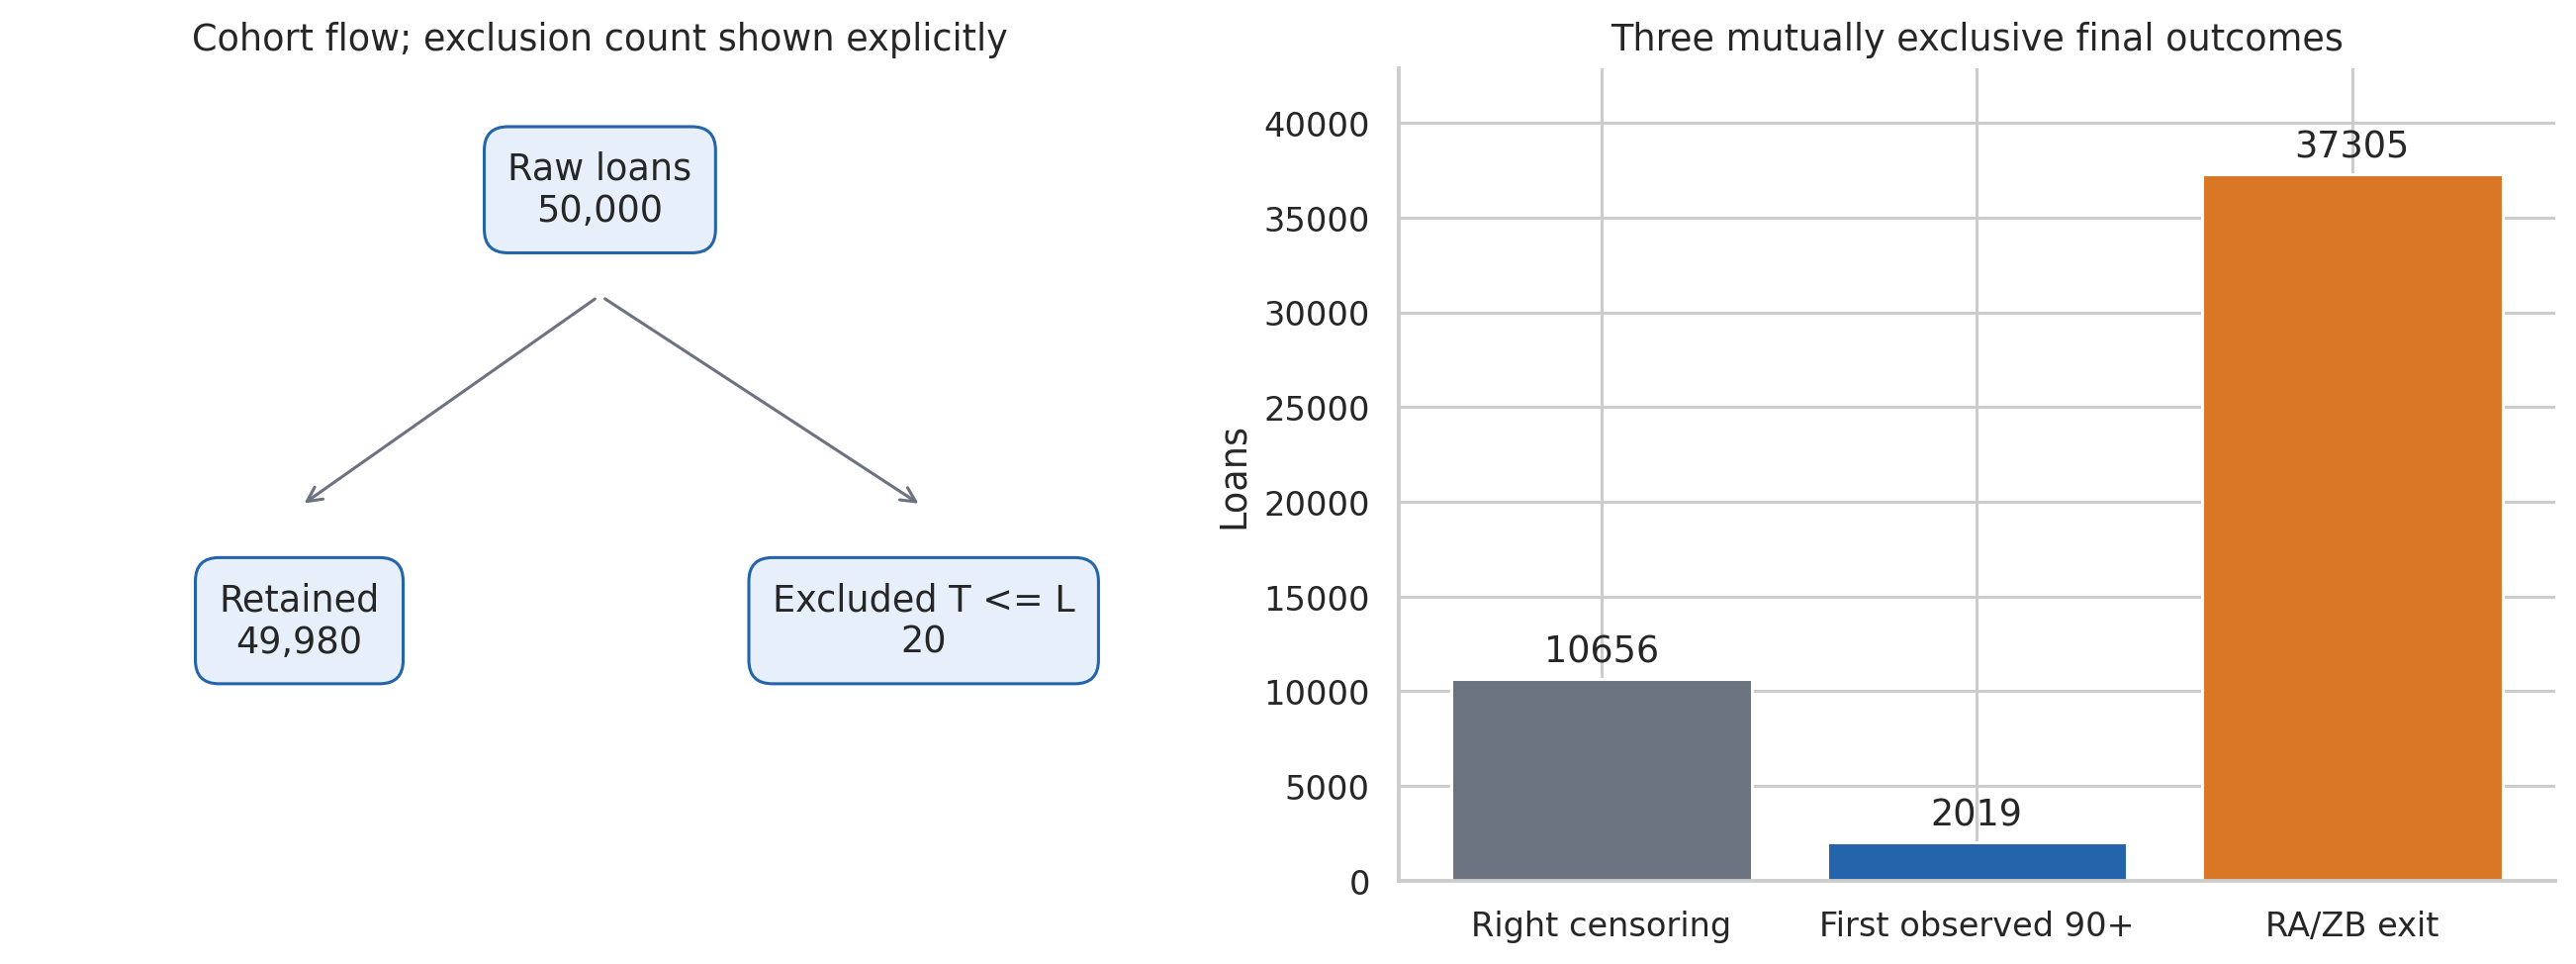

Chỉ loại những khoảng thời gian không hợp lệ; phần lớn kết cục quan sát là Zero Balance. Số Cause 0 không được cộng vào tất toán. Hai nguyên nhân có tần suất rất khác nhau nên cần benchmark khi diễn giải sai số dự báo.

In [4]:
# Inventory được ghi trước khi vẽ để mỗi hình gắn với một câu hỏi phân tích.
FIGURES={
 'time_effects':('diagnostics','Targeted time effects, HR(t) and CI; selection uses training criteria only'),
 'cohort_flow':('eda','Dòng cohort, các lý do loại và ba kết cục'),
 'missingness':('eda','Tỷ lệ thiếu sau nhận diện sentinel theo biến'),
 'time_distributions':('eda','Delayed entry, tuổi kết thúc và thời gian quan sát khác nhau thế nào'),
 'continuous_distributions':('eda','Phân phối các biến hợp đồng và rủi ro nền'),
 'continuous_boxplots':('eda','Phạm vi và các giá trị cực trị của biến chính'),
 'categorical_distributions':('eda','Các nhóm phân loại có cân bằng hay quá hiếm'),
 'correlation':('eda','CLTV và LTV có mang thông tin gần trùng nhau'),
 'characteristics_by_outcome':('eda','Phân phối đặc trưng theo kết cục quan sát'),
 'aj_curves':('eda','Incidence hai nguyên nhân và phân tầng FICO có khác nhau'),
 'events_by_month':('eda','Kết cục được ghi nhận ở những tuổi khoản vay nào'),
 'forest_hr':('model','Hướng và bất định của các liên hệ cause-specific'),
 'baseline_hazard':('model','Baseline cumulative hazard của hai nguyên nhân'),
 'profile_cif':('model','Hai hazard phối hợp tạo CIF cá nhân như thế nào'),
 'schoenfeld':('diagnostics','Hệ số có thay đổi theo log thời gian'),
 'martingale':('diagnostics','Tuyến tính log-hazard có bỏ sót dạng quan hệ'),
 'influence':('diagnostics','Có khoản vay nào ảnh hưởng mạnh theo xấp xỉ one-step'),
 'calibration':('evaluation','Mean prediction và AJ trong quintile có phù hợp'),
 'brier':('evaluation','Cox có giảm sai số CIF so với AJ train'),
 'calibration_in_large':('evaluation','CIF dự báo và quan sát lệch thế nào theo horizon'),
 'predicted_cif_distribution':('evaluation','Nguy cơ dự báo có phân tán và tập trung ở đâu'),
 'bootstrap_uncertainty':('evaluation','CI phản ánh biến thiên lấy mẫu test ra sao'),
 'landmark_calibration':('evaluation','Calibration sau landmark 12 có ổn định'),
 'sensitivity':('evaluation','Hai quy tắc thời gian và dạng FICO ảnh hưởng kết quả thế nào'),
 'fico_functional_form':('model','Targeted nonlinear shapes: FICO both causes, LTV/UPB Cause 2, with joint model CI')}
figure_manifest=[{'name':n,'path':f'outputs/{folder}/{n}.png','purpose':purpose} for n,(folder,purpose) in FIGURES.items()]
(ROOT/'artifacts/figures_manifest.json').write_text(json.dumps(figure_manifest,ensure_ascii=False,indent=2),encoding='utf-8')
def save_figure(fig,name):
    folder,_=FIGURES[name]
    fig.tight_layout()
    path=ROOT/'outputs'/folder/(name+'.png')
    fig.savefig(path,bbox_inches='tight',facecolor='white')
    display(Image(filename=str(path)))
    plt.close(fig)

fig,ax=plt.subplots(1,2,figsize=(12,4.6))
ax[0].axis('off')
boxes=[(.5,.85,f'Raw loans\n{len(orig):,}'),(.24,.32,f'Retained\n{len(cohort):,}'),(.78,.32,f'Excluded T <= L\n{len(exclusions):,}')]
for x,y,label in boxes: ax[0].text(x,y,label,ha='center',va='center',bbox={'boxstyle':'round,pad=.65','fc':'#E7F0FA','ec':BLUE})
for x in [.24,.78]: ax[0].annotate('',(x,.46),(.5,.72),arrowprops={'arrowstyle':'->','color':GRAY})
ax[0].set_title('Cohort flow; exclusion count shown explicitly')
counts=cohort.J.value_counts().reindex([0,1,2])
bars=ax[1].bar(['Right censoring','First observed 90+','RA/ZB exit'],counts,color=[GRAY,BLUE,ORANGE])
ax[1].bar_label(bars,fmt='%d',padding=3); ax[1].set(ylabel='Loans',title='Three mutually exclusive final outcomes'); ax[1].margins(y=.15)
save_figure(fig,'cohort_flow')
say('Chỉ loại những khoảng thời gian không hợp lệ; phần lớn kết cục quan sát là Zero Balance. Số Cause 0 không được cộng vào tất toán. Hai nguyên nhân có tần suất rất khác nhau nên cần benchmark khi diễn giải sai số dự báo.')

,count,mean,std,min,1%,25%,50%,75%,99%,max,missing_pct
classic_fico_score,49980.0,749.748,47.509,462.000,625.000,718.00,760.0,788.00,817.00,834.0,0.000
original_dti,45961.0,33.840,9.392,1.000,12.000,27.00,35.0,42.00,50.00,50.0,8.041
original_cltv,49979.0,74.403,18.021,5.000,24.000,66.00,79.0,85.00,107.00,854.0,0.002
original_ltv,49979.0,73.511,17.514,5.000,24.000,65.00,78.0,83.00,100.00,241.0,0.002
original_interest_rate,49980.0,3.975,0.452,2.375,2.875,3.75,4.0,4.25,4.99,5.5,0.000
original_upb,49980.0,224013.425,119994.882,10000.000,46000.000,131000.00,200000.0,299000.00,593210.00,974000.0,0.000
original_loan_term,49980.0,315.307,75.915,96.000,120.000,240.00,360.0,360.00,360.00,366.0,0.000
mortgage_insurance_percentage,49980.0,5.903,11.150,0.000,0.000,0.00,0.0,0.00,30.00,40.0,0.000


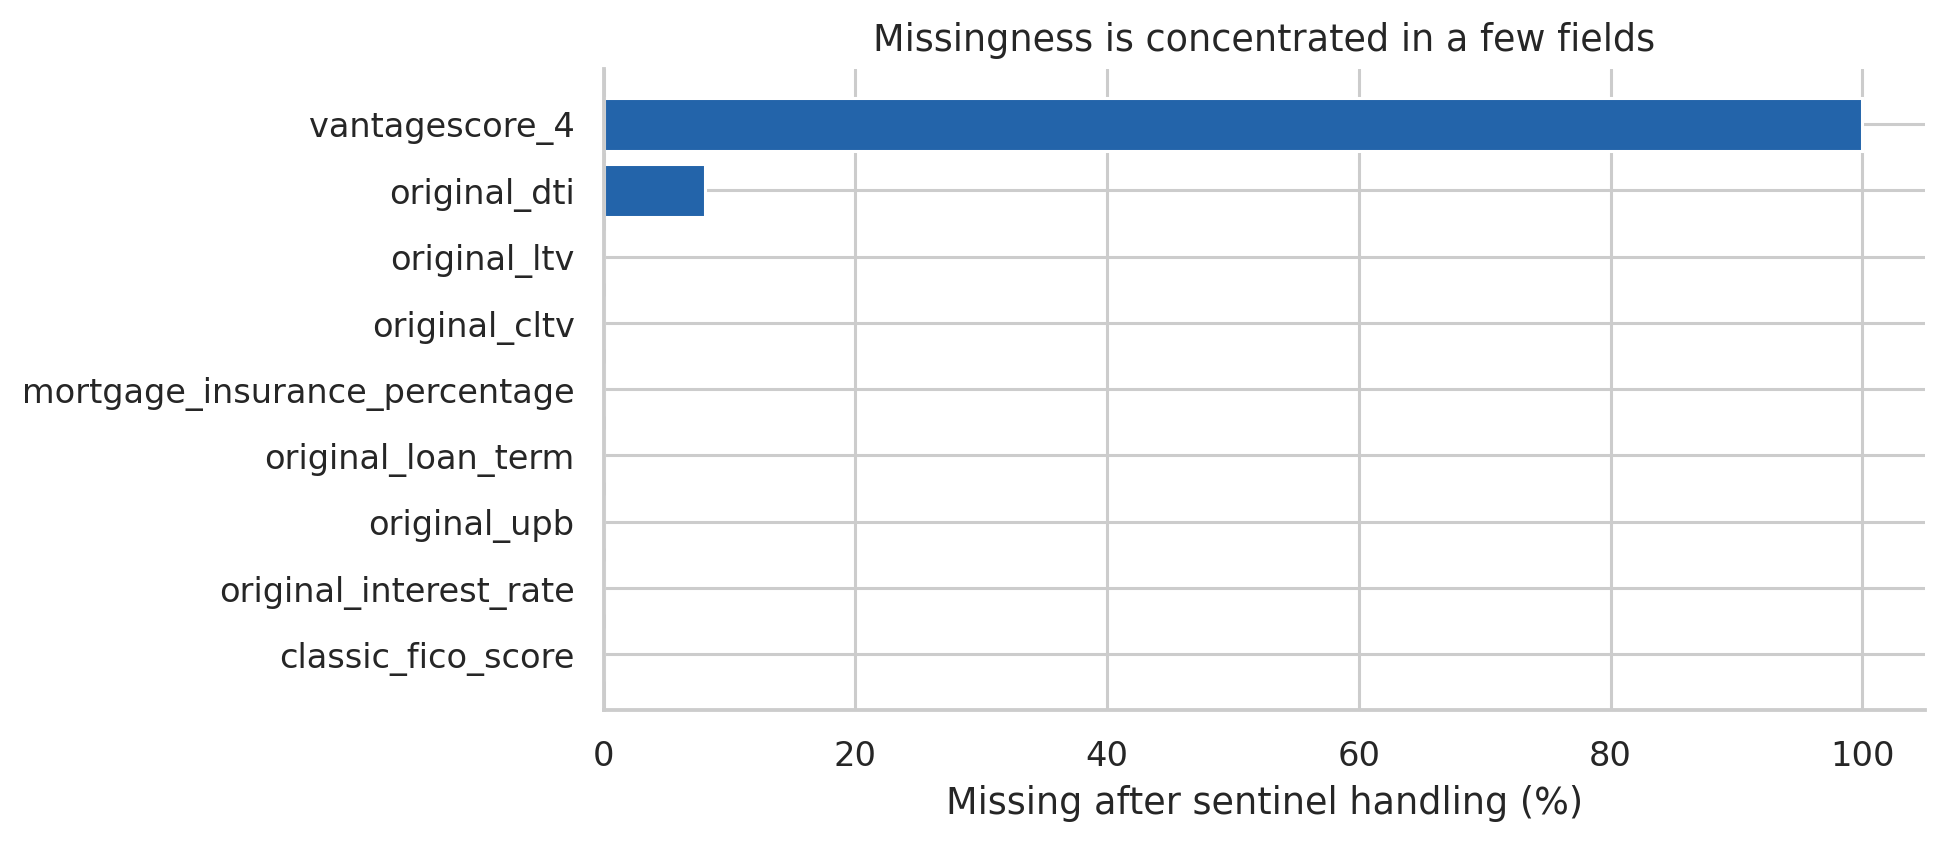

DTI có giá trị 999 cần đổi thành missing, trong khi VantageScore toàn 9999 nên không có thông tin. Không sử dụng VantageScore trong mô hình. LTV/CLTV có một sentinel: median train được dùng thay vì loại khoản vay hoặc tạo indicator chỉ có một người.

,classic_fico_score,original_dti,original_cltv,original_ltv,original_interest_rate,original_upb,original_loan_term,mortgage_insurance_percentage
J,,,,,,,,
0,0.0,10.689,0.000,0.000,0.0,0.0,0.0,0.0
1,0.0,15.800,0.000,0.000,0.0,0.0,0.0,0.0
2,0.0,6.865,0.003,0.003,0.0,0.0,0.0,0.0


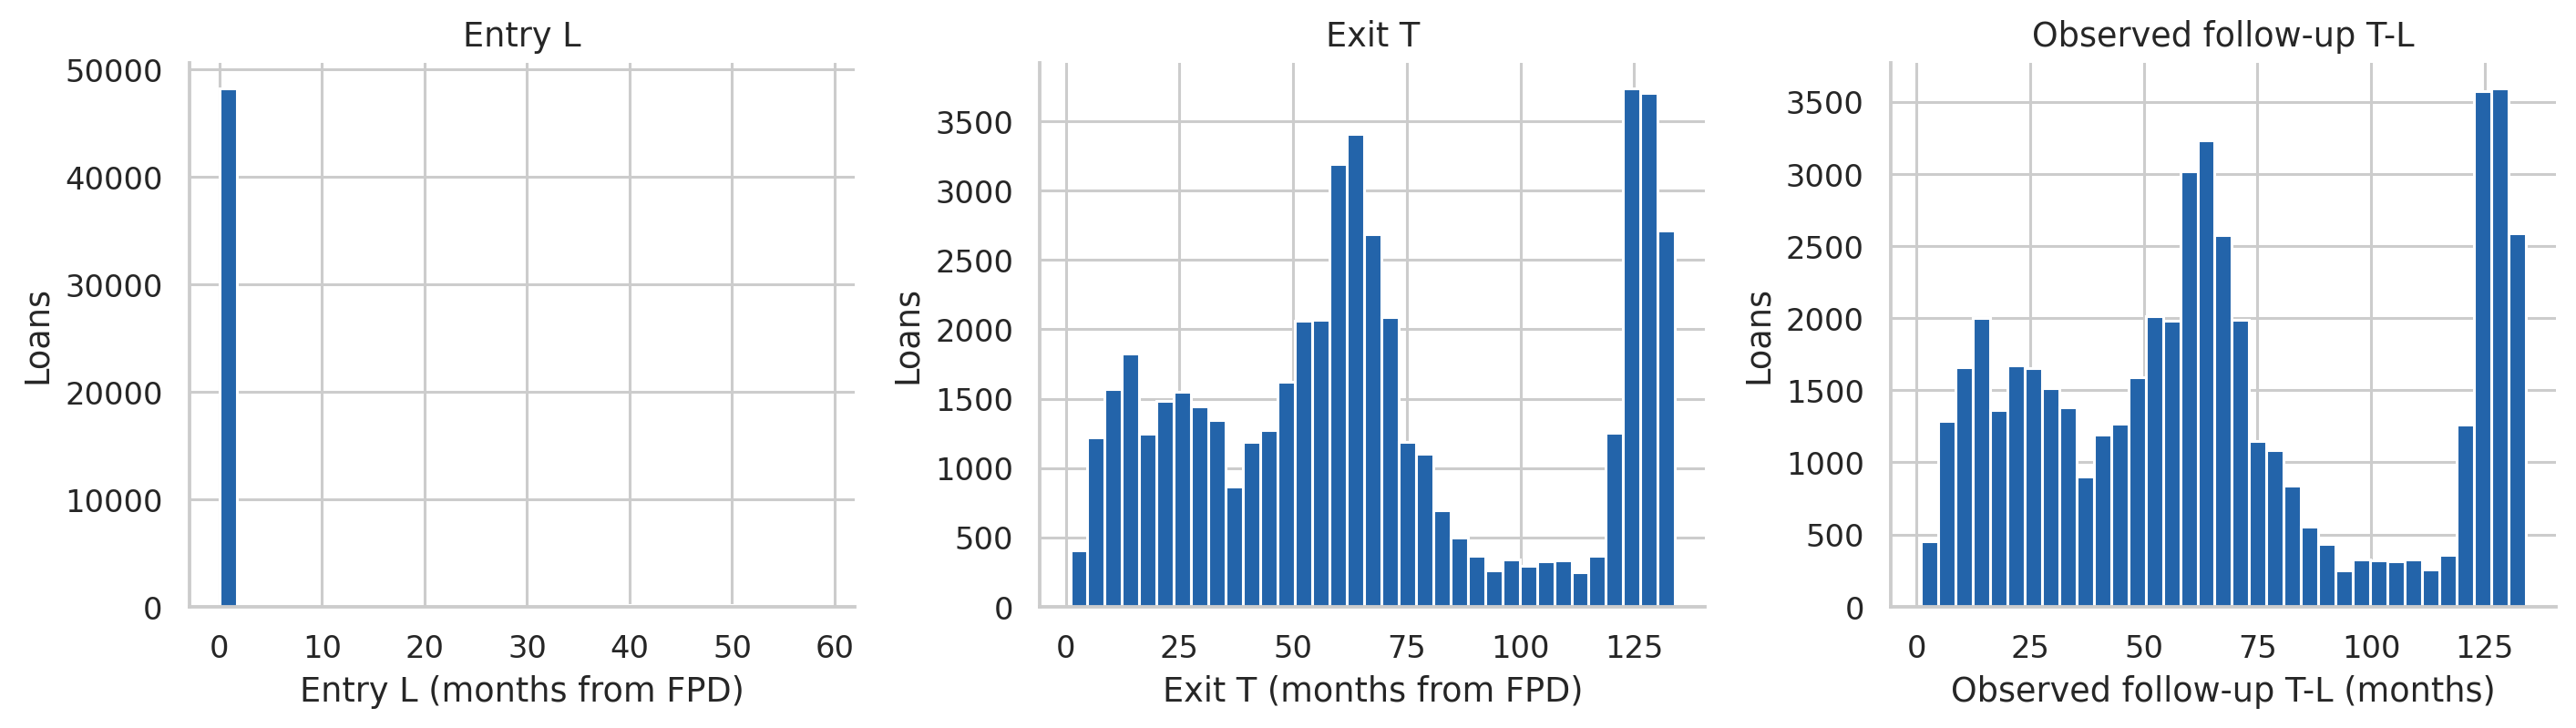

Đỉnh entry ở 0 không xóa được vấn đề left truncation: các late entrants chỉ vào risk set khi quan sát bắt đầu. Phân phối follow-up không giống phân phối tuổi khoản vay. Không diễn giải đuôi dài là mọi khoản được theo dõi đầy đủ từ origination.

In [5]:
continuous=['classic_fico_score','original_dti','original_cltv','original_ltv','original_interest_rate','original_upb','original_loan_term','mortgage_insurance_percentage']
summary=cohort[continuous].describe(percentiles=[.01,.25,.5,.75,.99]).T
summary['missing_pct']=cohort[continuous].isna().mean()*100
display(summary.round(3))
table(summary.reset_index(names='variable'),'descriptive_statistics')
fig,ax=plt.subplots(figsize=(9,4))
missing=(cohort[continuous+['vantagescore_4']].isna().mean()*100).sort_values()
ax.barh(missing.index,missing,color=BLUE); ax.set(xlabel='Missing after sentinel handling (%)',title='Missingness is concentrated in a few fields')
save_figure(fig,'missingness')
say('DTI có giá trị 999 cần đổi thành missing, trong khi VantageScore toàn 9999 nên không có thông tin. Không sử dụng VantageScore trong mô hình. LTV/CLTV có một sentinel: median train được dùng thay vì loại khoản vay hoặc tạo indicator chỉ có một người.')
display(cohort.groupby('J')[continuous].apply(lambda x:x.isna().mean()*100).round(3))
fig,ax=plt.subplots(1,3,figsize=(13,3.8))
for a,c,label in zip(ax,['L','T','follow_up'],['Entry L (months from FPD)','Exit T (months from FPD)','Observed follow-up T-L (months)']):
    a.hist(cohort[c],bins=35,color=BLUE); a.set(xlabel=label,ylabel='Loans',title=label.split(' (')[0])
save_figure(fig,'time_distributions')
say('Đỉnh entry ở 0 không xóa được vấn đề left truncation: các late entrants chỉ vào risk set khi quan sát bắt đầu. Phân phối follow-up không giống phân phối tuổi khoản vay. Không diễn giải đuôi dài là mọi khoản được theo dõi đầy đủ từ origination.')

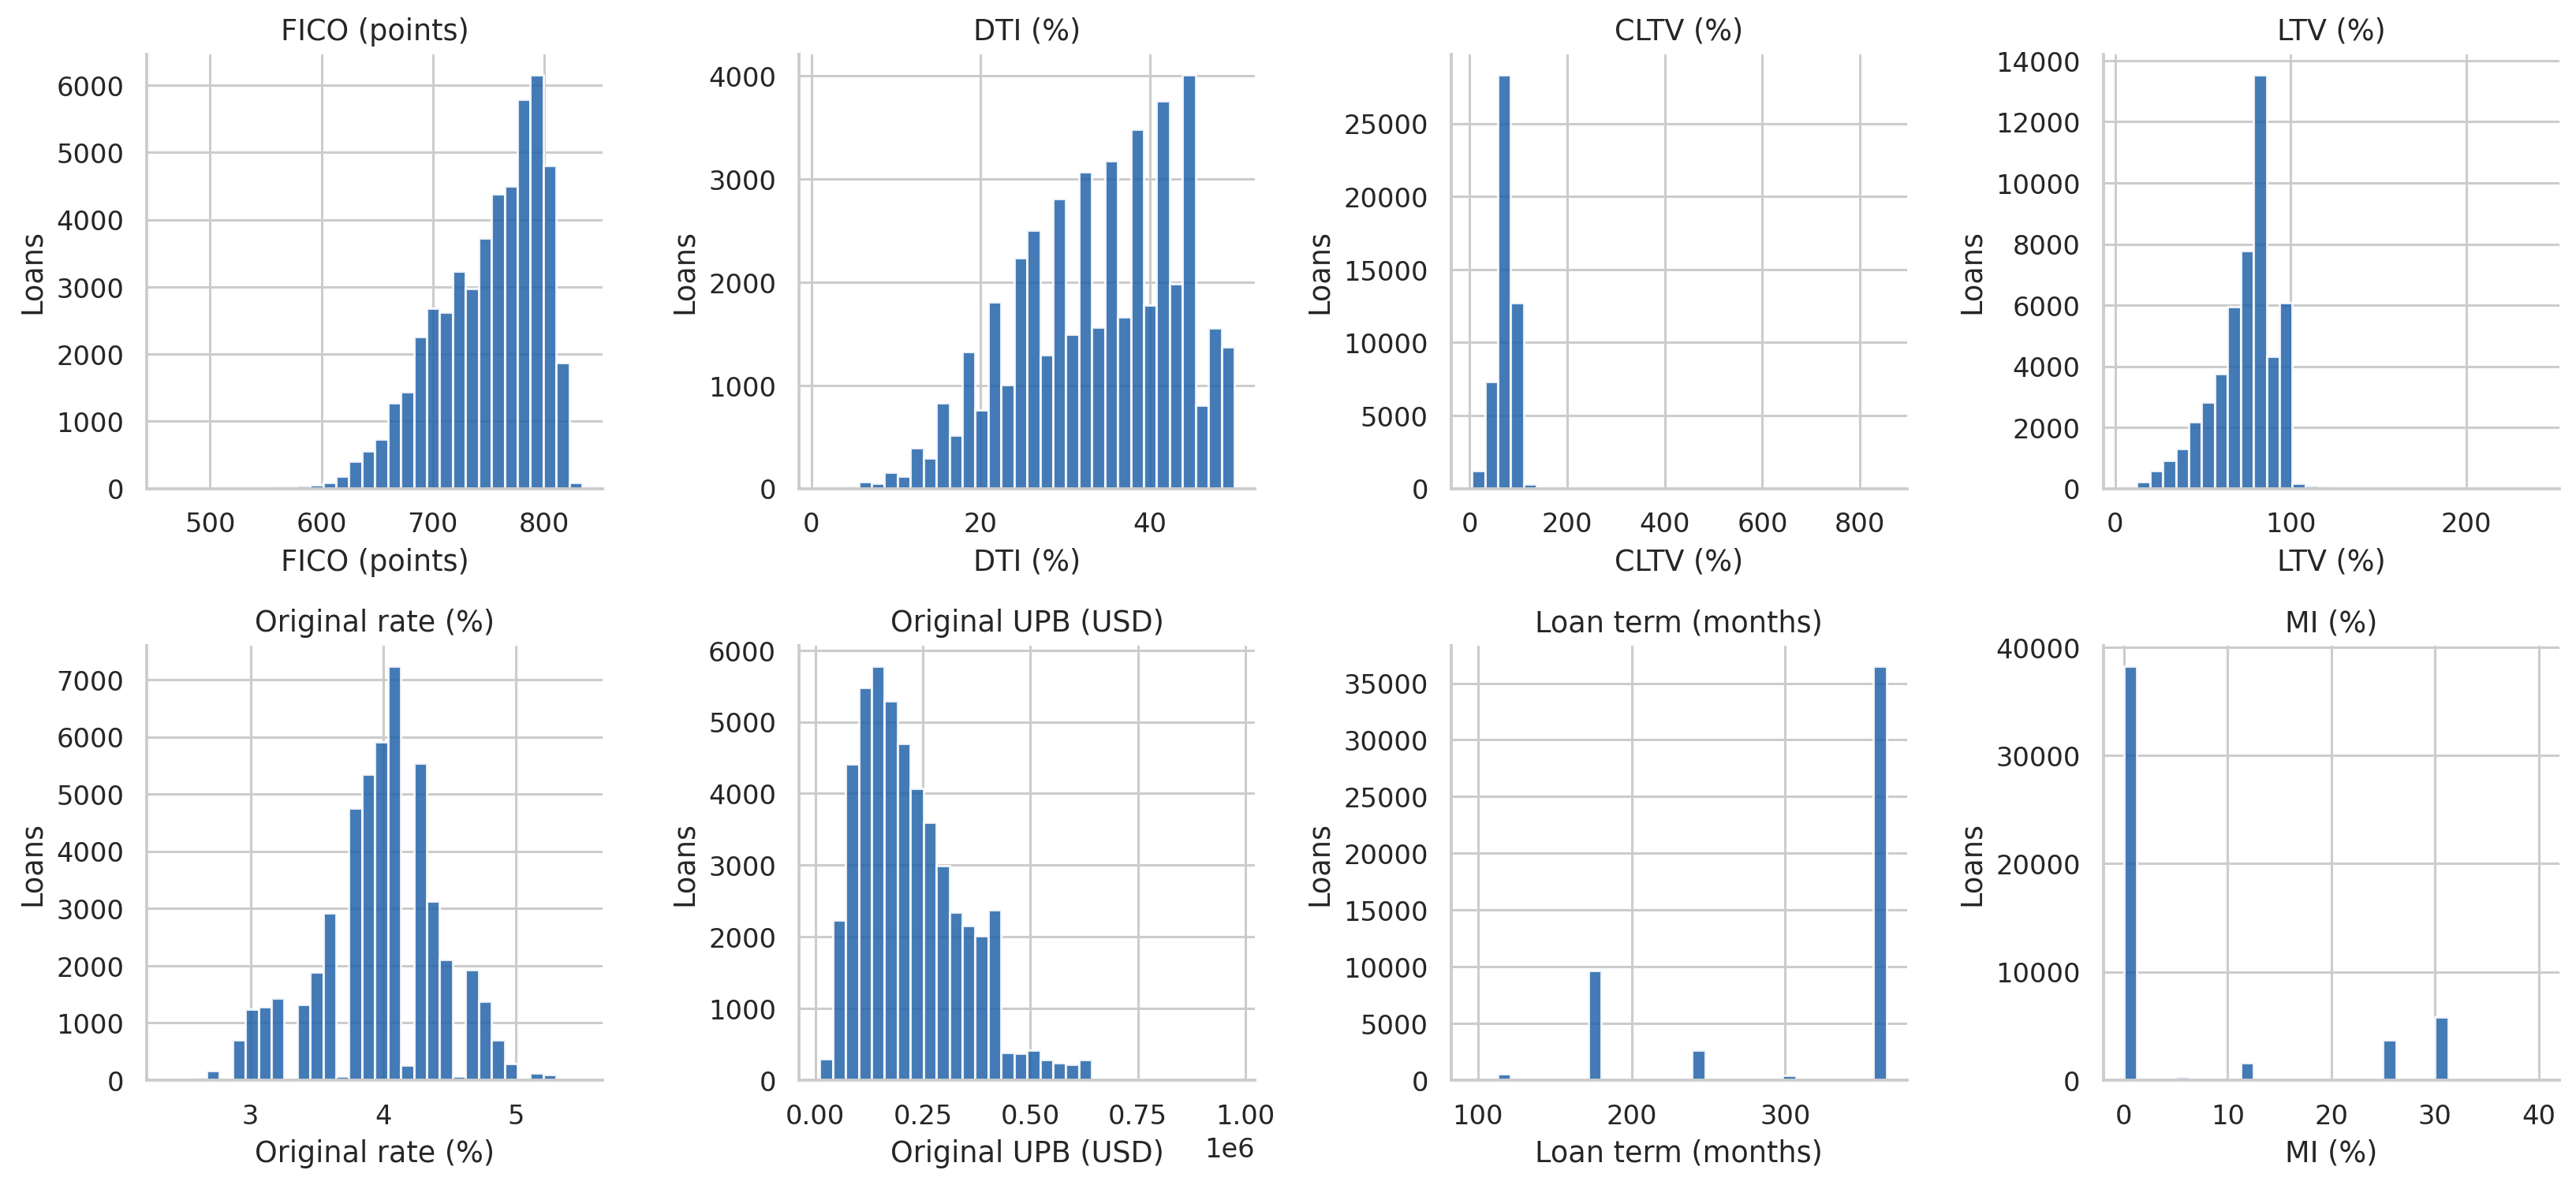

FICO, DTI và các tỷ lệ tài sản bảo đảm có thang đo khác nhau; UPB lệch phải và loan term tập trung ở một vài sản phẩm. Các đặc điểm này định hướng cách trình bày và scale, không tự chứng minh quan hệ tuyến tính trên log-hazard. MI bằng 0 là không có bảo hiểm, không phải missing.

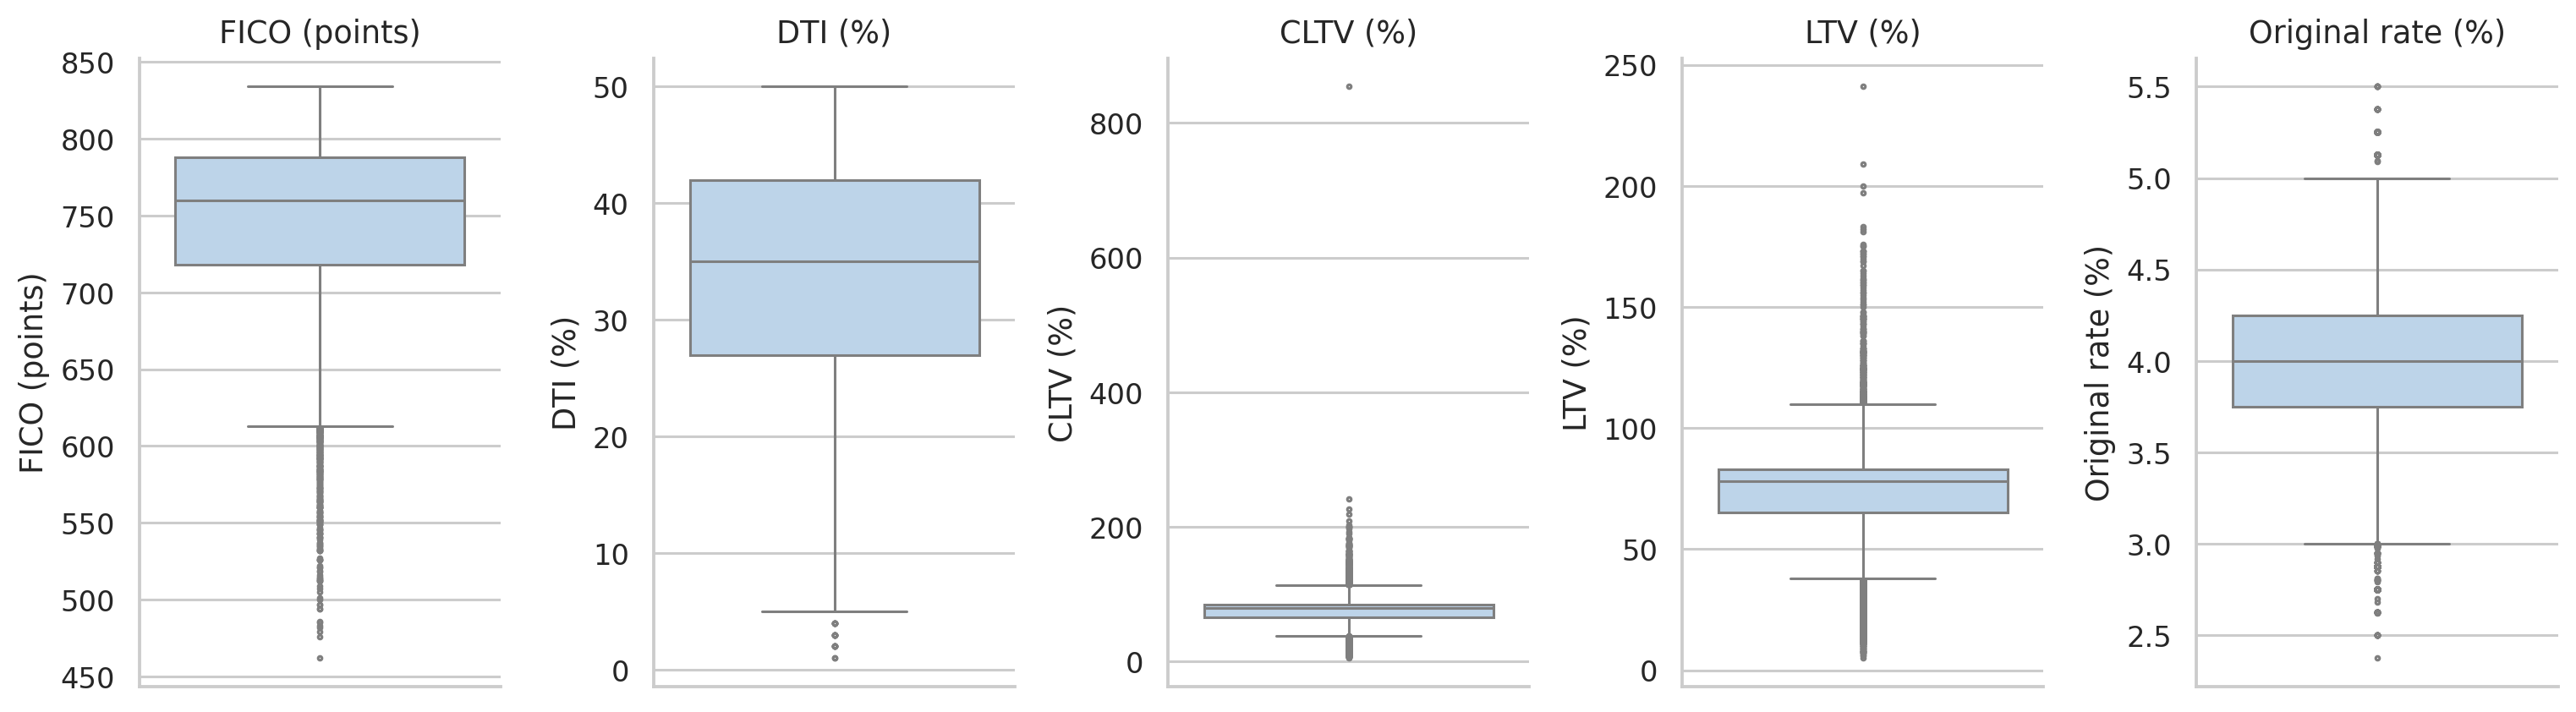

Boxplot giúp định vị các giá trị cực trị sau xử lý sentinel. Những giá trị còn lại nằm trong miền vintage đã đối chiếu; không winsorize hoặc loại mẫu chỉ vì nằm ngoài whisker.

In [6]:
labels={'classic_fico_score':'FICO (points)','original_dti':'DTI (%)','original_cltv':'CLTV (%)',
 'original_ltv':'LTV (%)','original_interest_rate':'Original rate (%)','original_upb':'Original UPB (USD)',
 'original_loan_term':'Loan term (months)','mortgage_insurance_percentage':'MI (%)'}
fig,axes=plt.subplots(2,4,figsize=(15,7))
for ax,c in zip(axes.flat,continuous):
    ax.hist(cohort[c].dropna(),bins=32,color=BLUE,alpha=.85); ax.set(xlabel=labels[c],ylabel='Loans',title=labels[c])
save_figure(fig,'continuous_distributions')
say('FICO, DTI và các tỷ lệ tài sản bảo đảm có thang đo khác nhau; UPB lệch phải và loan term tập trung ở một vài sản phẩm. Các đặc điểm này định hướng cách trình bày và scale, không tự chứng minh quan hệ tuyến tính trên log-hazard. MI bằng 0 là không có bảo hiểm, không phải missing.')
fig,axes=plt.subplots(1,5,figsize=(14,4))
for ax,c in zip(axes,['classic_fico_score','original_dti','original_cltv','original_ltv','original_interest_rate']):
    sns.boxplot(y=cohort[c],ax=ax,color='#B6D4F0',fliersize=1.5); ax.set(ylabel=labels[c],title=labels[c])
save_figure(fig,'continuous_boxplots')
say('Boxplot giúp định vị các giá trị cực trị sau xử lý sentinel. Những giá trị còn lại nằm trong miền vintage đã đối chiếu; không winsorize hoặc loại mẫu chỉ vì nằm ngoài whisker.')

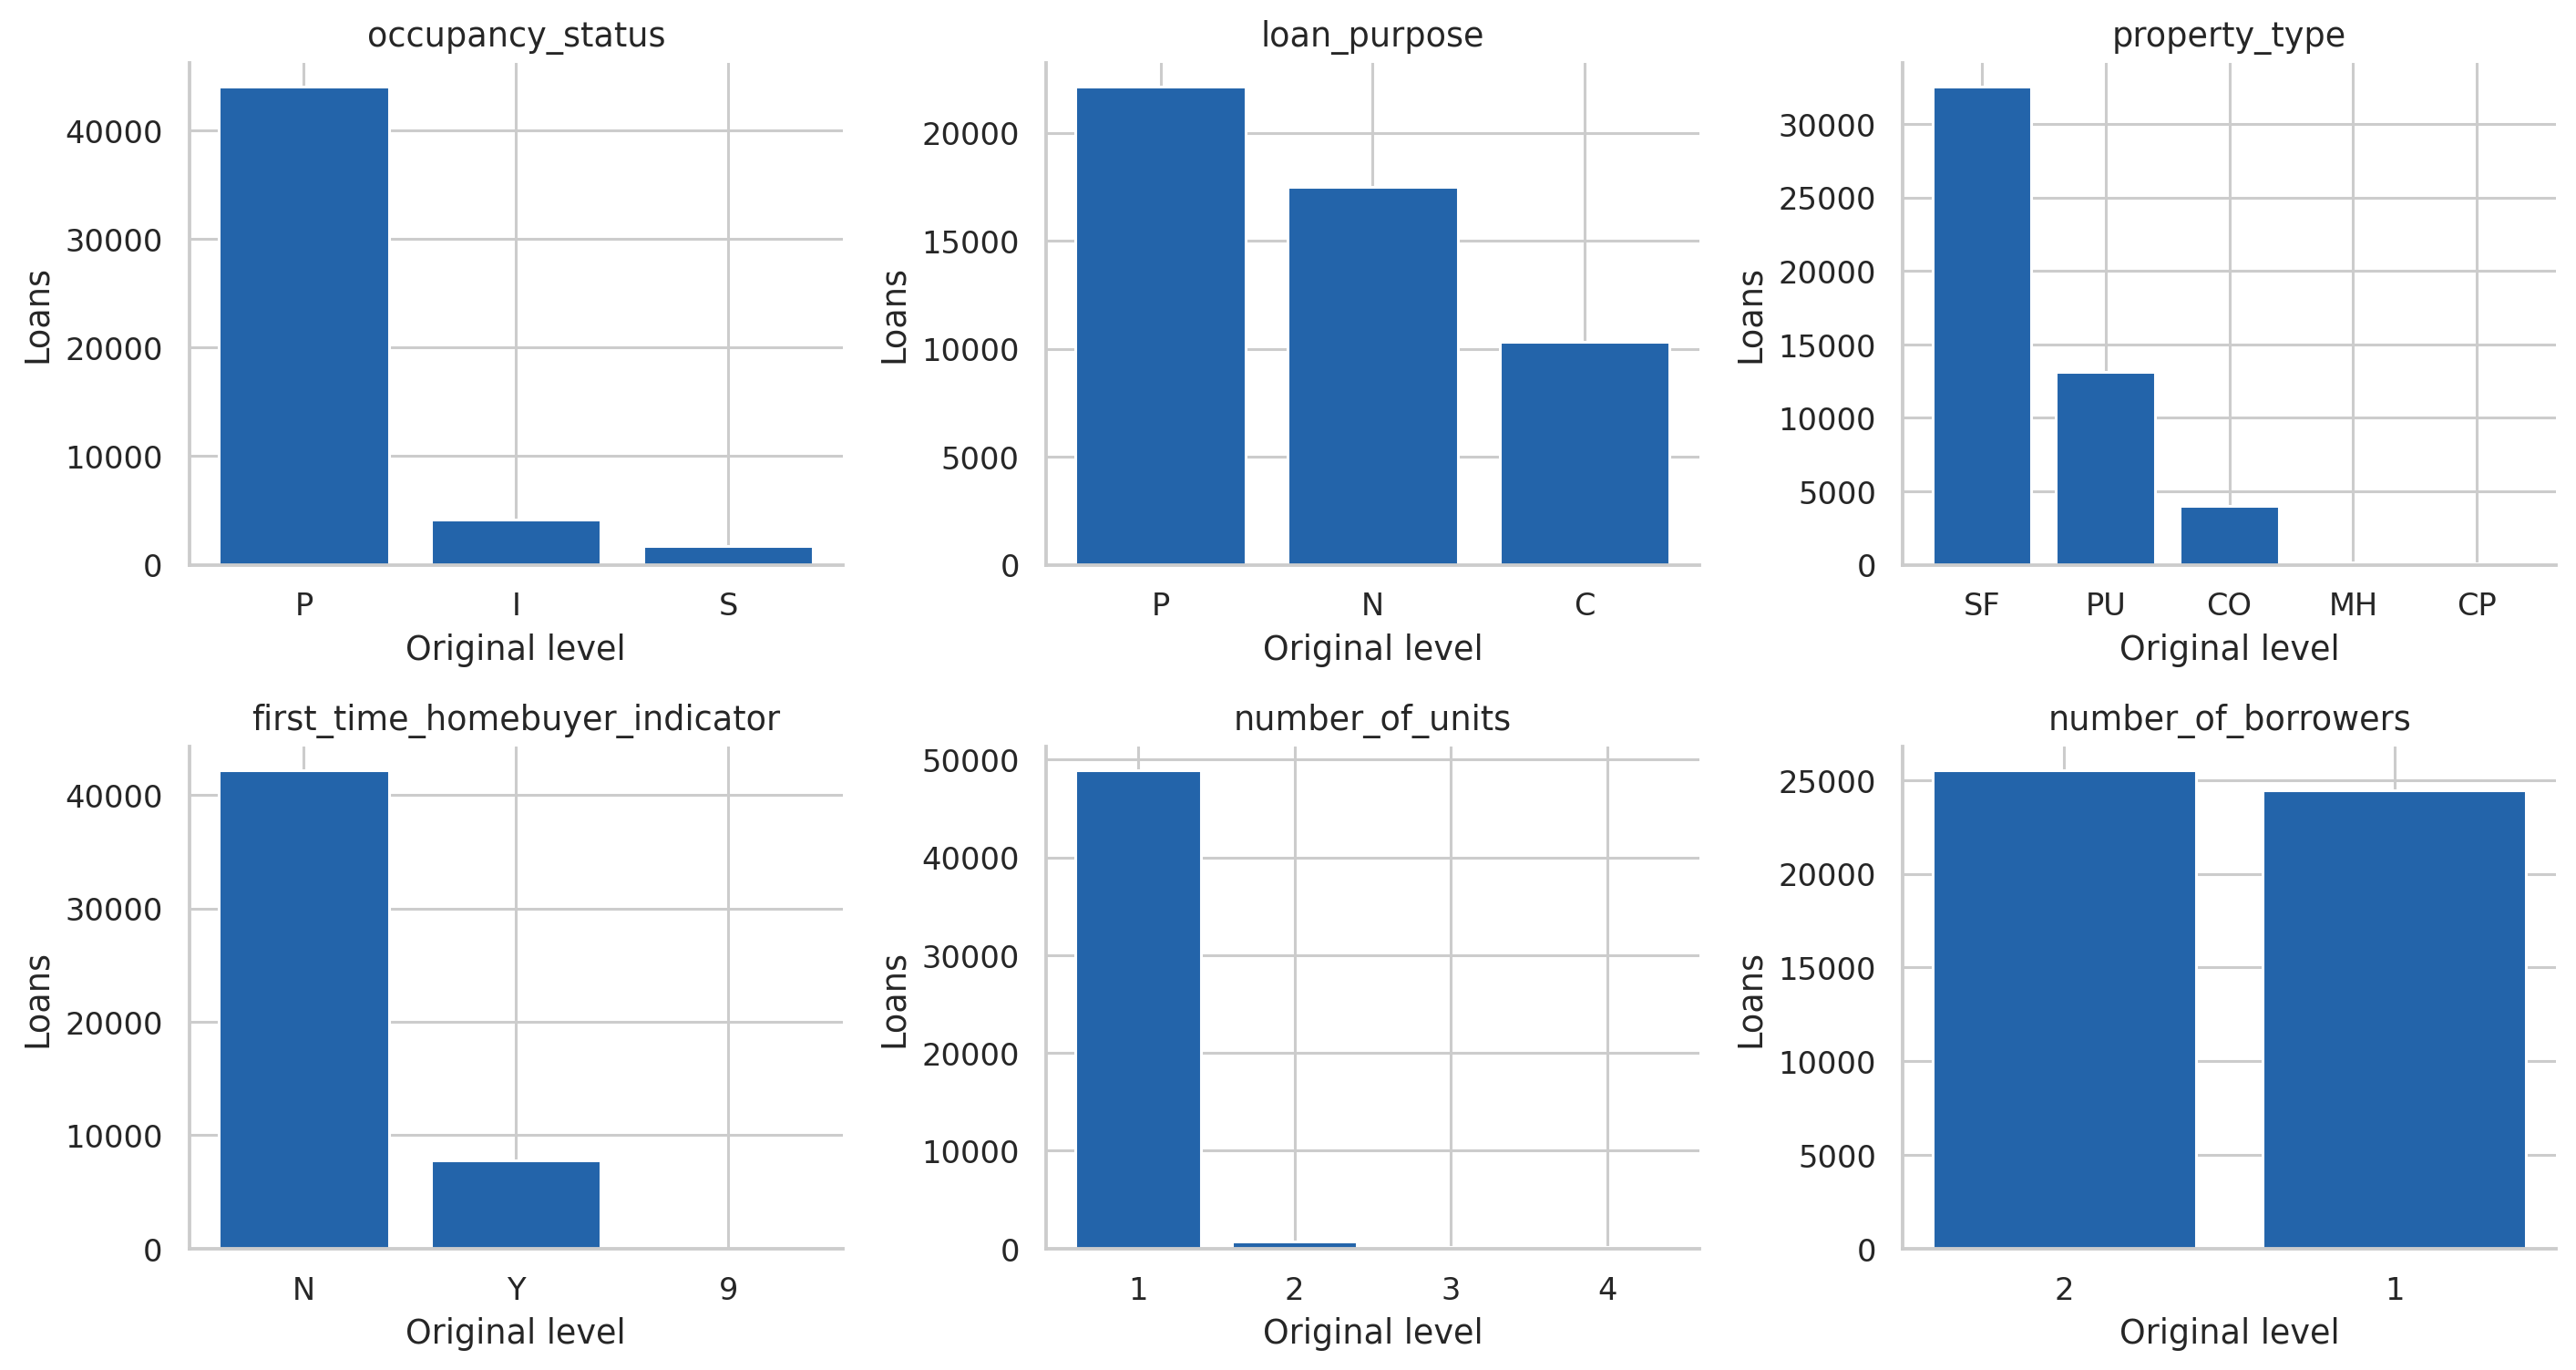

,variable,level,n,pct
0,occupancy_status,P,44078,88.19
1,occupancy_status,I,4154,8.31
2,occupancy_status,S,1748,3.50
3,loan_purpose,P,22142,44.30
4,loan_purpose,N,17508,35.03
5,loan_purpose,C,10330,20.67
6,property_type,SF,32551,65.13
7,property_type,PU,13144,26.30
8,property_type,CO,4012,8.03
9,property_type,MH,176,0.35


Một số nhóm property và units rất hiếm. Encoder sẽ quyết định nhóm giữ lại từ tần suất train, không từ hiệu năng test. Mã borrowers=2 ở vintage 2015 có nghĩa hơn một người vay, không khẳng định đúng hai người.

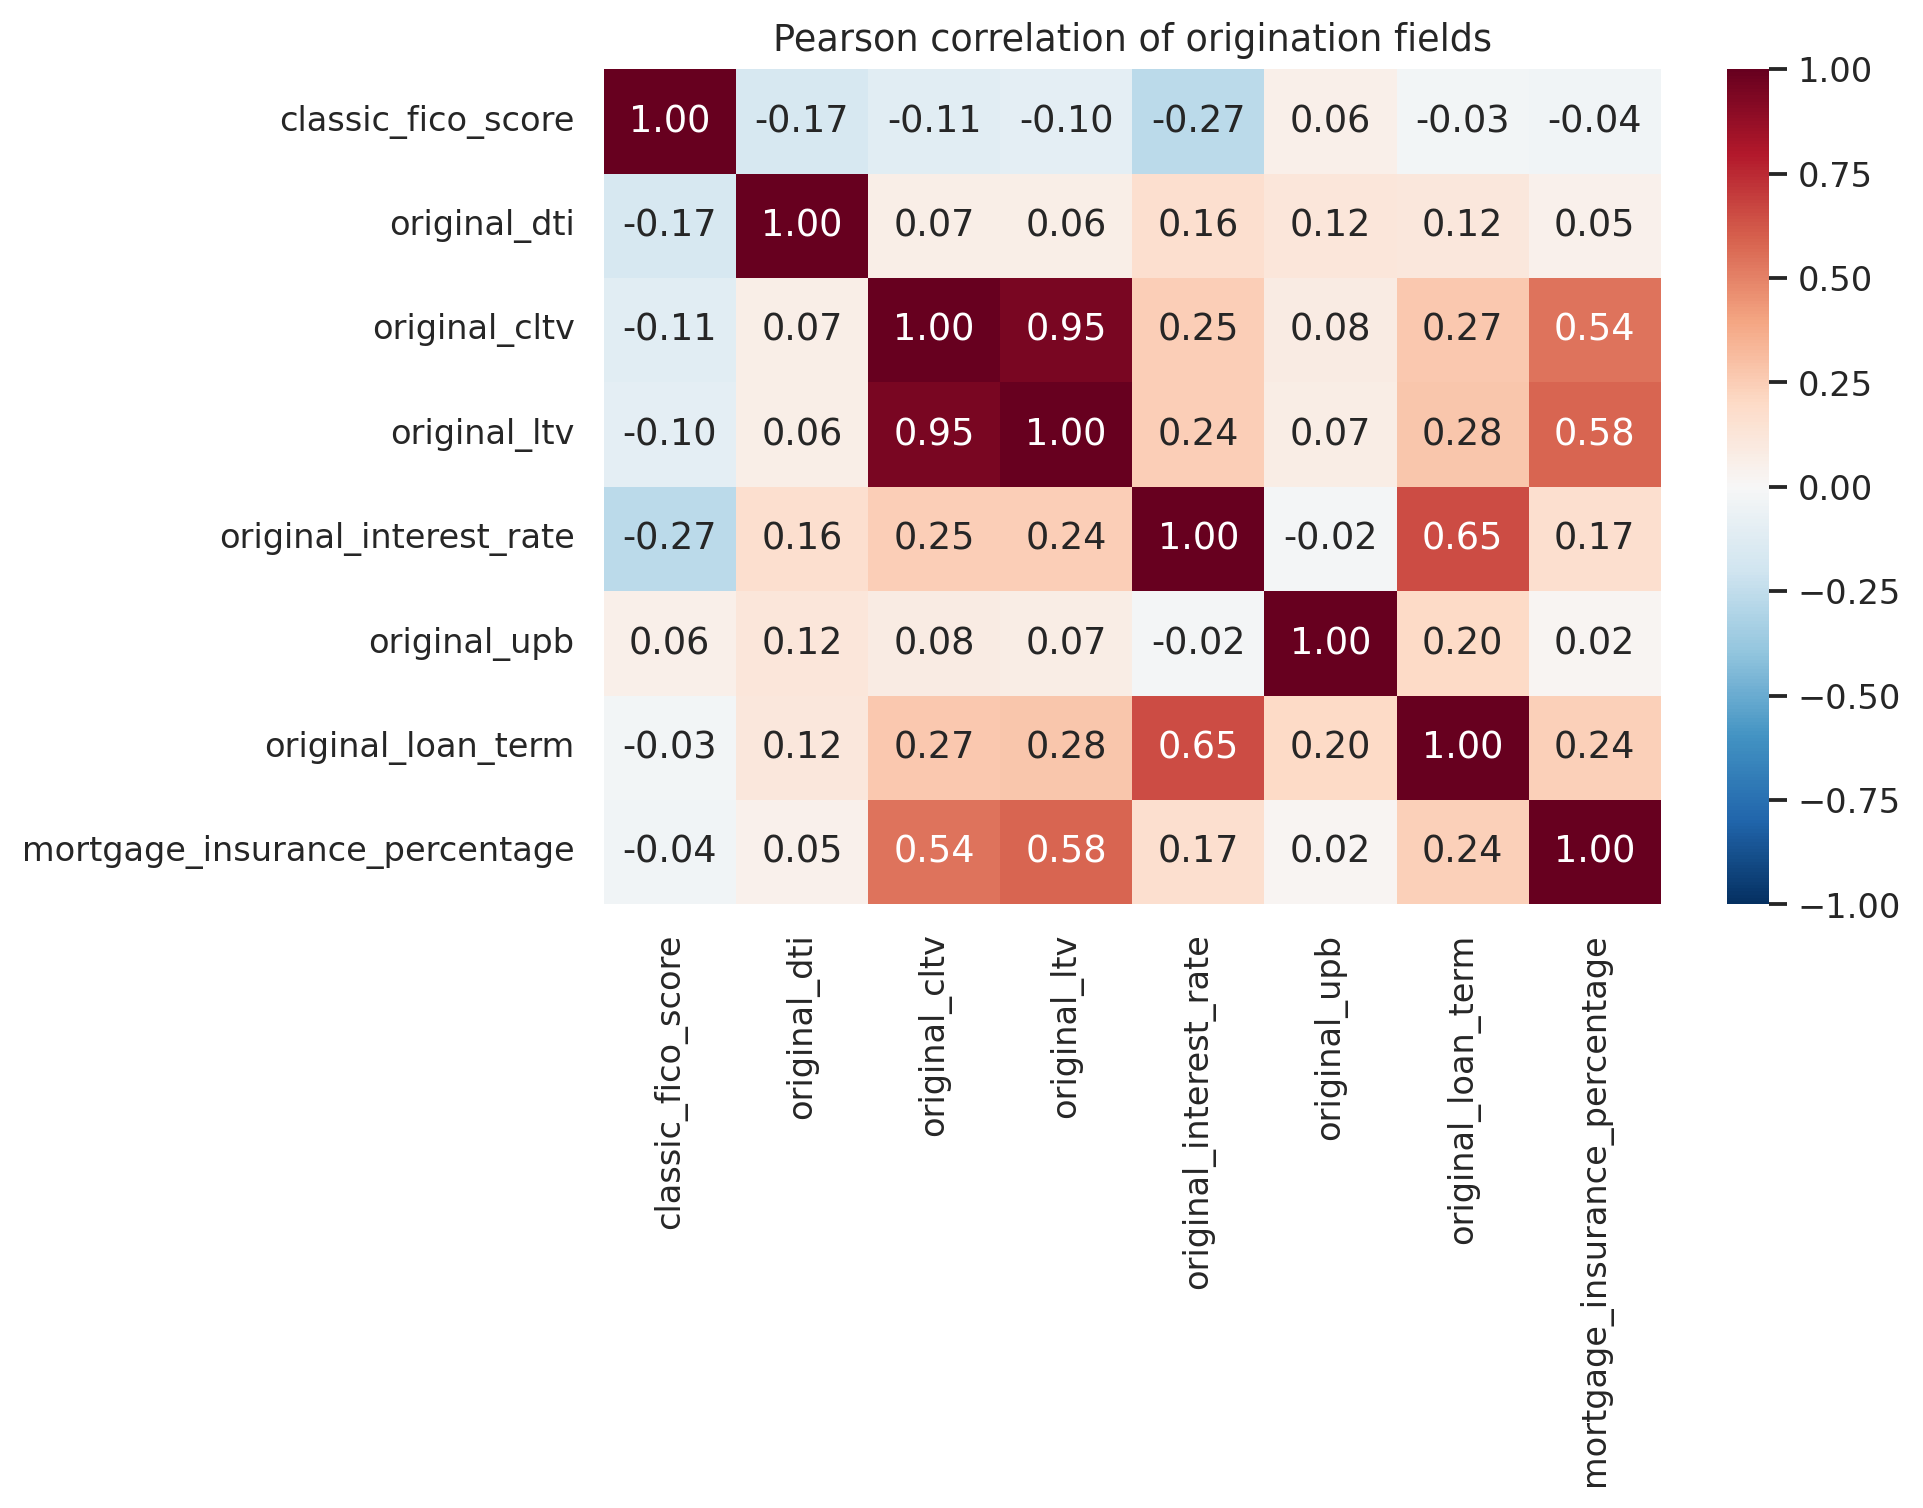

CLTV và LTV tương quan **0.949**. Primary giữ LTV và không đưa đồng thời CLTV để tránh hai đại lượng gần trùng nhau. Tương quan không được diễn giải thành quan hệ nhân quả.

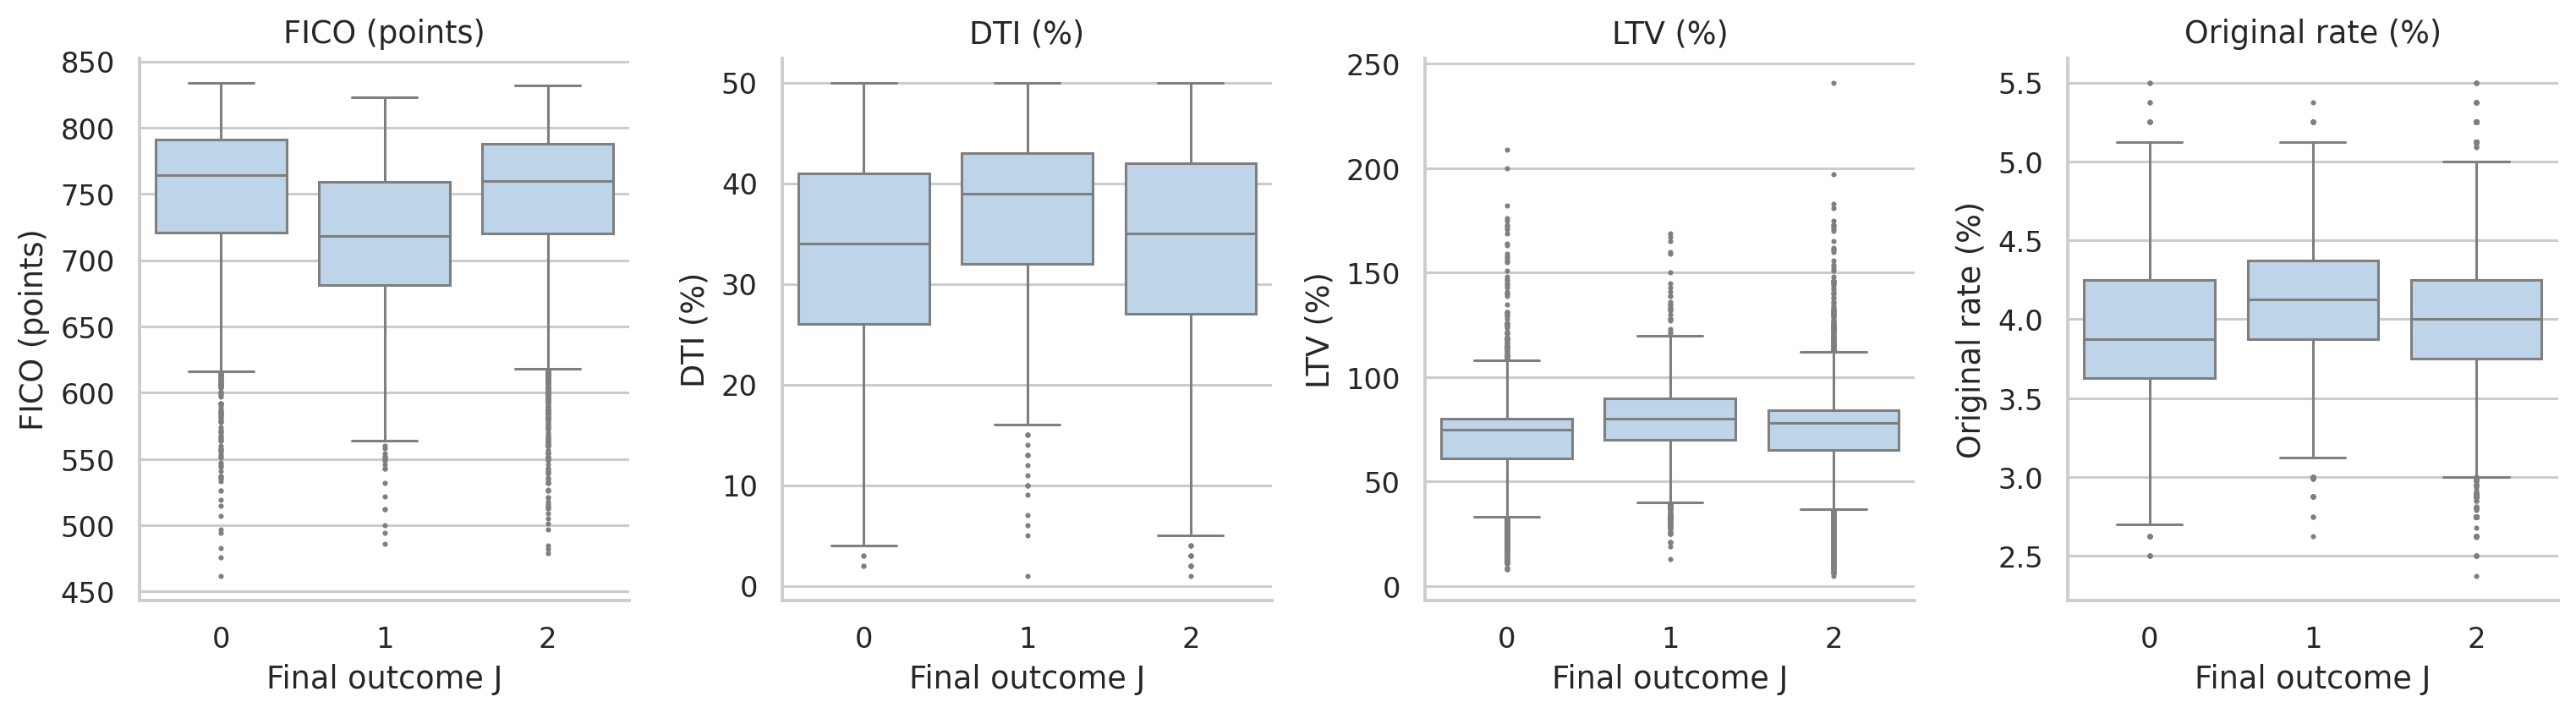

Các khác biệt giữa nhóm Cause 1/2/0 là mô tả, không phải hiệu ứng điều chỉnh covariates. Đặc biệt, nhóm Zero Balance đã rời risk set nên không thể coi họ là những control được theo dõi vô hạn.

In [7]:
categorical=['occupancy_status','loan_purpose','property_type','first_time_homebuyer_indicator','number_of_units','number_of_borrowers']
fig,axes=plt.subplots(2,3,figsize=(13,7))
frequency=[]
for ax,c in zip(axes.flat,categorical):
    counts=cohort[c].fillna('Missing').value_counts()
    ax.bar(counts.index.astype(str),counts.values,color=BLUE); ax.set(title=c,ylabel='Loans',xlabel='Original level')
    frequency.extend({'variable':c,'level':str(k),'n':int(v),'pct':100*v/len(cohort)} for k,v in counts.items())
save_figure(fig,'categorical_distributions')
display(pd.DataFrame(frequency).round(2))
say('Một số nhóm property và units rất hiếm. Encoder sẽ quyết định nhóm giữ lại từ tần suất train, không từ hiệu năng test. Mã borrowers=2 ở vintage 2015 có nghĩa hơn một người vay, không khẳng định đúng hai người.')
fig,ax=plt.subplots(figsize=(9,7))
sns.heatmap(cohort[continuous].corr(),annot=True,fmt='.2f',vmin=-1,vmax=1,cmap='RdBu_r',center=0,ax=ax)
ax.set_title('Pearson correlation of origination fields'); save_figure(fig,'correlation')
say(f"CLTV và LTV tương quan **{cohort.original_cltv.corr(cohort.original_ltv):.3f}**. Primary giữ LTV và không đưa đồng thời CLTV để tránh hai đại lượng gần trùng nhau. Tương quan không được diễn giải thành quan hệ nhân quả.")
fig,axes=plt.subplots(1,4,figsize=(14,4))
for ax,c in zip(axes,['classic_fico_score','original_dti','original_ltv','original_interest_rate']):
    sns.boxplot(data=cohort,x='J',y=c,order=[0,1,2],ax=ax,color='#B6D4F0',fliersize=1)
    ax.set(xlabel='Final outcome J',ylabel=labels[c],title=labels[c])
save_figure(fig,'characteristics_by_outcome')
say('Các khác biệt giữa nhóm Cause 1/2/0 là mô tả, không phải hiệu ứng điều chỉnh covariates. Đặc biệt, nhóm Zero Balance đã rời risk set nên không thể coi họ là những control được theo dõi vô hạn.')

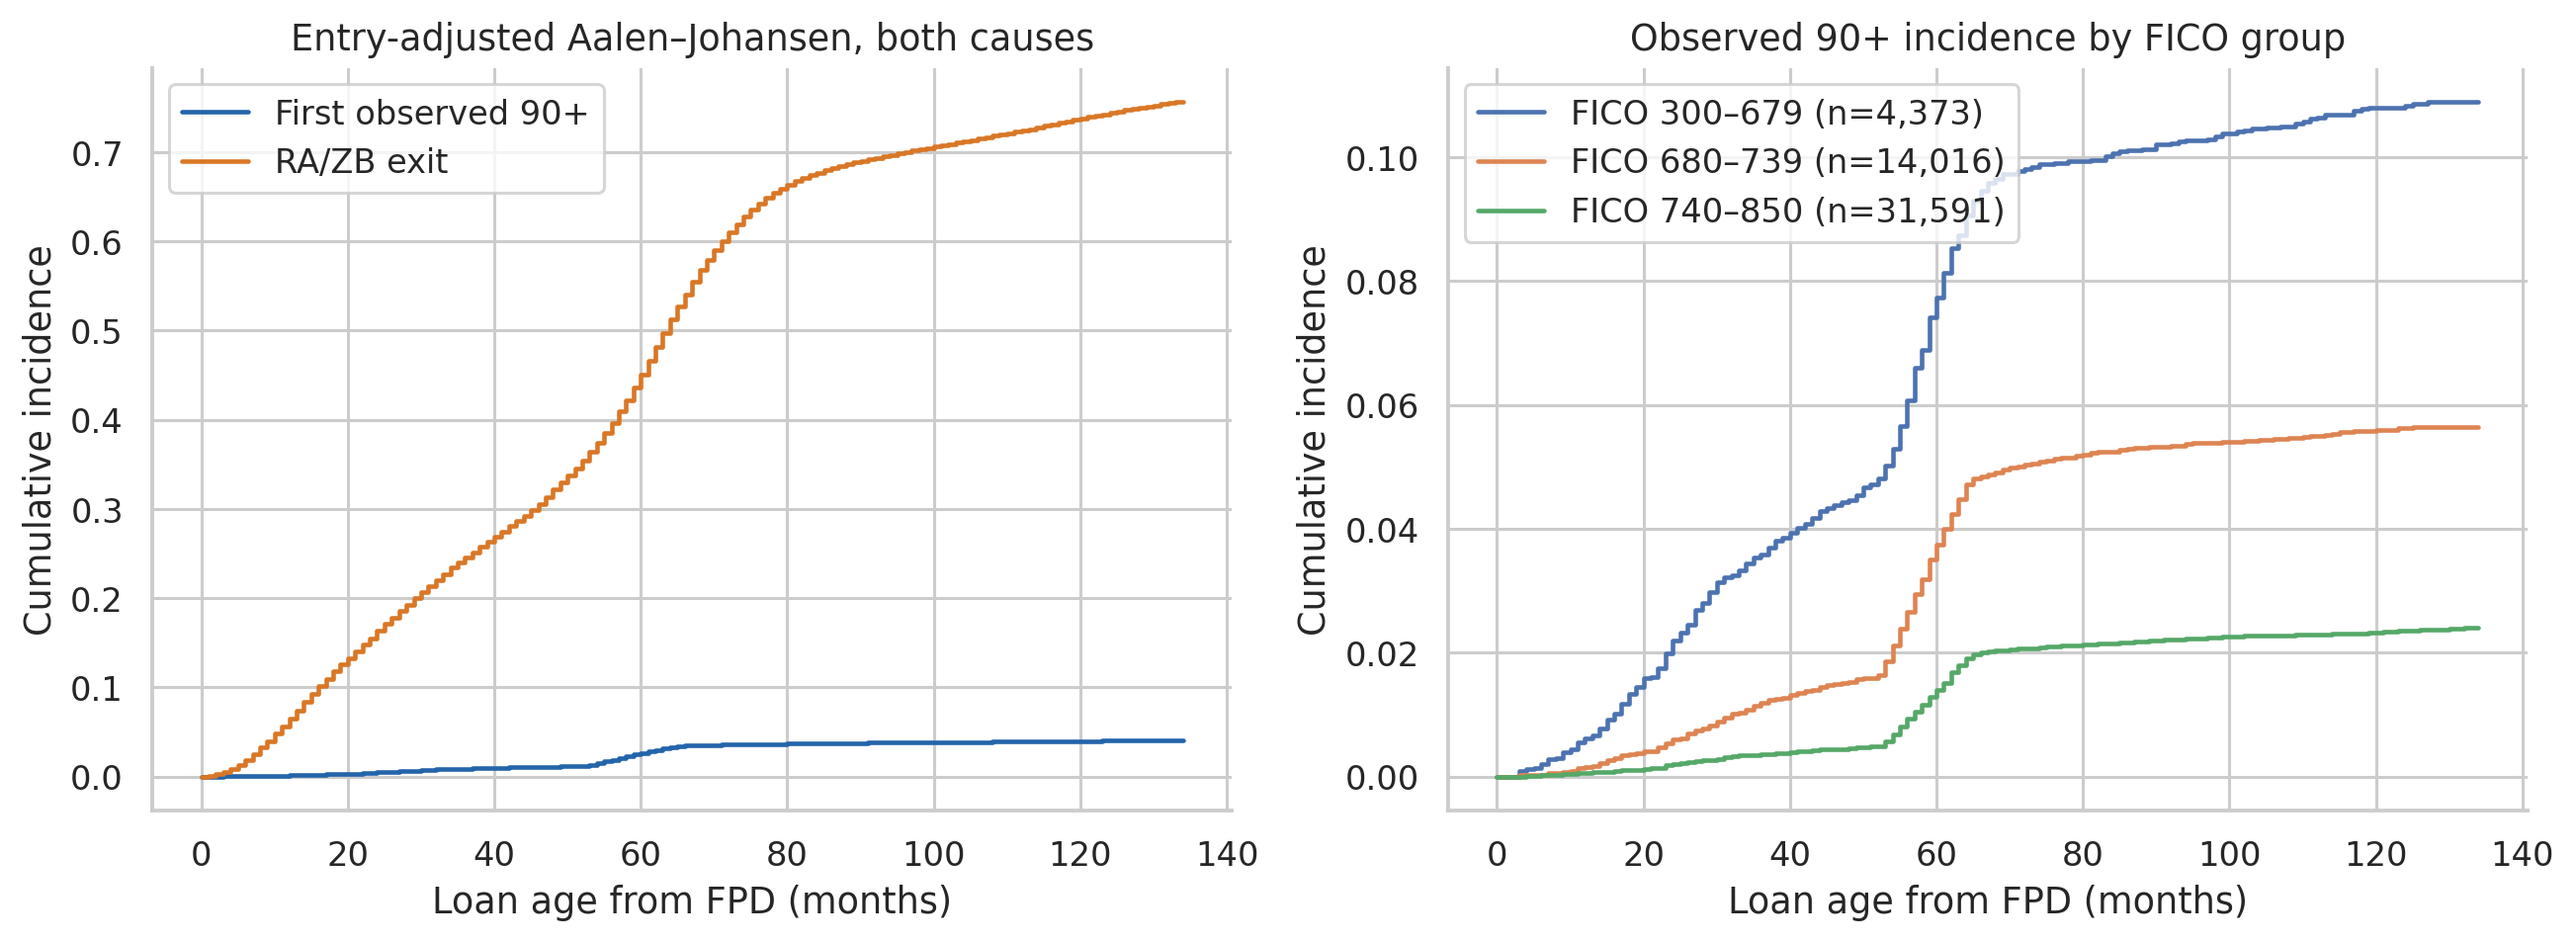

AJ tính hai nguyên nhân trong cùng risk set với delayed entry. Khác biệt FICO chưa điều chỉnh các yếu tố khác. Đường cong toàn cohort đòi hỏi giả định entry độc lập để ngoại suy về incidence từ FPD; nó không chứng minh được lịch sử trước acquisition là không có event.

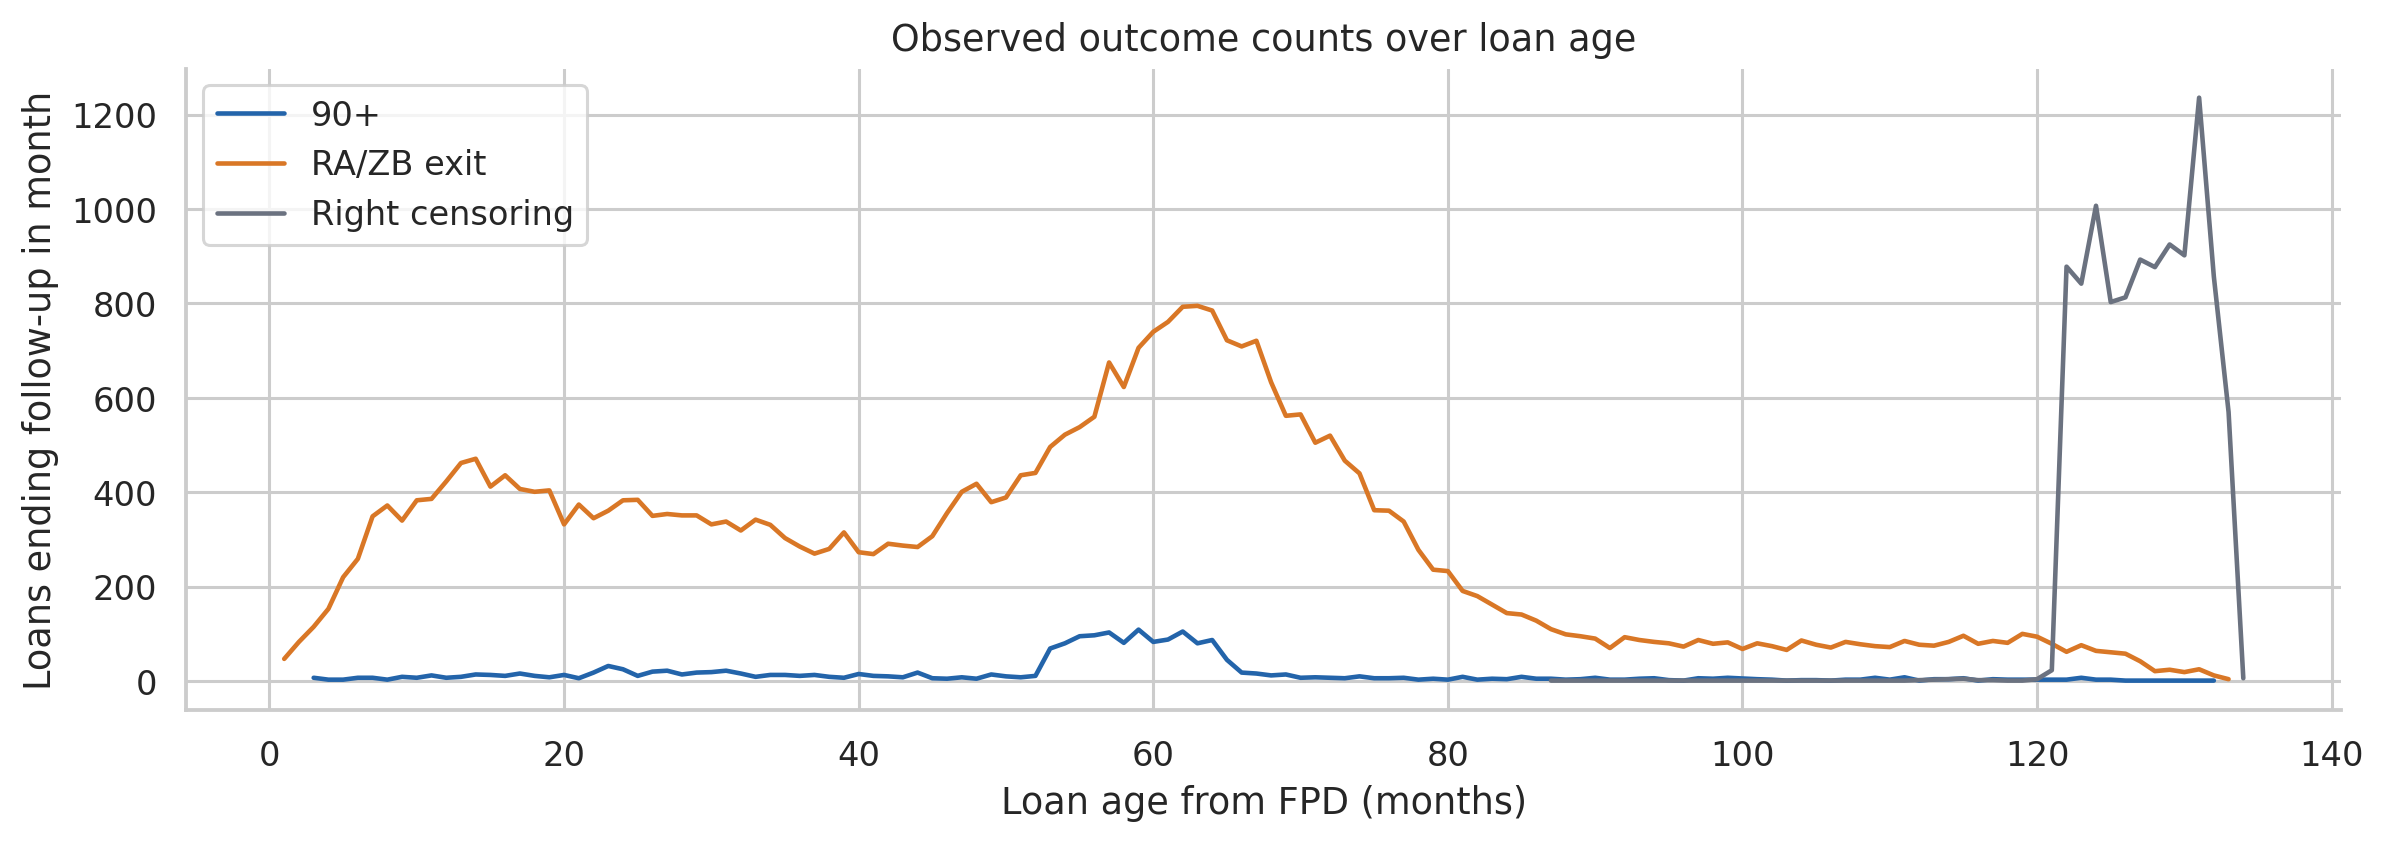

Đỉnh censoring cuối kỳ phản ánh giới hạn quan sát, không phải hazard của một biến cố kinh tế. Số event theo tháng phụ thuộc số khoản còn trong risk set và không thay thế cho hazard hoặc CIF.

In [8]:
grid=np.arange(0,int(cohort['T'].max())+1)
aj=aalen_johansen(cohort,grid)
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
for c,color,label in [('F1',BLUE,'First observed 90+'),('F2',ORANGE,'RA/ZB exit')]:
    ax[0].step(grid,aj[c],where='post',color=color,label=label)
fico_groups=pd.cut(cohort.classic_fico_score,[299,679,739,850],labels=['300–679','680–739','740–850'])
for label in fico_groups.cat.categories:
    subgroup=cohort.loc[fico_groups.eq(label)]
    ax[1].step(grid,aalen_johansen(subgroup,grid).F1,where='post',label=f'FICO {label} (n={len(subgroup):,})')
for a in ax: a.set(xlabel='Loan age from FPD (months)',ylabel='Cumulative incidence'); a.legend()
ax[0].set_title('Entry-adjusted Aalen–Johansen, both causes'); ax[1].set_title('Observed 90+ incidence by FICO group')
save_figure(fig,'aj_curves')
say('AJ tính hai nguyên nhân trong cùng risk set với delayed entry. Khác biệt FICO chưa điều chỉnh các yếu tố khác. Đường cong toàn cohort đòi hỏi giả định entry độc lập để ngoại suy về incidence từ FPD; nó không chứng minh được lịch sử trước acquisition là không có event.')
fig,ax=plt.subplots(figsize=(11,4))
for k,color,label in [(1,BLUE,'90+'),(2,ORANGE,'RA/ZB exit'),(0,GRAY,'Right censoring')]:
    counts=cohort.loc[cohort.J.eq(k)].groupby('T').size()
    ax.plot(counts.index,counts.values,label=label,color=color)
ax.set(xlabel='Loan age from FPD (months)',ylabel='Loans ending follow-up in month',title='Observed outcome counts over loan age'); ax.legend()
save_figure(fig,'events_by_month')
say('Đỉnh censoring cuối kỳ phản ánh giới hạn quan sát, không phải hazard của một biến cố kinh tế. Số event theo tháng phụ thuộc số khoản còn trong risk set và không thay thế cho hazard hoặc CIF.')

## 10–12. Preprocessing và lựa chọn đặc tả trên train

Encoder học median, pooling/reference, missing-indicator eligibility và constants chỉ từ training partition. DTI missing gần như HARP/structural missing; reference có cả modal và pooled rare levels. Không tự coi missing indicator là random-error group hoặc đồng thời thêm HARP trùng proxy.

A: linear baseline; B: FICO RCS 3 knots ở cả hai causes; C: B cộng targeted RCS LTV/UPB Cause 2. Ba knots là train quantiles 10/50/90%; mỗi RCS có **2 df tổng**, thêm 1 df so với tuyến tính. Fold validation có encoder/knots riêng từ phần training của fold.

**Quy tắc khóa trước OOF comparison:** giữ B khi training FICO LR p<.01 ở cả hai cause và OOF Brier không kém A quá một paired fold SE. Chỉ thêm LTV/UPB của C khi relative OOF gain>0.5% và gain>một paired fold SE. Fold SE là heuristic chọn độ phức tạp, không là formal coverage CI. Xét convergence, covariance, shape CI và support; không chỉ p-value.

P4 chỉ thử FICO×log(t/36) ở Cause 1 và rate×log(t/36) ở Cause 2. Giữ khi LR p<.005, HR contrast đổi>=25% giữa tuổi 12/60, max profile CIF delta>=0.002, đồng thời OOF gain>0.5% và>paired fold SE. Nếu không, giữ working specification nhỏ hơn và công khai non-PH. Legacy test chưa được đánh giá ở bước này.

In [9]:
development=functional_experiments(train)
functional_choice=development['selected']
working=development['candidates'][functional_choice]
time_development=time_experiments(train,development)
encoder=working['encoder']; models=time_development['models']
X_train=encoder.transform(train)
assert set(encoder.training_ids)==set(train.index)
assert not set(encoder.training_ids)&set(test.index)

# Full candidate parameter/CI evidence is displayed without exporting redundant CSVs.
candidate_coefficients=[]
for name,item in development['candidates'].items():
    candidate_table=pd.concat([m.coefficient_table() for m in item['models'].values()],ignore_index=True)
    candidate_coefficients.append(candidate_table.assign(specification=name))
    say(f"**{name}: all coefficients and model-based confidence intervals**")
    display(candidate_table)
development['coefficient_tables']=pd.concat(candidate_coefficients,ignore_index=True)
# Predeclared median and one-variable train-quantile profiles, identical across A/B/C.
profile_raw=reference_rows(encoder,7)
profile_names=['median','FICO_q10','FICO_q90','LTV_q10','LTV_q90','UPB_q10','UPB_q90']
for row,variable,q in [(1,'classic_fico_score',.1),(2,'classic_fico_score',.9),
                        (3,'original_ltv',.1),(4,'original_ltv',.9),
                        (5,'original_upb',.1),(6,'original_upb',.9)]:
    profile_raw.loc[row,variable]=train[variable].quantile(q)
profile_records=[]
for name,item in development['candidates'].items():
    probability=predict_cif(item['models'],item['encoder'].transform(profile_raw),[12,36,60,120])
    for i,label in enumerate(profile_names):
        for j,h in enumerate([12,36,60,120]):
            profile_records.append({'specification':name,'profile':label,'horizon':h,'CIF1':float(probability[i,j,0])})
development['profile_CIFs']=pd.DataFrame(profile_records)
display(development['profile_CIFs'].pivot(index=['specification','horizon'],columns='profile',values='CIF1'))

selection_locked_utc=datetime.now(timezone.utc).isoformat()
# Only now transform the reused holdout for final descriptive evaluation.
X_test=encoder.transform(test)
assert X_train.columns.equals(X_test.columns)
(ROOT/'artifacts/preprocessing.json').write_text(json.dumps(encoder.manifest(),ensure_ascii=False,indent=2),encoding='utf-8')
display(development['comparison'])
display(development['likelihood_ratios'])
display(development['paired_comparisons'])
display(time_development['comparisons'])
display(time_development['evidence'])
display(pd.DataFrame({'median_train':encoder.medians,'scale':encoder.continuous}))
display(pd.DataFrame({'reference':encoder.references,'retained_levels':encoder.levels}))
display(pd.DataFrame({'variable':X_train.columns,'VIF':np.diag(np.linalg.inv(X_train.corr()))}).sort_values('VIF',ascending=False))
dev_table=development['comparison'].assign(stage='P3')
tv_table=time_development['comparisons'].assign(stage='P4')
table(pd.concat([dev_table,tv_table],ignore_index=True),'model_development_comparison')
say(f"Train-only selection: **{functional_choice}**, time specification **{time_development['selected']}**. "
    f"Parameters by cause: **{len(models[1].beta)} / {len(models[2].beta)}**. "
    "Knots/transformations được lưu trong preprocessing.json. Các CV/LR/PH comparisons ở trên dùng cùng train/folds; test không được dùng chọn model.")


**A_linear: all coefficients and model-based confidence intervals**

,cause,variable,beta,se,HR,HR_low,HR_high,p,interpretation
0,1,classic_fico_score,-0.467305,0.025606,0.626689,0.596014,0.658943,2.064941e-74,linear coefficient conditional on other design...
1,1,original_dti,0.276547,0.034980,1.318569,1.231195,1.412143,2.662623e-15,linear coefficient conditional on other design...
2,1,original_ltv,0.079413,0.017980,1.082652,1.045164,1.121484,1.001426e-05,linear coefficient conditional on other design...
3,1,original_interest_rate,0.628657,0.084795,1.875091,1.587974,2.214120,1.226803e-13,linear coefficient conditional on other design...
4,1,original_upb,0.183416,0.023018,1.201314,1.148320,1.256754,1.609365e-15,linear coefficient conditional on other design...
5,1,original_loan_term,-0.048157,0.063745,0.952984,0.841056,1.079809,4.499754e-01,linear coefficient conditional on other design...
6,1,mortgage_insurance_percentage,0.073565,0.027849,1.076339,1.019162,1.136723,8.252157e-03,linear coefficient conditional on other design...
7,1,original_dti__missing,0.180002,0.098407,1.197219,0.987206,1.451910,6.737689e-02,linear coefficient conditional on other design...
8,1,occupancy_status__I,-0.084441,0.103222,0.919026,0.750695,1.125102,4.133244e-01,linear coefficient conditional on other design...
9,1,occupancy_status__S,0.071426,0.160254,1.074038,0.784528,1.470385,6.558130e-01,linear coefficient conditional on other design...


**B_FICO_RCS: all coefficients and model-based confidence intervals**

,cause,variable,beta,se,HR,HR_low,HR_high,p,interpretation
0,1,classic_fico_score,-0.310410,0.041442,0.733147,0.675951,0.795182,6.872872e-14,linear coefficient conditional on other design...
1,1,original_dti,0.260167,0.035192,1.297147,1.210690,1.389777,1.438304e-13,linear coefficient conditional on other design...
2,1,original_ltv,0.070459,0.018108,1.073000,1.035585,1.111768,9.986100e-05,linear coefficient conditional on other design...
3,1,original_interest_rate,0.626683,0.085139,1.871392,1.583774,2.211243,1.829222e-13,linear coefficient conditional on other design...
4,1,original_upb,0.183218,0.023009,1.201076,1.148114,1.256482,1.679860e-15,linear coefficient conditional on other design...
5,1,original_loan_term,-0.049568,0.063890,0.951640,0.839631,1.078592,4.378457e-01,linear coefficient conditional on other design...
6,1,mortgage_insurance_percentage,0.071130,0.027927,1.073721,1.016528,1.134131,1.086531e-02,linear coefficient conditional on other design...
7,1,original_dti__missing,0.289618,0.099268,1.335917,1.099716,1.622850,3.528151e-03,linear coefficient conditional on other design...
8,1,occupancy_status__I,-0.093907,0.103288,0.910367,0.743525,1.114647,3.632583e-01,linear coefficient conditional on other design...
9,1,occupancy_status__S,0.069142,0.160181,1.071589,0.782851,1.466822,6.659959e-01,linear coefficient conditional on other design...


**C_targeted_RCS: all coefficients and model-based confidence intervals**

,cause,variable,beta,se,HR,HR_low,HR_high,p,interpretation
0,1,classic_fico_score,-0.310410,0.041442,0.733147,0.675951,0.795182,6.872872e-14,linear coefficient conditional on other design...
1,1,original_dti,0.260167,0.035192,1.297147,1.210690,1.389777,1.438304e-13,linear coefficient conditional on other design...
2,1,original_ltv,0.070459,0.018108,1.073000,1.035585,1.111768,9.986100e-05,linear coefficient conditional on other design...
3,1,original_interest_rate,0.626683,0.085139,1.871392,1.583774,2.211243,1.829222e-13,linear coefficient conditional on other design...
4,1,original_upb,0.183218,0.023009,1.201076,1.148114,1.256482,1.679860e-15,linear coefficient conditional on other design...
5,1,original_loan_term,-0.049568,0.063890,0.951640,0.839631,1.078592,4.378457e-01,linear coefficient conditional on other design...
6,1,mortgage_insurance_percentage,0.071130,0.027927,1.073721,1.016528,1.134131,1.086531e-02,linear coefficient conditional on other design...
7,1,original_dti__missing,0.289618,0.099268,1.335917,1.099716,1.622850,3.528151e-03,linear coefficient conditional on other design...
8,1,occupancy_status__I,-0.093907,0.103288,0.910367,0.743525,1.114647,3.632583e-01,linear coefficient conditional on other design...
9,1,occupancy_status__S,0.069142,0.160181,1.071589,0.782851,1.466822,6.659959e-01,linear coefficient conditional on other design...


... (6 outputs left out)

,median_train,scale
classic_fico_score,760.0,50
original_dti,35.0,10
original_ltv,78.0,10
original_interest_rate,4.0,1
original_upb,200000.0,100000
original_loan_term,360.0,120
mortgage_insurance_percentage,0.0,10


,reference,retained_levels
occupancy_status,P,"[P, I, S]"
loan_purpose,P,"[P, C, N]"
property_type,SF,"[SF, CO, PU]"
first_time_homebuyer_indicator,N,"[N, Y]"
number_of_units,1,"[1, 2]"
number_of_borrowers,2,"[2, 1]"


,variable,VIF
0,classic_fico_score,4.788937
17,classic_fico_score__rcs,4.554302
3,original_interest_rate,2.581930
5,original_loan_term,2.389127
11,loan_purpose__N,1.878755
6,mortgage_insurance_percentage,1.714496
10,loan_purpose__C,1.708521
2,original_ltv,1.677689
14,first_time_homebuyer_indicator__Y,1.427179
7,original_dti__missing,1.406048


Train-only selection: **B_FICO_RCS**, time specification **static**. Parameters by cause: **18 / 18**. Knots/transformations được lưu trong preprocessing.json. Các CV/LR/PH comparisons ở trên dùng cùng train/folds; test không được dùng chọn model.

## 13–14. Working model được chọn và diễn giải tham số

Hai cause-specific Cox dùng Breslow ties, strict delayed entry và covariance từ observed information. A tuyến tính gốc được giữ riêng; các hệ số dưới đây thuộc final working specification được chọn bằng train/internal validation.

Với spline, exp(beta) của một basis không phải HR cố định cho mỗi tăng 50 điểm FICO. Phải dùng **joint contrast của toàn bộ basis** và covariance để tính CI. Nếu một time effect được giữ, HR(t) và prediction phải dùng cùng t; không dùng exit T làm covariate thời gian. Remaining PH limitations vẫn được báo.

,cause,events_train,parameters,partial_log_likelihood,max_abs_score,warnings
0,1,1514,18,-14511.007424,7.874812e-13,[]
1,2,27979,18,-277055.035385,5.342393e-12,[]


,cause,variable,beta,se,HR,HR_low,HR_high,p,interpretation
0,1,classic_fico_score,-0.310410,0.041442,0.733147,0.675951,0.795182,6.872872e-14,linear coefficient conditional on other design...
1,1,original_dti,0.260167,0.035192,1.297147,1.210690,1.389777,1.438304e-13,linear coefficient conditional on other design...
2,1,original_ltv,0.070459,0.018108,1.073000,1.035585,1.111768,9.986100e-05,linear coefficient conditional on other design...
3,1,original_interest_rate,0.626683,0.085139,1.871392,1.583774,2.211243,1.829222e-13,linear coefficient conditional on other design...
4,1,original_upb,0.183218,0.023009,1.201076,1.148114,1.256482,1.679860e-15,linear coefficient conditional on other design...
5,1,original_loan_term,-0.049568,0.063890,0.951640,0.839631,1.078592,4.378457e-01,linear coefficient conditional on other design...
6,1,mortgage_insurance_percentage,0.071130,0.027927,1.073721,1.016528,1.134131,1.086531e-02,linear coefficient conditional on other design...
7,1,original_dti__missing,0.289618,0.099268,1.335917,1.099716,1.622850,3.528151e-03,linear coefficient conditional on other design...
8,1,occupancy_status__I,-0.093907,0.103288,0.910367,0.743525,1.114647,3.632583e-01,linear coefficient conditional on other design...
9,1,occupancy_status__S,0.069142,0.160181,1.071589,0.782851,1.466822,6.659959e-01,linear coefficient conditional on other design...


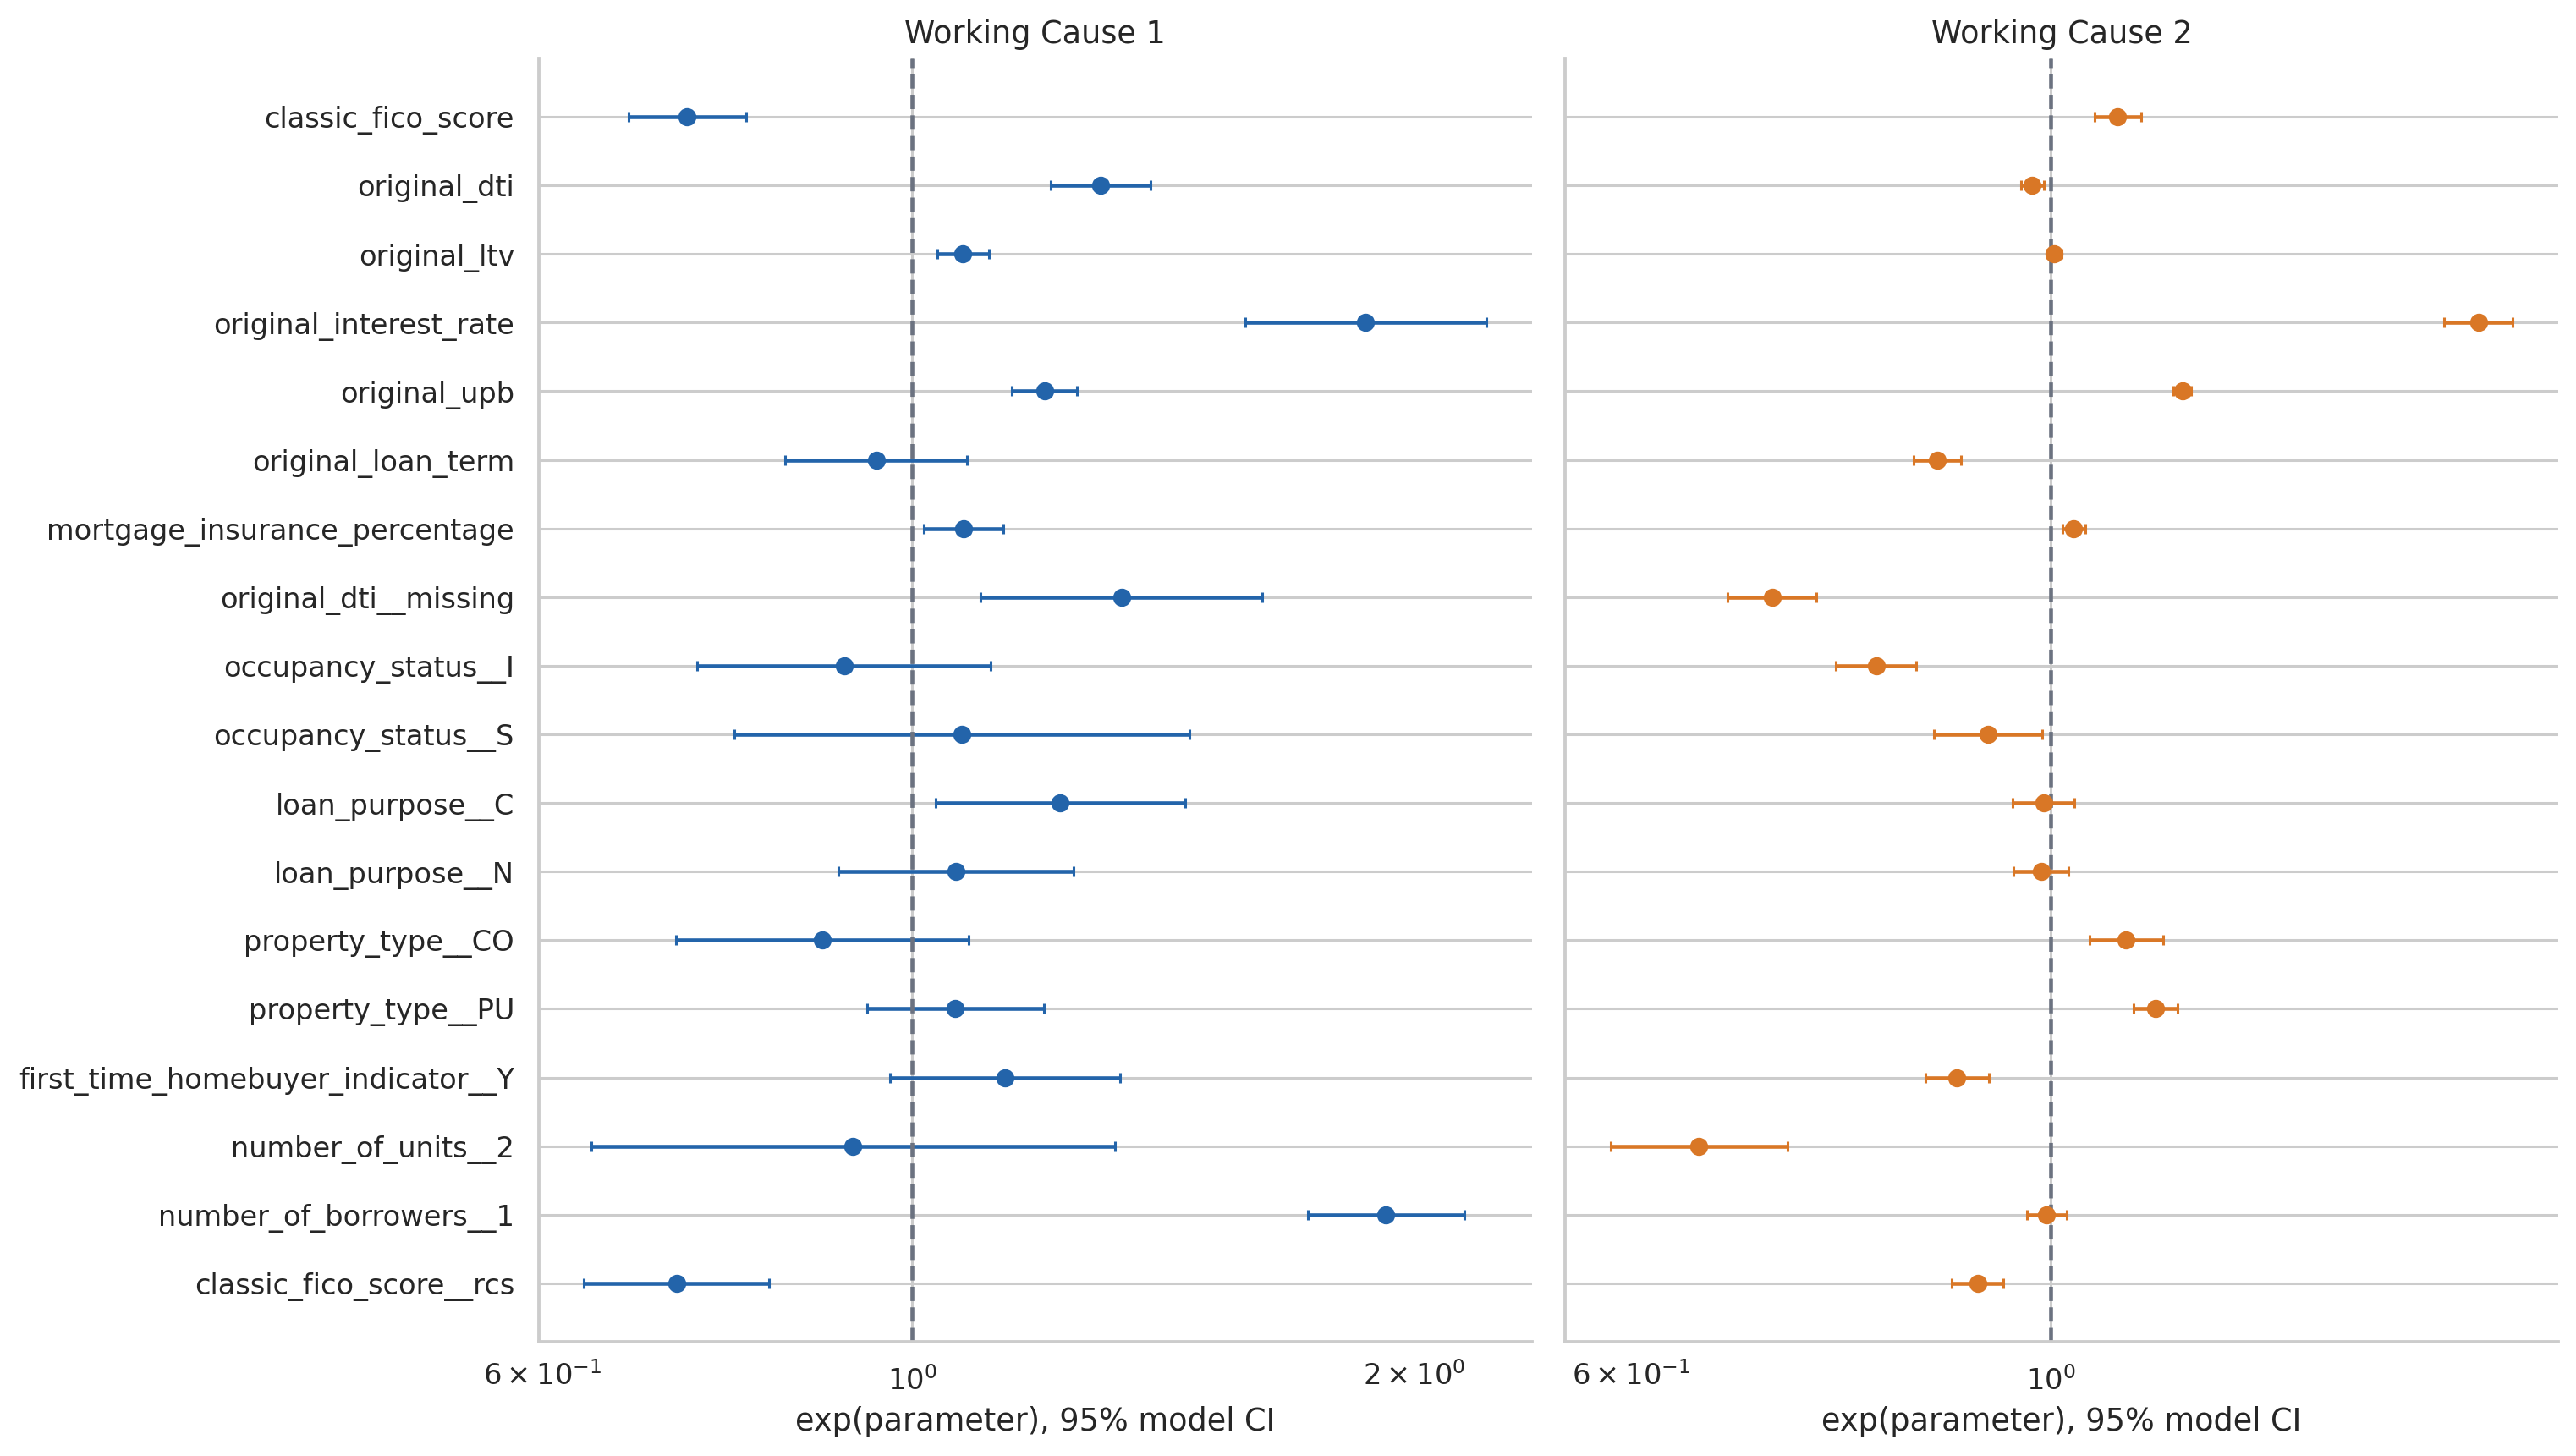

,value,time,HR,low,high,cause,variable,reference
0,650,36,2.433095,2.138196,2.768667,1,classic_fico_score,760.0
1,700,36,1.779860,1.668785,1.898329,1,classic_fico_score,760.0
2,750,36,1.141633,1.120460,1.163205,1,classic_fico_score,760.0
3,800,36,0.504098,0.442821,0.573854,1,classic_fico_score,760.0
4,650,36,0.883007,0.843373,0.924503,2,classic_fico_score,760.0
5,700,36,0.957960,0.939540,0.976741,2,classic_fico_score,760.0
6,750,36,1.002746,0.999360,1.006143,2,classic_fico_score,760.0
7,800,36,0.948189,0.924581,0.972400,2,classic_fico_score,760.0


FICO contrasts là HR so với median train, đã kết hợp linear+spline và covariance. Đây là liên hệ của working model có non-PH limitations, không phải tỷ số CIF, hiệu ứng nhân quả hoặc lifetime default risk. Model-based CI không bao gồm specification selection uncertainty.

In [10]:
coefficients=pd.concat([m.coefficient_table() for m in models.values()],ignore_index=True)
table(coefficients,'cox_coefficients')
fit_summary=pd.DataFrame([{'cause':k,'events_train':int(train.J.eq(k).sum()),'parameters':len(m.beta),
 'partial_log_likelihood':m.log_likelihood,'max_abs_score':m.max_abs_score,'warnings':str(m.warnings)} for k,m in models.items()])
display(fit_summary)
display(coefficients)
fig,axes=plt.subplots(1,2,figsize=(14,8),sharey=True)
for ax,k in zip(axes,[1,2]):
    d=coefficients.loc[coefficients.cause.eq(k)].iloc[::-1];y=np.arange(len(d))
    ax.errorbar(d.HR,y,xerr=np.vstack([d.HR-d.HR_low,d.HR_high-d.HR]),fmt='o',color=BLUE if k==1 else ORANGE,capsize=2)
    ax.set_yticks(y,d.variable);ax.axvline(1,color=GRAY,ls='--');ax.set_xscale('log')
    ax.set(xlabel='exp(parameter), 95% model CI',title=f'Working Cause {k}')
save_figure(fig,'forest_hr')
contrast_rows=[]
for k,m in models.items():
    contrast=hazard_contrasts(m,encoder,'classic_fico_score',[650,700,750,800])
    contrast_rows.append(contrast.assign(cause=k,variable='classic_fico_score',reference=encoder.medians['classic_fico_score']))
contrasts=pd.concat(contrast_rows,ignore_index=True)
table(contrasts,'hazard_contrasts');display(contrasts)
say('FICO contrasts là HR so với median train, đã kết hợp linear+spline và covariance. Đây là liên hệ của working model có non-PH limitations, không phải tỷ số CIF, hiệu ứng nhân quả hoặc lifetime default risk. Model-based CI không bao gồm specification selection uncertainty.')


## 14. Baseline hazards và CIF cá nhân

Các nguyên nhân được tích hợp trong cùng survival process. Profile raw giữ continuous ở median và categorical ở reference; biến spline được encoder tính lại từ raw profile, không tự đổi một cột linear mà bỏ quên basis. Forecast trước conditioning time bị từ chối.

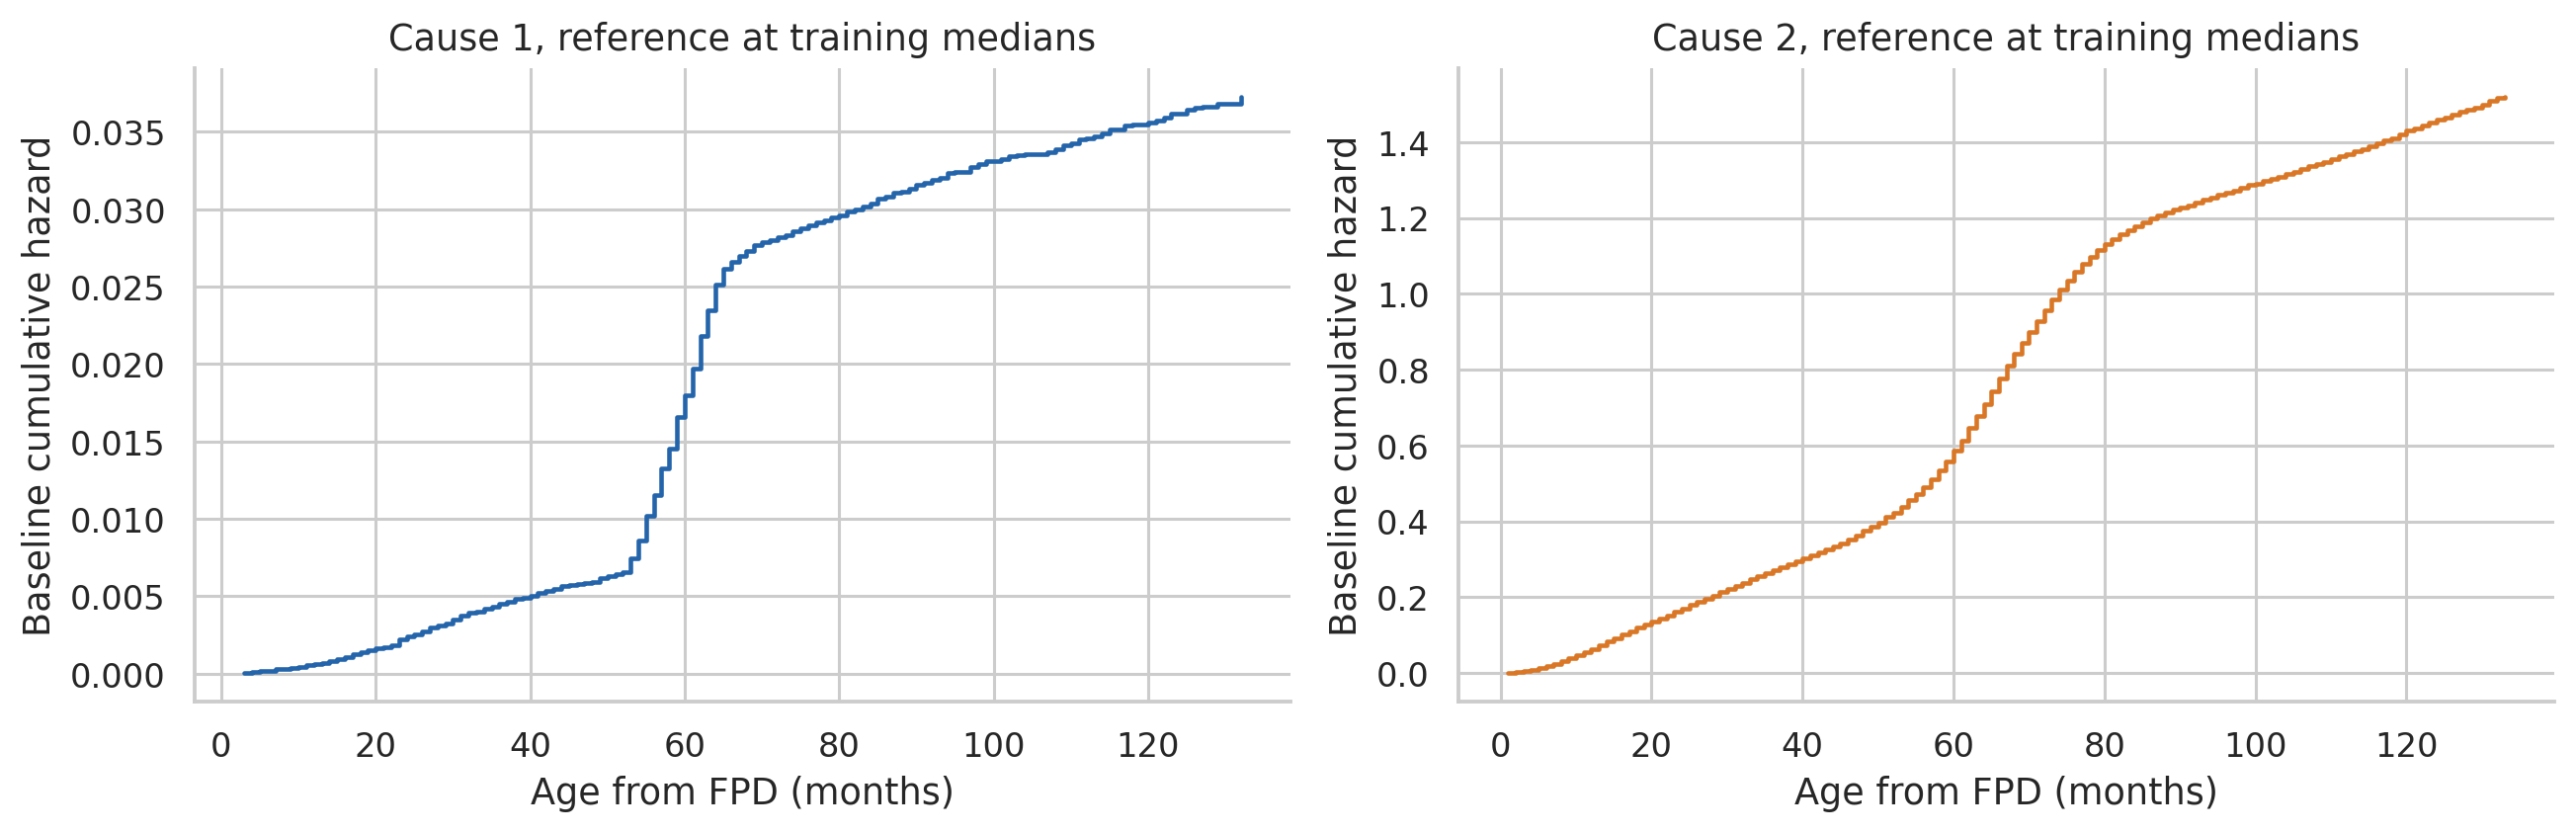

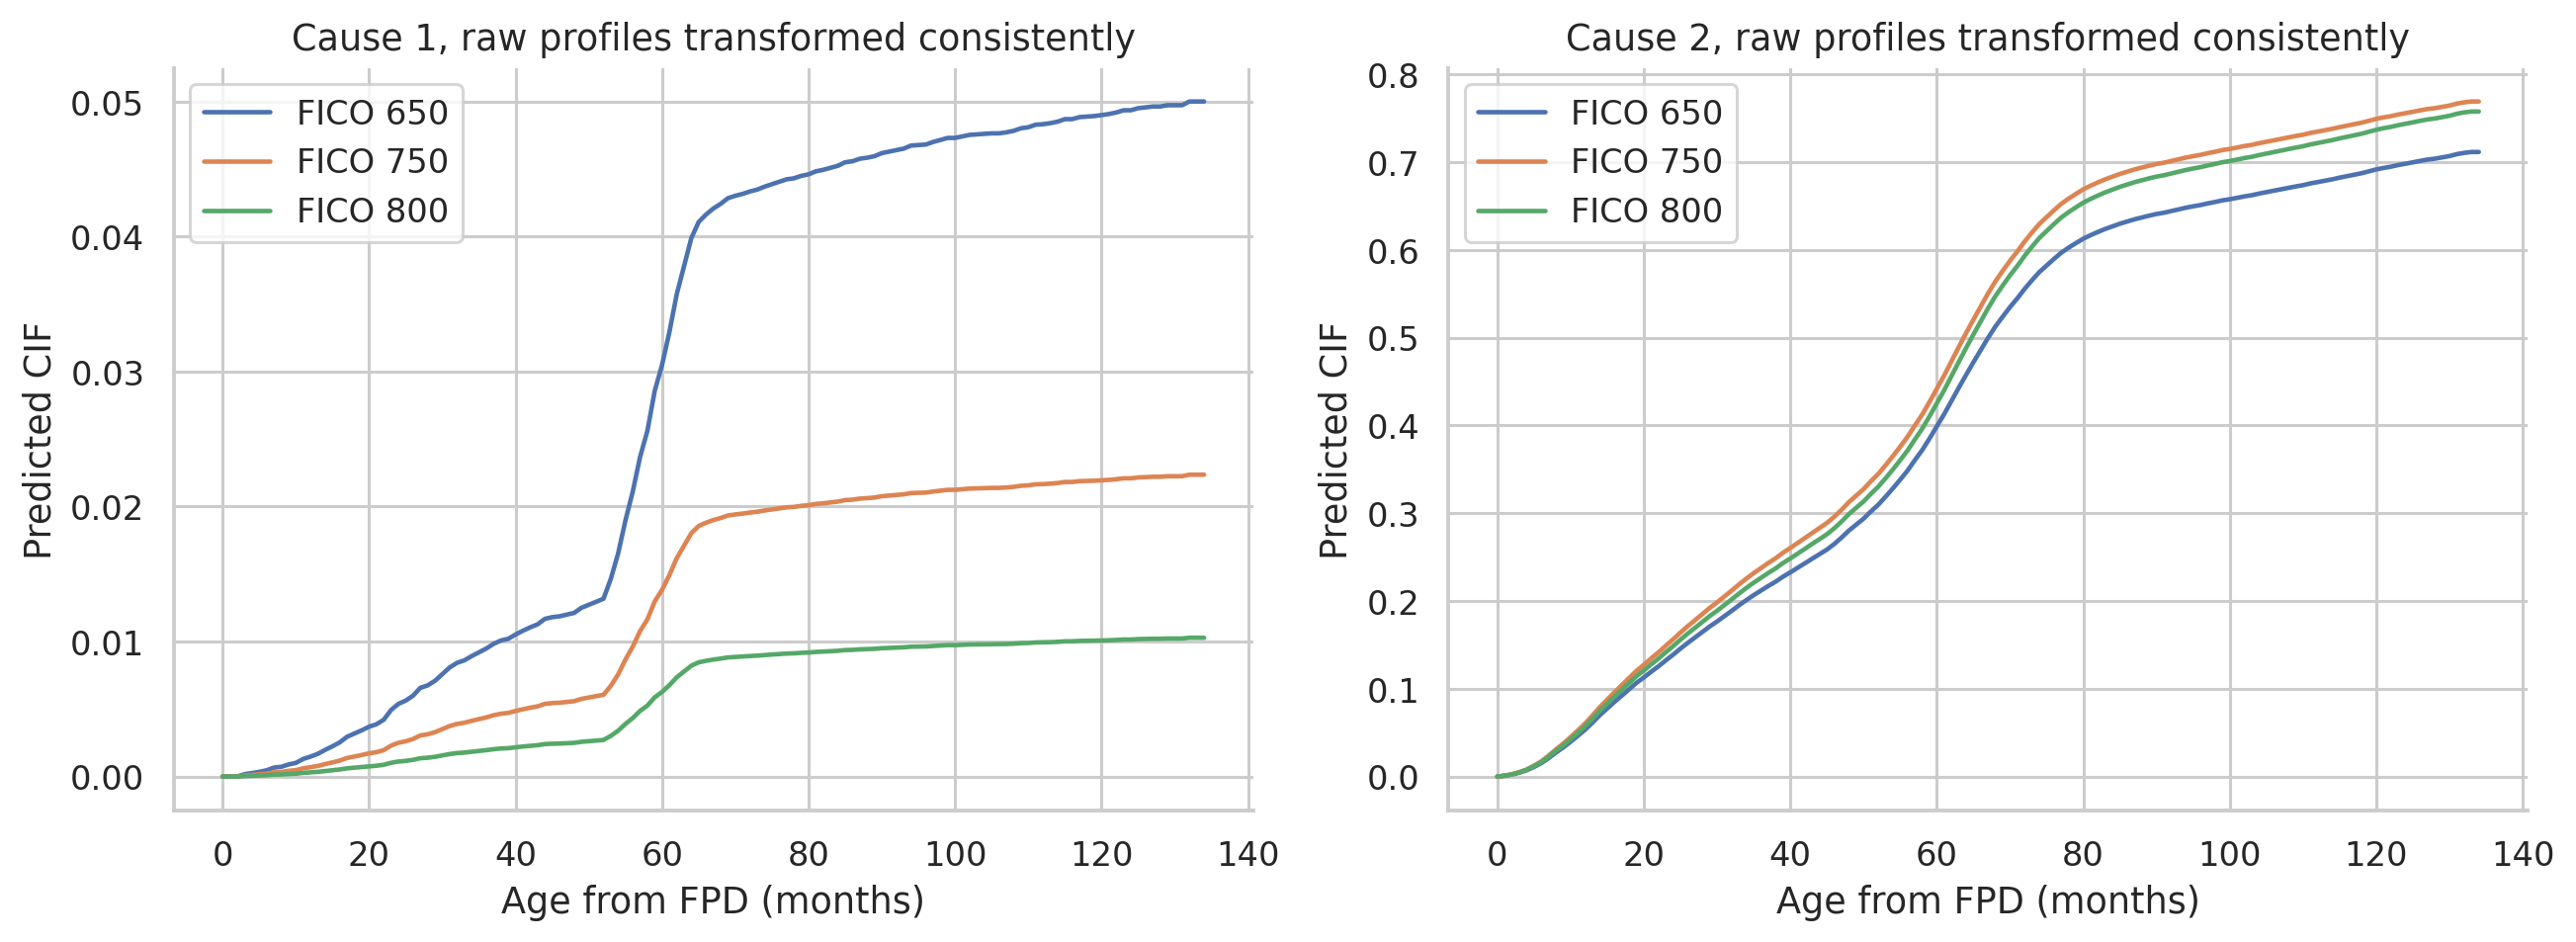

Profile curves là model-implied, không phải incidence thực nghiệm. Conditional-entry demo chỉ dùng loans có L<=12 để mọi horizon đều không trước entry; đây không phải primary validation population. Primary ranking/absolute-risk validation vẫn giới hạn L=0.

In [11]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,k in zip(axes,[1,2]):
    baseline=models[k].baseline
    ax.step(baseline.month,baseline.H0,where='post',color=BLUE if k==1 else ORANGE)
    ax.set(xlabel='Age from FPD (months)',ylabel='Baseline cumulative hazard',title=f'Cause {k}, reference at training medians')
save_figure(fig,'baseline_hazard')
raw_profiles=reference_rows(encoder,3);raw_profiles['classic_fico_score']=[650,750,800]
raw_profiles.index=['FICO 650','FICO 750','FICO 800']
profiles=encoder.transform(raw_profiles);ages=np.arange(0,135)
profile_prob=predict_cif(models,profiles,ages)
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for i,label in enumerate(profiles.index):
    for k,ax in enumerate(axes):ax.plot(ages,profile_prob[i,:,k],label=label)
for k,ax in enumerate(axes):ax.set(xlabel='Age from FPD (months)',ylabel='Predicted CIF',title=f'Cause {k+1}, raw profiles transformed consistently');ax.legend()
save_figure(fig,'profile_cif')
eligible=test.loc[test.L.le(12)]
entry_prob=predict_cif(models,encoder.transform(eligible),[12,36,60,120],start=eligible.L.to_numpy())
assert np.isfinite(entry_prob).all()
say('Profile curves là model-implied, không phải incidence thực nghiệm. Conditional-entry demo chỉ dùng loans có L<=12 để mọi horizon đều không trước entry; đây không phải primary validation population. Primary ranking/absolute-risk validation vẫn giới hạn L=0.')


## 15. Diagnostics sau sửa functional form

Formal efficient score test dùng đúng Breslow risk sets, nuisance-adjusted information và log-time interaction; không phải correlation test. Static specification kiểm tra các coefficient còn giả định PH. Nếu TV được giữ, kiểm tra **remaining constant terms conditional on TV**, loại terms đã có time interaction để tránh redundant/singular test.

Scaled Schoenfeld, martingale và one-step DFBETA dùng actual design và integrated hazard chỉ trong $(L,T]$. Full-cohort/P2 tests và finite-difference tests kiểm tra numerical consistency; convergence không xác nhận PH. Functional-form quadratic scores bên dưới thuộc **A linear train diagnostic**, không được ghi nhãn là xác nhận final RCS shape.

,variable,chi2,df,p,p_holm,cause
0,GLOBAL,90.817659,18,1.029517e-11,NaN,1
1,classic_fico_score,51.277184,1,8.020239e-13,1.443643e-11,1
3,original_ltv,9.880838,1,1.670089e-03,2.171115e-02,1
4,original_interest_rate,16.784085,1,4.188311e-05,6.701297e-04,1
5,original_upb,16.197857,1,5.705863e-05,8.558794e-04,1
8,original_dti__missing,36.668822,1,1.400007e-09,2.380012e-08,1
18,classic_fico_score__rcs,15.762585,1,7.180865e-05,1.005321e-03,1
19,GLOBAL,483.181083,18,3.566494e-91,NaN,2
21,original_dti,21.242140,1,4.047667e-06,4.452434e-05,2
22,original_ltv,33.699359,1,6.432186e-09,7.718624e-08,2


,cause,variable,chi2,p,p_holm,model
0,1,classic_fico_score,32.152703,1.425183e-08,7.125916e-08,A_linear_train_diagnostic
1,1,original_dti,4.632835,3.136569e-02,1.254628e-01,A_linear_train_diagnostic
2,1,original_ltv,0.501199,4.789738e-01,6.204738e-01,A_linear_train_diagnostic
3,1,original_interest_rate,1.029667,3.102369e-01,6.204738e-01,A_linear_train_diagnostic
4,1,original_upb,3.029555,8.176044e-02,2.452813e-01,A_linear_train_diagnostic
5,2,classic_fico_score,22.858660,1.743619e-06,8.718095e-06,A_linear_train_diagnostic
6,2,original_dti,1.729732,1.884451e-01,3.768903e-01,A_linear_train_diagnostic
7,2,original_ltv,8.004633,4.665782e-03,1.399735e-02,A_linear_train_diagnostic
8,2,original_interest_rate,0.002431,9.606726e-01,9.606726e-01,A_linear_train_diagnostic
9,2,original_upb,22.786488,1.810341e-06,8.718095e-06,A_linear_train_diagnostic


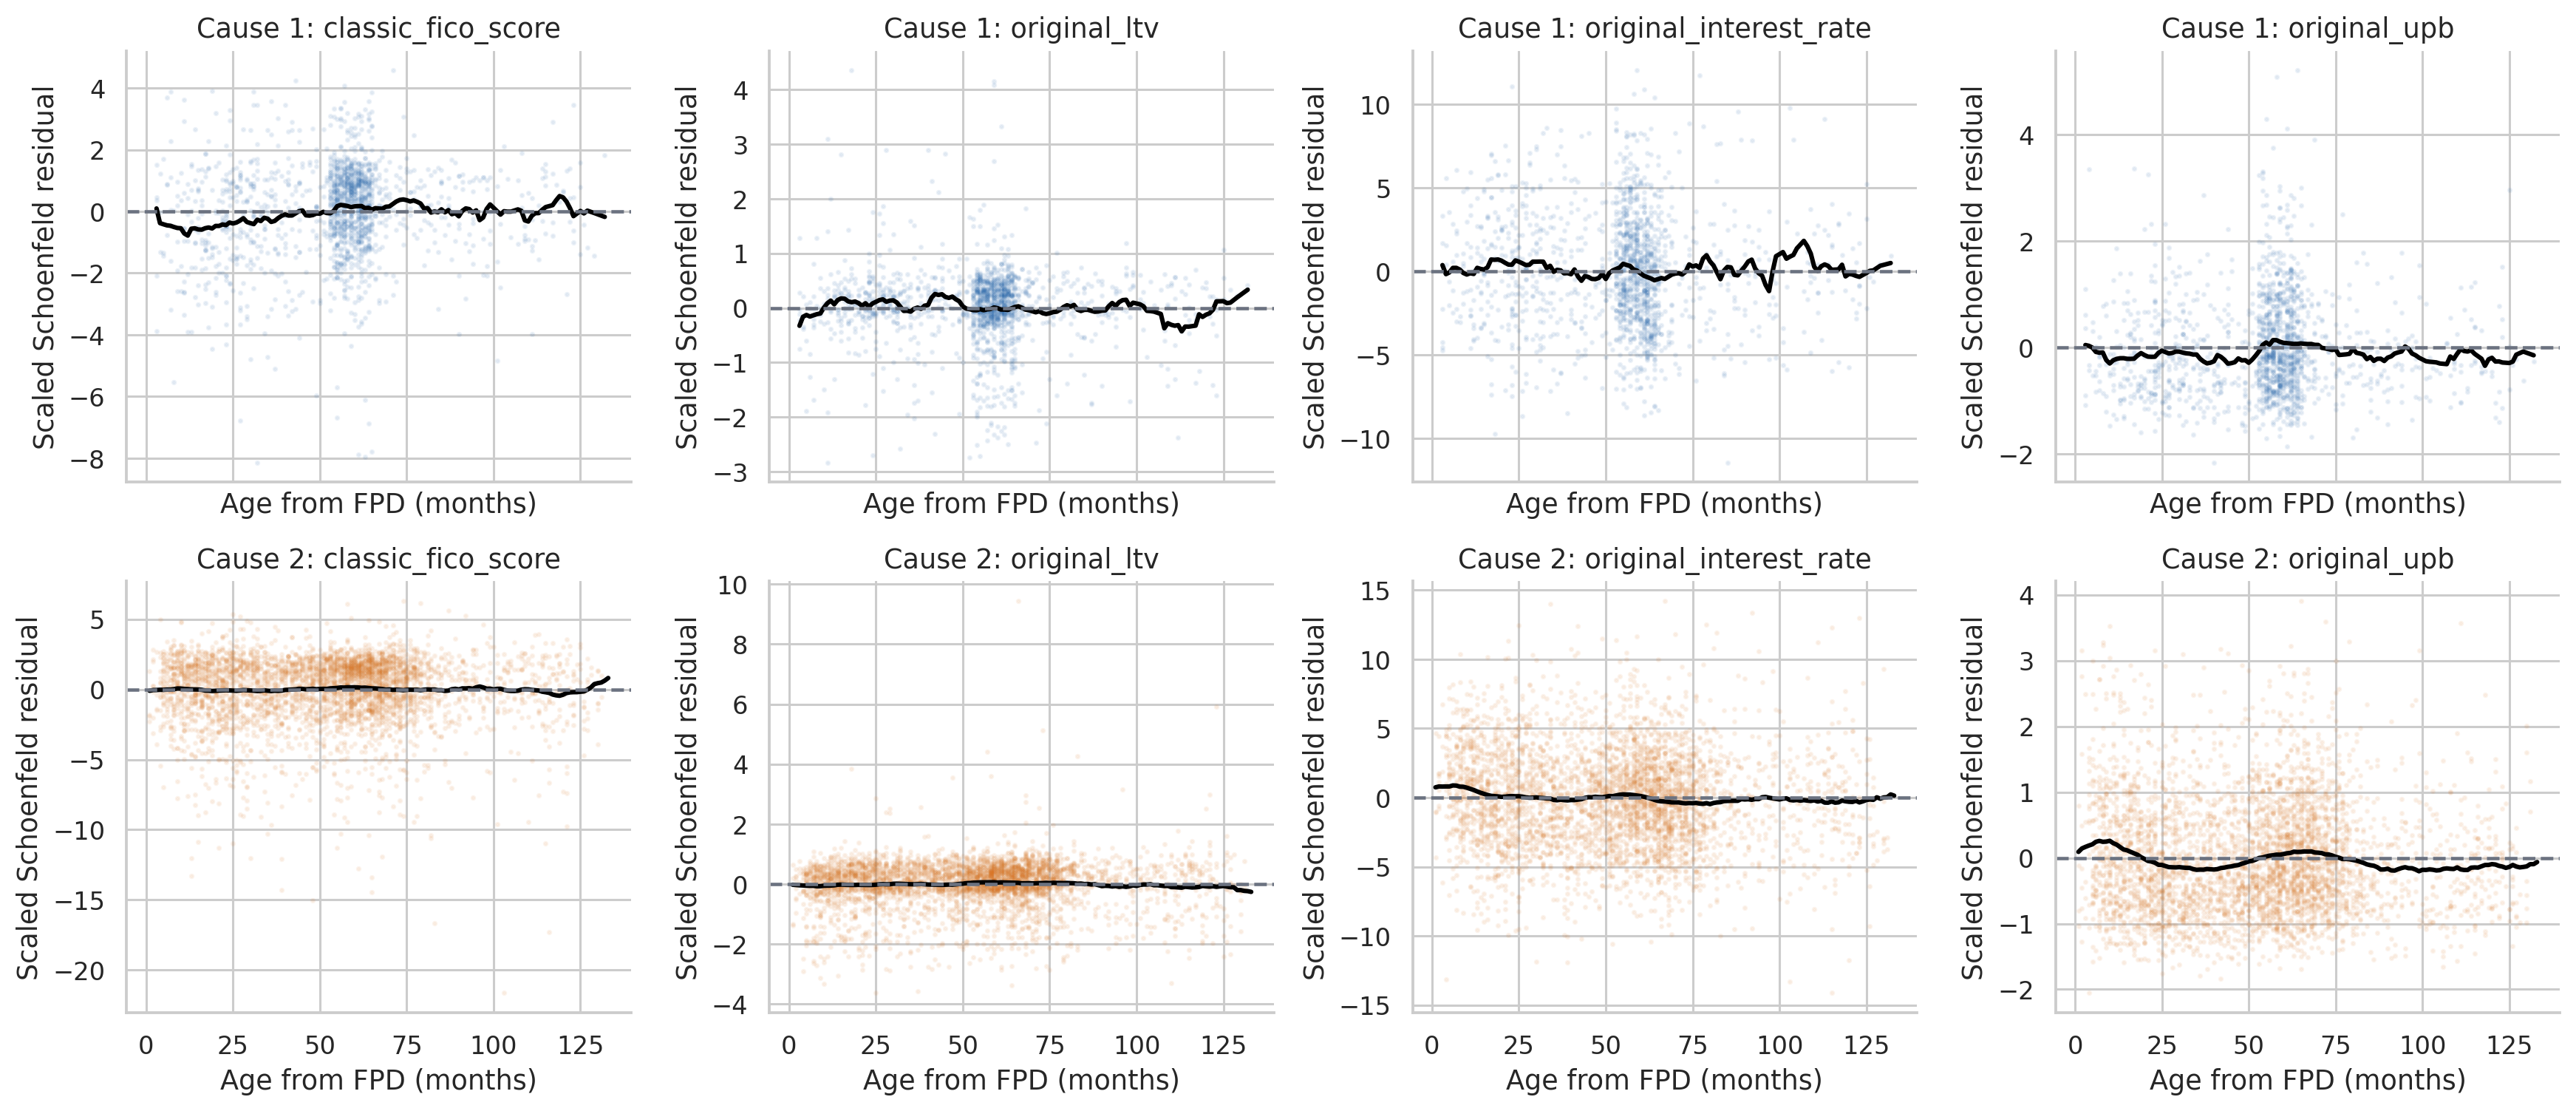

Non-PH vẫn tồn tại sau RCS. Time candidates có HR variation nhưng không đạt điều kiện OOF/predictive materiality để giữ. Final specification là working model, không phải bằng chứng HR thật bất biến theo tuổi; p-value nhỏ không tự đo practical CIF impact.

In [12]:
diag={k:diagnostics(train,X_train,m) for k,m in models.items()}
ph=pd.concat([d['ph'].assign(cause=k) for k,d in diag.items()],ignore_index=True)
linear=development['candidates']['A_linear']
functional=pd.concat([functional_form_scores(train,linear['encoder'].transform(train),m,
 ['classic_fico_score','original_dti','original_ltv','original_interest_rate','original_upb']) for m in linear['models'].values()],ignore_index=True)
functional['model']='A_linear_train_diagnostic'
table(ph,'ph_score_tests');table(functional,'functional_form_scores')
display(ph.loc[ph.variable.eq('GLOBAL')|ph.p_holm.lt(.05)])
display(functional)
chosen=['classic_fico_score','original_ltv','original_interest_rate','original_upb']
fig,axes=plt.subplots(2,4,figsize=(16,7),sharex=True)
for row,k in enumerate([1,2]):
    residual=diag[k]['scaled_schoenfeld'];sampled=residual.sample(min(len(residual),4000),random_state=SEED)
    for ax,c in zip(axes[row],chosen):
        ax.scatter(sampled.month,sampled[c],s=2,alpha=.08,color=BLUE if k==1 else ORANGE)
        means=residual.groupby('month')[c].mean().rolling(9,center=True,min_periods=3).mean()
        ax.plot(means.index,means,color='black',lw=2);ax.axhline(0,color=GRAY,ls='--')
        ax.set(title=f'Cause {k}: {c}',xlabel='Age from FPD (months)',ylabel='Scaled Schoenfeld residual')
save_figure(fig,'schoenfeld')
say('Non-PH vẫn tồn tại sau RCS. Time candidates có HR variation nhưng không đạt điều kiện OOF/predictive materiality để giữ. Final specification là working model, không phải bằng chứng HR thật bất biến theo tuổi; p-value nhỏ không tự đo practical CIF impact.')


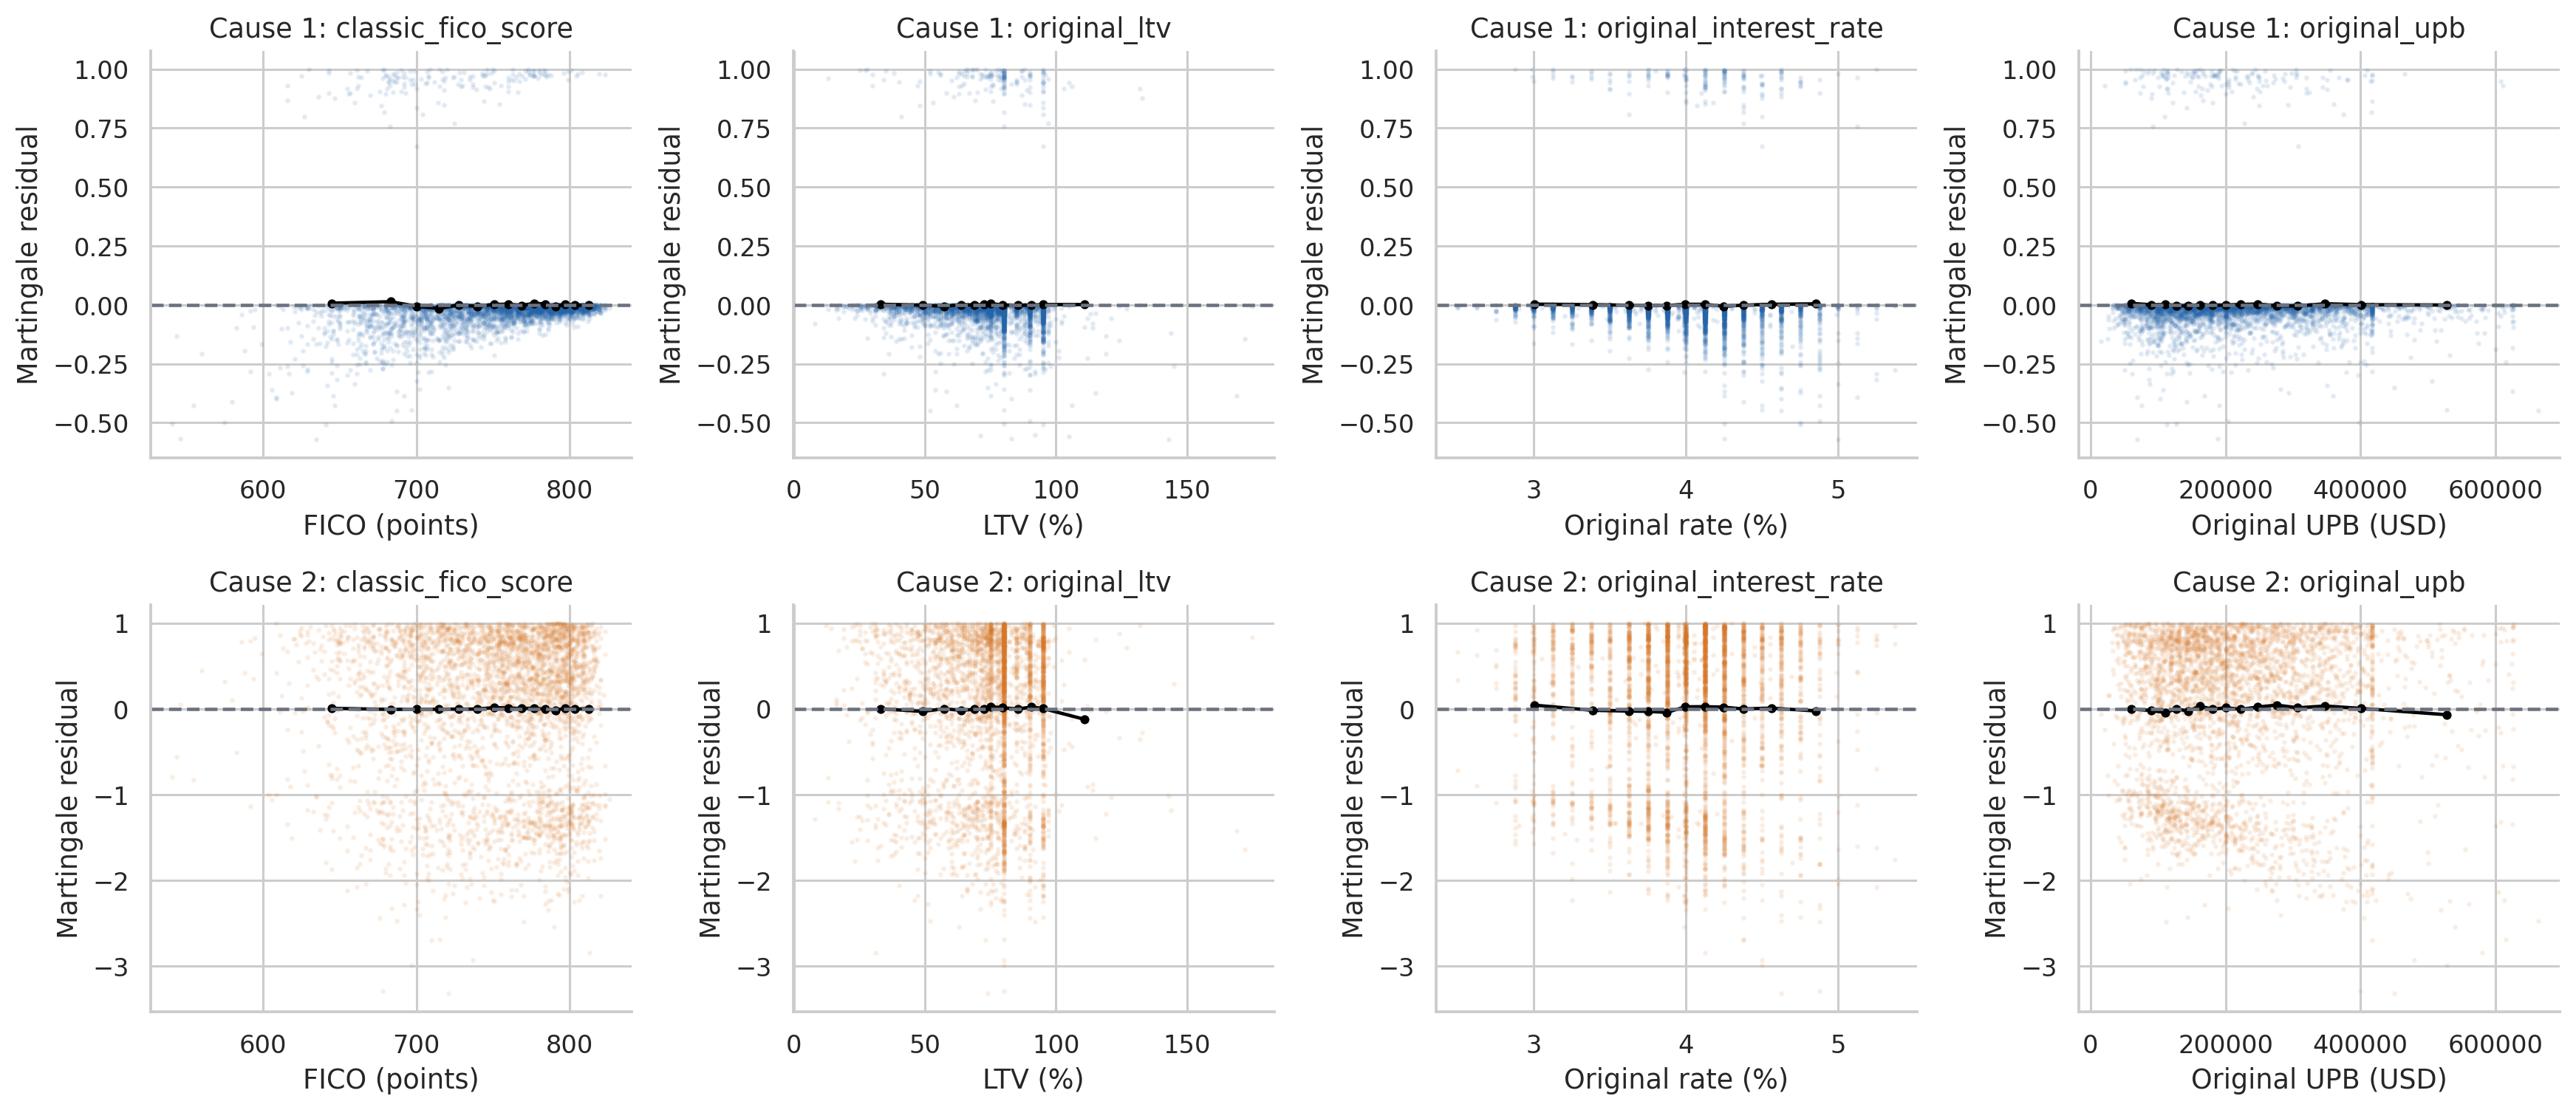

Residual plots hỗ trợ interpretation, không tự chọn thêm spline theo mỗi dao động. A/B/C và time experiments đã so trên train/internal folds; working model vẫn có non-PH limitations. Không loại loan chỉ vì residual lớn.

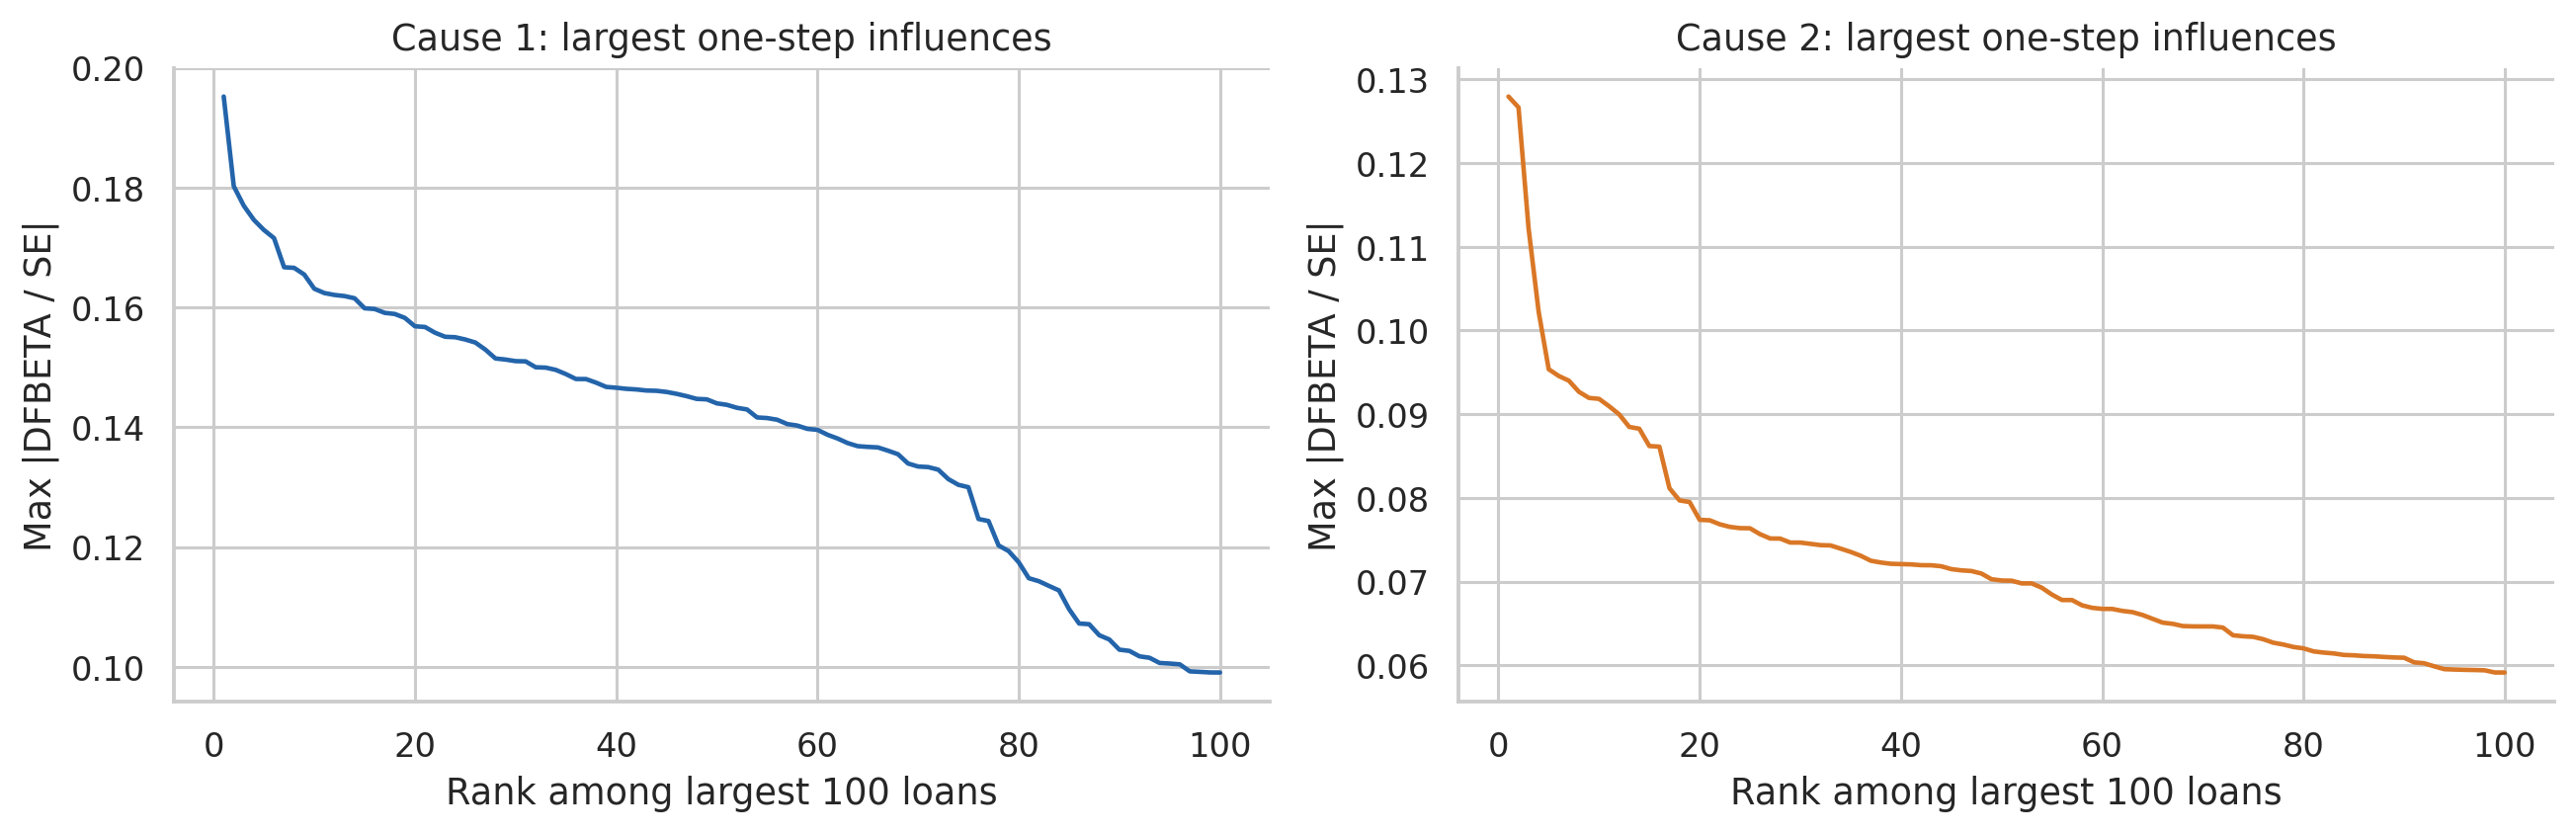

,cause,maximum,p99
0,1,0.195204,0.068402
1,2,0.127955,0.044672


Các trường hợp ảnh hưởng lớn được giữ nguyên; residual lớn không chứng minh dữ liệu sai. Chưa thực hiện leave-one-out refit toàn bộ cohort nên không diễn giải one-step DFBETA như thay đổi hệ số đo chính xác sau khi loại khoản vay.

In [13]:
fig,axes=plt.subplots(2,4,figsize=(16,7))
for row,k in enumerate([1,2]):
    for ax,c in zip(axes[row],chosen):
        tmp=pd.DataFrame({'x':train[c],'r':diag[k]['residuals'].martingale}).dropna()
        sample=tmp.sample(min(len(tmp),3500),random_state=SEED)
        ax.scatter(sample.x,sample.r,s=2,alpha=.08,color=BLUE if k==1 else ORANGE)
        tmp['bin']=pd.qcut(tmp.x,15,duplicates='drop')
        means=tmp.groupby('bin',observed=True)[['x','r']].mean()
        ax.plot(means.x,means.r,color='black',marker='o',ms=3)
        ax.axhline(0,color=GRAY,ls='--'); ax.set(title=f'Cause {k}: {c}',xlabel=labels[c],ylabel='Martingale residual')
save_figure(fig,'martingale')
say('Residual plots hỗ trợ interpretation, không tự chọn thêm spline theo mỗi dao động. A/B/C và time experiments đã so trên train/internal folds; working model vẫn có non-PH limitations. Không loại loan chỉ vì residual lớn.')
fig,axes=plt.subplots(1,2,figsize=(12,4))
influence_summary=[]
for ax,k in zip(axes,[1,2]):
    r=diag[k]['residuals']
    v=np.sort(r.max_abs_standardized_dfbeta)[::-1][:100]
    ax.plot(np.arange(1,len(v)+1),v,color=BLUE if k==1 else ORANGE)
    ax.set(title=f'Cause {k}: largest one-step influences',xlabel='Rank among largest 100 loans',ylabel='Max |DFBETA / SE|')
    influence_summary.append({'cause':k,'maximum':float(v.max()),'p99':r.max_abs_standardized_dfbeta.quantile(.99)})
save_figure(fig,'influence'); display(pd.DataFrame(influence_summary))
say('Các trường hợp ảnh hưởng lớn được giữ nguyên; residual lớn không chứng minh dữ liệu sai. Chưa thực hiện leave-one-out refit toàn bộ cohort nên không diễn giải one-step DFBETA như thay đổi hệ số đo chính xác sau khi loại khoản vay.')

## 16. Discrimination: cause-specific hazard và CIF khác nhau

Cause-specific concordance dùng event i tại t và controls j thỏa $L_j<t<T_j$, loại mọi exit cùng tháng; score ties=0.5. Khi có TV, score được tính đúng tại event t cho cả case/control. Đây là Harrell-type comparable-pair quantity phụ thuộc censoring, không phải CIF concordance.

CIF ranking được đánh giá riêng bằng IPCW cumulative/dynamic AUC: cases=Cause 1 trước/tại h; controls=không Cause 1 tại h, **bao gồm competing events** có status known-zero. Censor trước h có weight 0. Cả hai chỉ được tính sau khi model đã khóa, trên **reused internal holdout**.

In [14]:
lp=(lambda t:model_design(models[1],X_test,t)@models[1].beta) if models[1].time_effects else model_design(models[1],X_test,36)@models[1].beta
c_result,c_draws=concordance_bootstrap(test,lp,bootstrap=200)
display(pd.DataFrame([c_result]))
say(f"Reused-holdout cause-specific C-index **{c_result['c_index']:.3f}**, 95% test-bootstrap CI **{c_result['low']:.3f}–{c_result['high']:.3f}**; "
    f"{int(c_result['comparable_pairs']):,} comparable pairs. Đây không là CIF discrimination hoặc external validation.")


,c_index,comparable_pairs,low,high,bootstrap_success
0,0.765983,3650477.0,0.747822,0.785699,200


Reused-holdout cause-specific C-index **0.766**, 95% test-bootstrap CI **0.748–0.786**; 3,650,477 comparable pairs. Đây không là CIF discrimination hoặc external validation.

## 17–18. Calibration, CIF error và ranking

Primary absolute-risk validation chỉ dùng test **L=0**; landmark 12 có conditioning riêng. Horizon 12/36/60/120 chỉ được báo khi train có >=200 at risk, >=20 accumulated Cause 1 và $G(h)>0.1$. Không bỏ mốc test chỉ vì ít events hoặc metric kém.

IPCW CIF Brier là $n^{-1}\sum w_i(h)[I(T_i\le h,J_i=1)-F_{1i}(h)]^2$. Event J=1/2 trước/tại h dùng $1/G(T_i-)$; T>h dùng $1/G(h)$; censor trước/tại h weight=0. Competing events là known zero, không là loss to follow-up. Reverse KM train cùng subgroup cho G, với event trước censor khi ties. Benchmark là AJ **train**, observed incidence là AJ trên đúng test subgroup.

Mean/AJ/difference/OE mô tả calibration-in-the-large. **Joint intercept/slope** fit đồng thời trên logit(p) khác **CITL offset intercept** với slope cố định 1; bảng giữ tên rõ. Slope>1 không tự chứng minh cần shrinkage. Không recalibrate trên test rồi gọi model đã sửa.

AJ quintile CI dùng bootstrap; ở boundary fully observed dùng exact binomial interval. Boundary có censoring được flag uninformative, không trình bày CI zero-width như coverage 95%.

In [15]:
validation=validate(models,encoder,train,test,bootstrap=200)
metrics=validation['metrics'];cal=validation['calibration']
baseline_validation=validate(linear['models'],linear['encoder'],train,test,bootstrap=200)
table(metrics,'primary_validation');table(cal,'primary_calibration')
display(validation['support'])
display(metrics[['horizon','n','test_cause1','censored_before_or_at_h','effective_sample_size','max_weight']])
display(metrics[['horizon','mean_predicted','observed_AJ','joint_intercept','joint_slope','CITL_offset','cif_auc','brier','benchmark_brier']])
display(metrics[['horizon','cif_auc','cif_auc_low','cif_auc_high','CITL_offset','CITL_offset_low','CITL_offset_high']])
display(cal[['horizon','quintile','n','cause1_events_h','unknown_h','predicted','observed','observed_low','observed_high','CI_method']])
baseline_final_paired_Brier=[]
for h in metrics.horizon:
    a=baseline_validation['bootstrap'].loc[baseline_validation['bootstrap'].horizon.eq(h),'brier'].to_numpy()
    z=validation['bootstrap'].loc[validation['bootstrap'].horizon.eq(h),'brier'].to_numpy()
    point=baseline_validation['metrics'].set_index('horizon').loc[h,'brier']-metrics.set_index('horizon').loc[h,'brier']
    baseline_final_paired_Brier.append({'horizon':int(h),'baseline_minus_final_Brier':float(point),
        'low':float(np.quantile(a-z,.025)),'high':float(np.quantile(a-z,.975))})
display(pd.DataFrame(baseline_final_paired_Brier))
say(f"Primary gồm **{len(validation['sample_ids']):,}/{len(test):,}** reused-holdout loans; "
    f"{len(test)-len(validation['sample_ids']):,} late entrants nằm ngoài estimand này. "
    "Baseline/final Brier comparison dùng cùng revised outcomes, cùng IDs và cùng bootstrap draws; đây là descriptive comparison sau khi selection đã khóa.")


,horizon,landmark,train_n,test_n,train_at_risk,train_cause1,G,supported
0,12,0,35460,11784,33449,51,1.000000,True
1,36,0,35460,11784,26656,310,1.000000,True
2,60,0,35460,11784,19153,931,1.000000,True
3,120,0,35460,11784,7974,1438,0.998167,True


,horizon,n,test_cause1,censored_before_or_at_h,effective_sample_size,max_weight
0,12,11784,14,0,11784.000000,1.000000
1,36,11784,110,0,11784.000000,1.000000
2,60,11784,324,0,11784.000000,1.000000
3,120,11784,478,5,11778.993065,1.001836


,horizon,mean_predicted,observed_AJ,joint_intercept,joint_slope,CITL_offset,cif_auc,brier,benchmark_brier
0,12,0.001401,0.001188,1.197011,1.221563,-0.165198,0.766525,0.001185,0.001187
1,36,0.008684,0.009335,1.812781,1.405641,0.073529,0.800625,0.009123,0.009248
2,60,0.026169,0.027495,0.873845,1.253374,0.051888,0.771926,0.025962,0.026740
3,120,0.040182,0.040564,0.360164,1.122730,0.010093,0.745272,0.037562,0.038919


,horizon,cif_auc,cif_auc_low,cif_auc_high,CITL_offset,CITL_offset_low,CITL_offset_high
0,12,0.766525,0.617238,0.855361,-0.165198,-0.870572,0.288739
1,36,0.800625,0.762441,0.835807,0.073529,-0.099648,0.240574
2,60,0.771926,0.747296,0.793349,0.051888,-0.054290,0.154264
3,120,0.745272,0.726790,0.765665,0.010093,-0.091962,0.102299


,horizon,quintile,n,cause1_events_h,unknown_h,predicted,observed,observed_low,observed_high,CI_method
0,12,1,2357,1,0,0.000278,0.000424,0.000000,0.001322,test-loan percentile AJ bootstrap
1,12,2,2357,0,0,0.000588,0.000000,0.000000,0.001564,exact binomial boundary; all horizon outcomes ...
2,12,3,2356,2,0,0.000991,0.000849,0.000000,0.002512,test-loan percentile AJ bootstrap
3,12,4,2357,4,0,0.001649,0.001697,0.000418,0.003779,test-loan percentile AJ bootstrap
4,12,5,2357,7,0,0.003498,0.002970,0.001216,0.004722,test-loan percentile AJ bootstrap
5,36,1,2357,3,0,0.001789,0.001273,0.000403,0.002625,test-loan percentile AJ bootstrap
6,36,2,2357,2,0,0.003736,0.000849,0.000000,0.002183,test-loan percentile AJ bootstrap
7,36,3,2356,13,0,0.006238,0.005518,0.002944,0.008979,test-loan percentile AJ bootstrap
8,36,4,2357,22,0,0.010302,0.009334,0.005936,0.013601,test-loan percentile AJ bootstrap
9,36,5,2357,70,0,0.021351,0.029699,0.023074,0.036483,test-loan percentile AJ bootstrap


,horizon,baseline_minus_final_Brier,low,high
0,12,1.123349e-07,-2.908136e-07,5.043122e-07
1,36,3.544309e-07,-9.988367e-06,7.866417e-06
2,60,3.144205e-05,-4.734665e-06,6.693257e-05
3,120,3.047351e-05,-2.441055e-05,8.743635e-05


Primary gồm **11,784/12,495** reused-holdout loans; 711 late entrants nằm ngoài estimand này. Baseline/final Brier comparison dùng cùng revised outcomes, cùng IDs và cùng bootstrap draws; đây là descriptive comparison sau khi selection đã khóa.

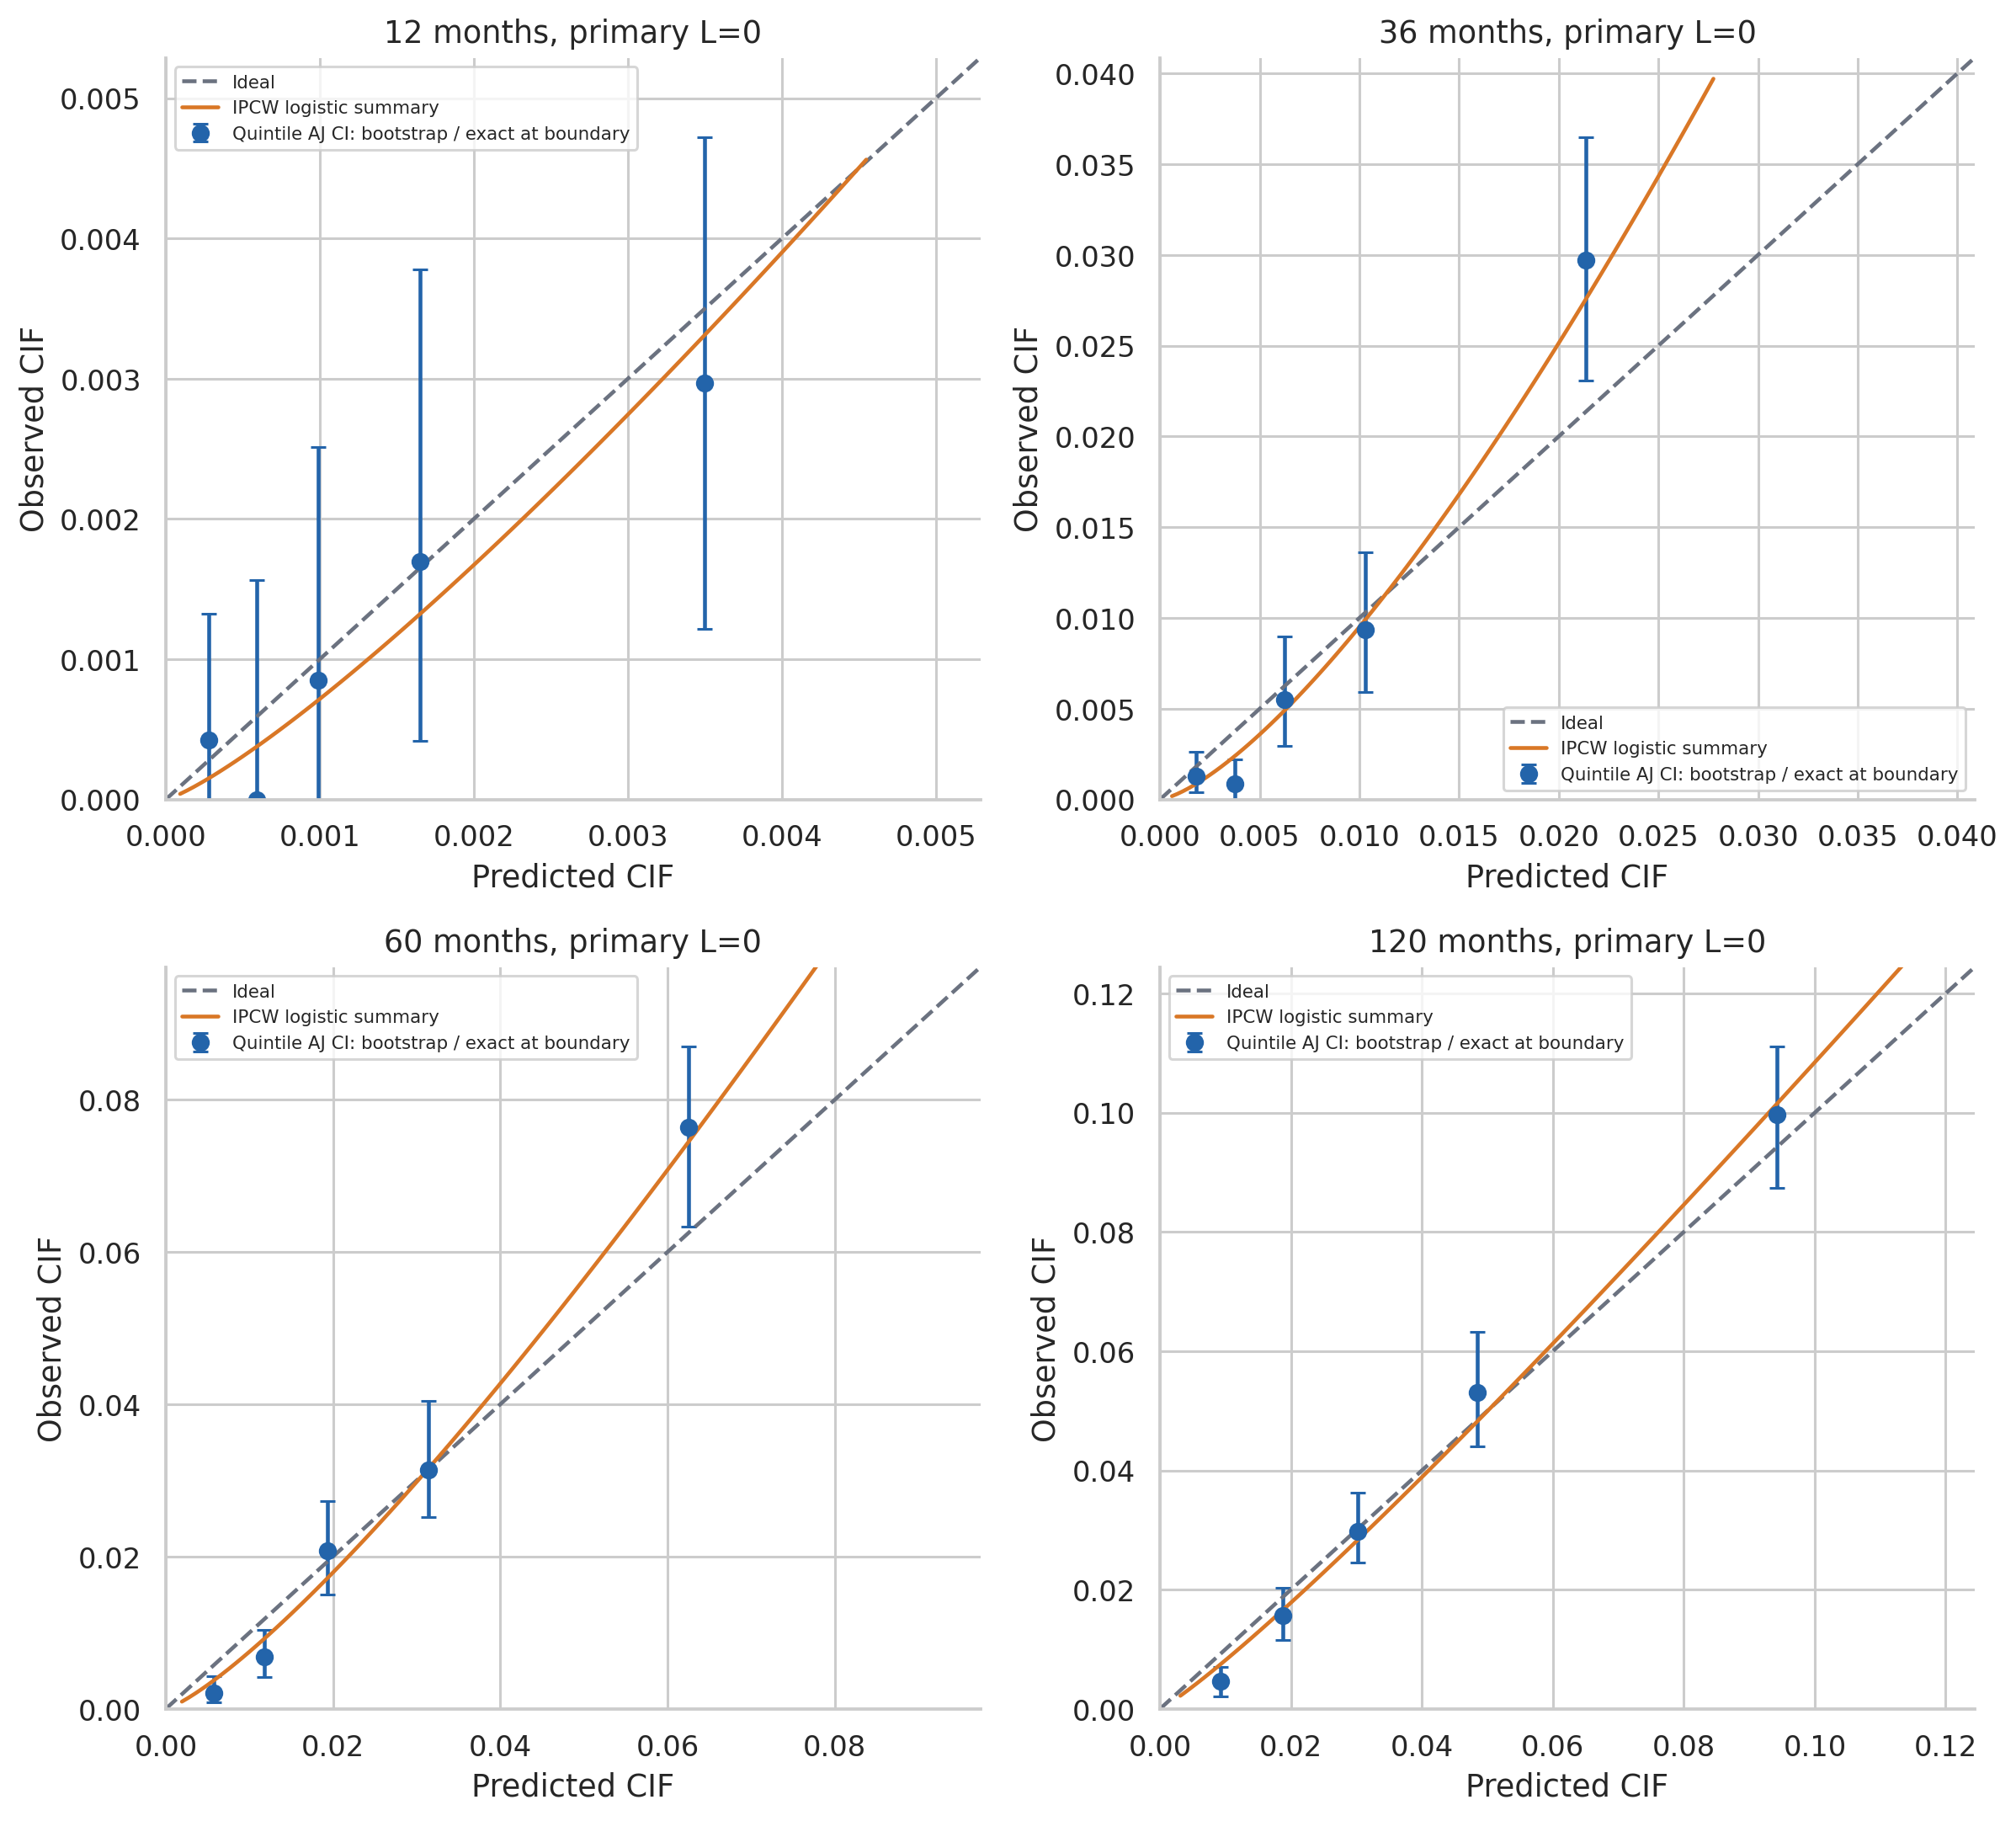

Quintile CI dùng bootstrap; fully observed boundary dùng exact binomial interval. Boundary có censoring được flag thay vì CI zero-width. Logistic curve dùng joint intercept/slope, không phải offset CITL.

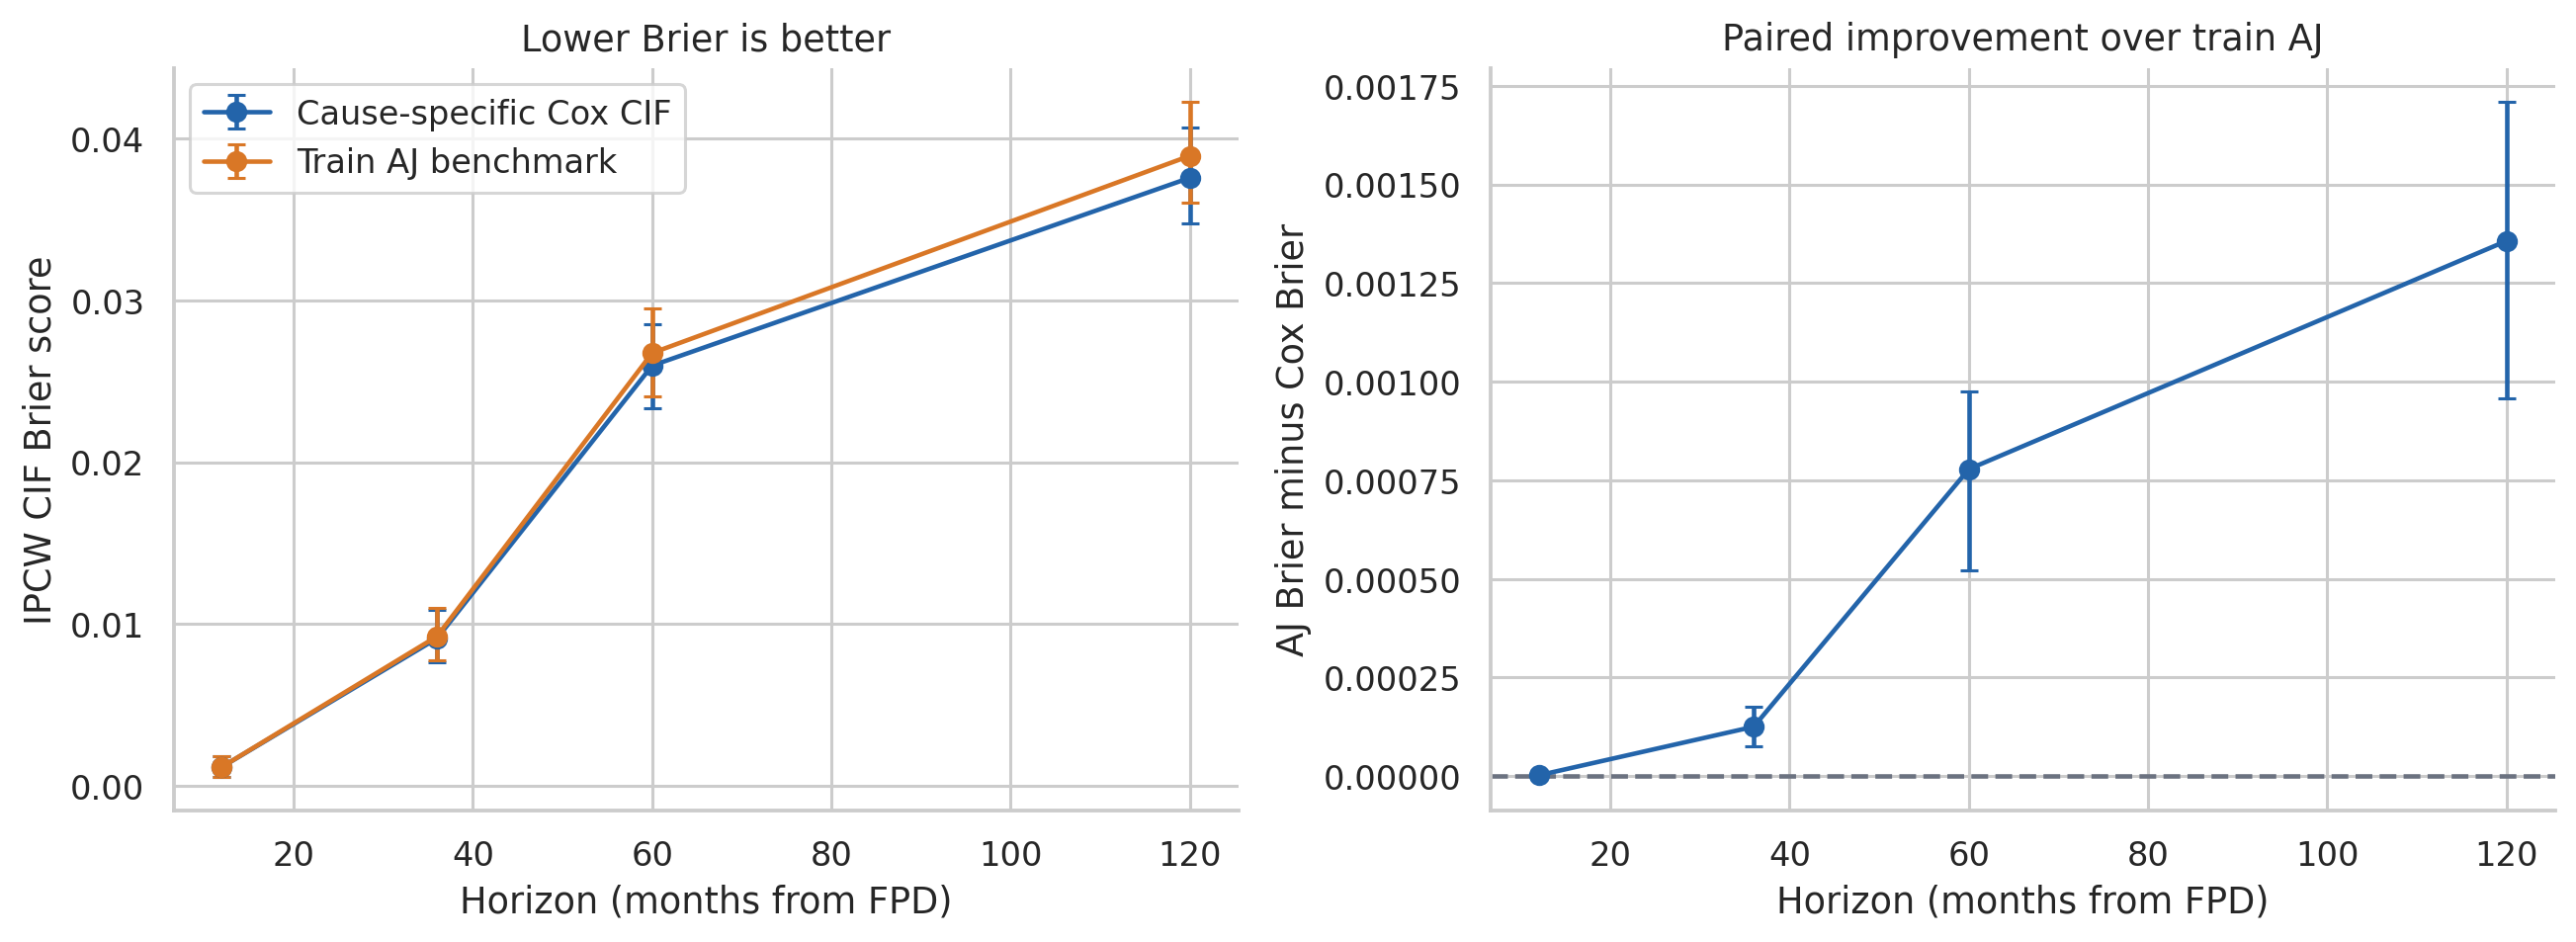

Brier nhỏ một phần vì 90+ tương đối hiếm; phải đọc cạnh benchmark. Cải thiện là chênh lệch paired trên cùng test/horizon/trọng số. Các CI không bao gồm bất định model train hay ước lượng G. Không gọi tích phân nối bốn điểm này là Integrated Brier Score.

In [16]:
fig,axes=plt.subplots(2,2,figsize=(11,10))
for ax,(_,m) in zip(axes.flat,metrics.iterrows()):
    d=cal.loc[cal.horizon.eq(m.horizon)]
    ax.errorbar(d.predicted,d.observed,yerr=np.vstack([np.maximum(0,d.observed-d.observed_low),np.maximum(0,d.observed_high-d.observed)]),fmt='o',capsize=3,color=BLUE,label='Quintile AJ CI: bootstrap / exact at boundary')
    limit=max(d.predicted.max(),d.observed_high.max())*1.12
    ax.plot([0,limit],[0,limit],color=GRAY,ls='--',label='Ideal')
    ps=np.linspace(max(.00005,d.predicted.min()/3),max(d.predicted.max()*1.3,.001),100)
    from scipy.special import expit, logit
    ax.plot(ps,expit(m.intercept+m.slope*logit(ps)),color=ORANGE,label='IPCW logistic summary')
    ax.set(xlabel='Predicted CIF',ylabel='Observed CIF',title=f'{int(m.horizon)} months, primary L=0',xlim=(0,limit),ylim=(0,limit)); ax.legend(fontsize=7)
save_figure(fig,'calibration')
say('Quintile CI dùng bootstrap; fully observed boundary dùng exact binomial interval. Boundary có censoring được flag thay vì CI zero-width. Logistic curve dùng joint intercept/slope, không phải offset CITL.')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for c,color,label in [('brier',BLUE,'Cause-specific Cox CIF'),('benchmark_brier',ORANGE,'Train AJ benchmark')]:
    axes[0].errorbar(metrics.horizon,metrics[c],yerr=np.vstack([metrics[c]-metrics[c+'_low'],metrics[c+'_high']-metrics[c]]),marker='o',capsize=3,color=color,label=label)
axes[1].errorbar(metrics.horizon,metrics.brier_improvement,yerr=np.vstack([np.maximum(0,metrics.brier_improvement-metrics.brier_improvement_low),np.maximum(0,metrics.brier_improvement_high-metrics.brier_improvement)]),marker='o',capsize=3,color=BLUE)
axes[0].set(xlabel='Horizon (months from FPD)',ylabel='IPCW CIF Brier score',title='Lower Brier is better'); axes[0].legend()
axes[1].axhline(0,color=GRAY,ls='--'); axes[1].set(xlabel='Horizon (months from FPD)',ylabel='AJ Brier minus Cox Brier',title='Paired improvement over train AJ')
save_figure(fig,'brier')
say('Brier nhỏ một phần vì 90+ tương đối hiếm; phải đọc cạnh benchmark. Cải thiện là chênh lệch paired trên cùng test/horizon/trọng số. Các CI không bao gồm bất định model train hay ước lượng G. Không gọi tích phân nối bốn điểm này là Integrated Brier Score.')

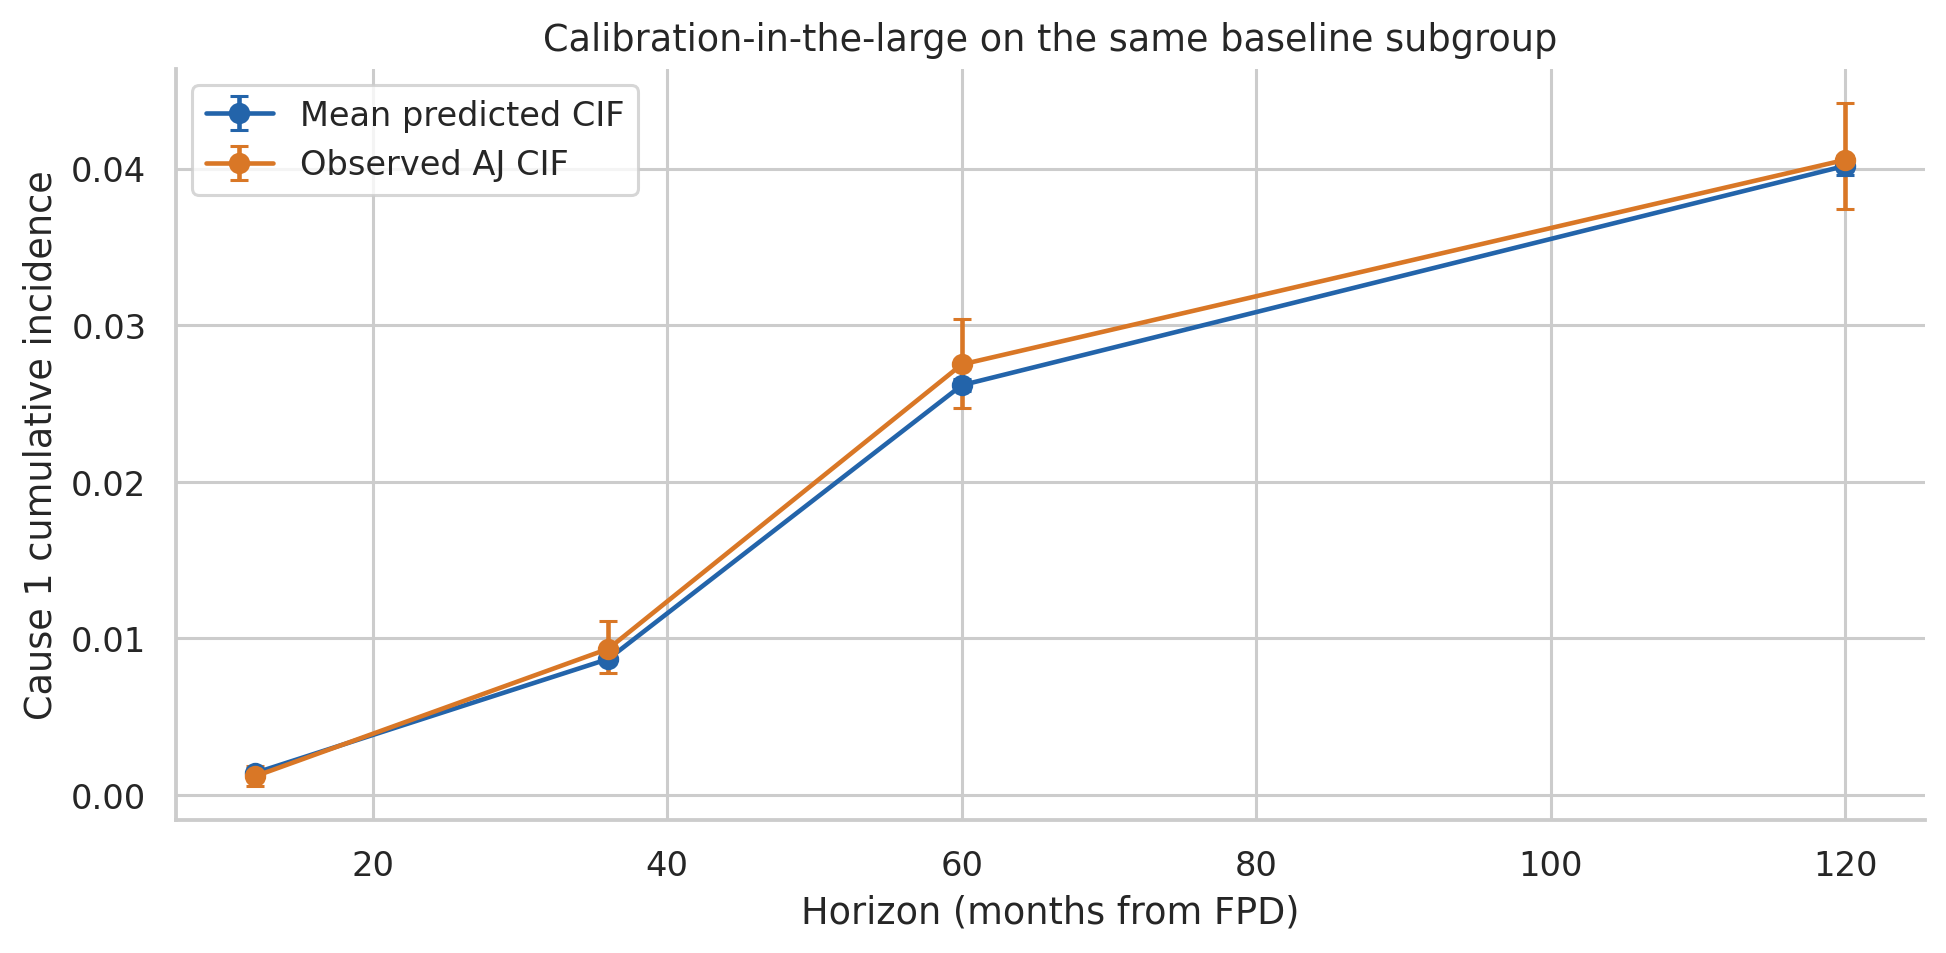

Mean prediction và observed AJ gần nhau chưa đủ chứng minh calibration từng người. Dấu của difference = predicted − observed cho biết over-prediction (>0) hoặc under-prediction (<0); O/E bổ sung diễn giải tương đối, nhạy khi risk rất nhỏ.

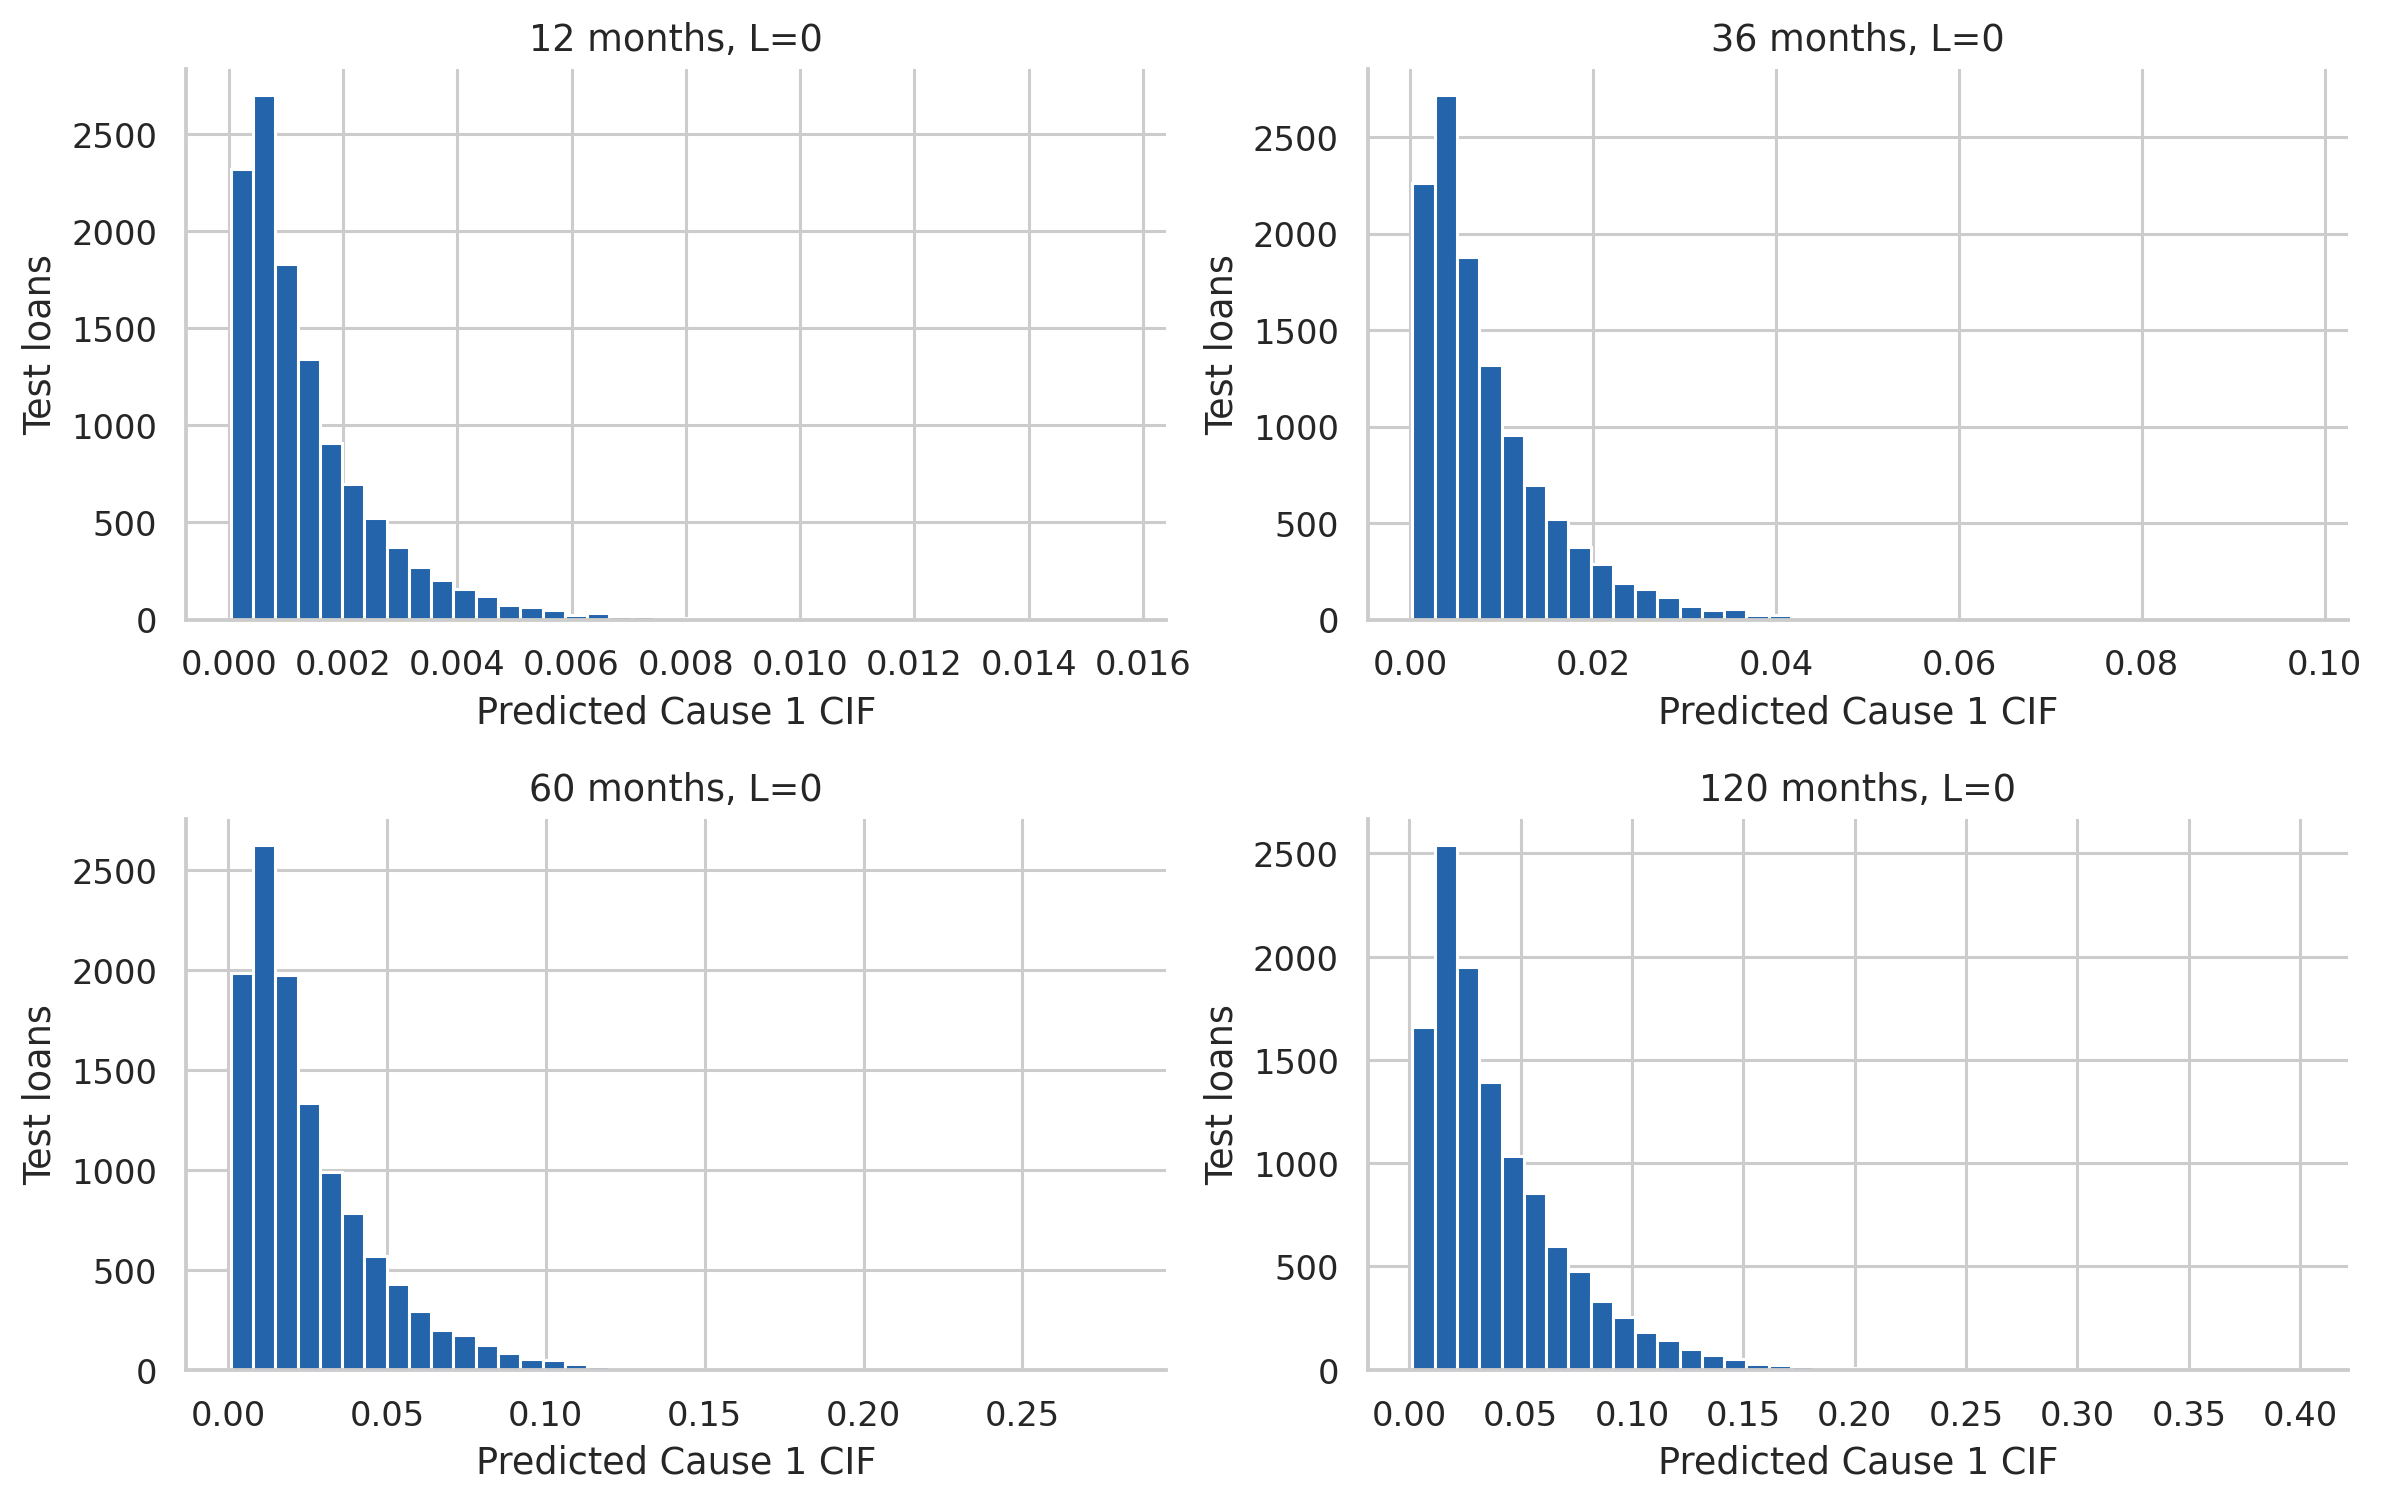

Phân phối CIF thường lệch phải: phần lớn khoản có risk thấp và một nhóm có risk cao hơn. Phân phối này là đầu ra mô hình, không chứng minh mọi điểm ở đuôi được hiệu chỉnh tốt; xem quintile và CI để đánh giá hỗ trợ dữ liệu.

In [17]:
fig,ax=plt.subplots(figsize=(9,4.5))
for c,color,label in [('mean_predicted',BLUE,'Mean predicted CIF'),('observed_AJ',ORANGE,'Observed AJ CIF')]:
    ax.errorbar(metrics.horizon,metrics[c],yerr=np.vstack([metrics[c]-metrics[c+'_low'],metrics[c+'_high']-metrics[c]]),marker='o',capsize=3,color=color,label=label)
ax.set(xlabel='Horizon (months from FPD)',ylabel='Cause 1 cumulative incidence',title='Calibration-in-the-large on the same baseline subgroup'); ax.legend()
save_figure(fig,'calibration_in_large')
say('Mean prediction và observed AJ gần nhau chưa đủ chứng minh calibration từng người. Dấu của difference = predicted − observed cho biết over-prediction (>0) hoặc under-prediction (<0); O/E bổ sung diễn giải tương đối, nhạy khi risk rất nhỏ.')
fig,axes=plt.subplots(2,2,figsize=(11,7))
for j,(ax,h) in enumerate(zip(axes.flat,metrics.horizon)):
    ax.hist(validation['predictions'][:,j],bins=40,color=BLUE)
    ax.set(xlabel='Predicted Cause 1 CIF',ylabel='Test loans',title=f'{int(h)} months, L=0')
save_figure(fig,'predicted_cif_distribution')
say('Phân phối CIF thường lệch phải: phần lớn khoản có risk thấp và một nhóm có risk cao hơn. Phân phối này là đầu ra mô hình, không chứng minh mọi điểm ở đuôi được hiệu chỉnh tốt; xem quintile và CI để đánh giá hỗ trợ dữ liệu.')

## 19. Uncertainty của fixed-model reused-holdout evaluation

Bootstrap 200 lần ở cấp test loan, seed 20261115; models/encoder/train G/train AJ giữ cố định. Resample test để tính AJ, prediction means, Brier/benchmark/paired differences, joint calibration, offset CITL và CIF AUC. Cut points quintile cố định, AJ tính lại trong resample.

CI này không gồm training/preprocessing/knots/specification-selection uncertainty. P3/P4 3-fold SE chỉ là parsimony heuristic trên train, không formal CI. Zero-event percentile bootstrap không thể sinh event mới; tăng số replicates không sửa boundary degeneracy. Method/count/unknown status được báo cho từng nhóm.

Không gọi bốn điểm Brier nối nhau là IBS. Không coi interval chứa/không chứa một giá trị là thay thế cho interpretation, calibration-by-risk hoặc missing-history assumptions.

,horizon,bootstrap_success,calibration_bootstrap_success,slope,slope_low,slope_high,brier_improvement,brier_improvement_low,brier_improvement_high
0,12,200,200,1.221563,0.514137,1.976101,0.000002,-0.000001,0.000005
1,36,200,200,1.405641,1.162999,1.628624,0.000125,0.000076,0.000177
2,60,200,200,1.253374,1.101947,1.388677,0.000778,0.000523,0.000975
3,120,200,200,1.122730,1.014017,1.235184,0.001357,0.000958,0.001710


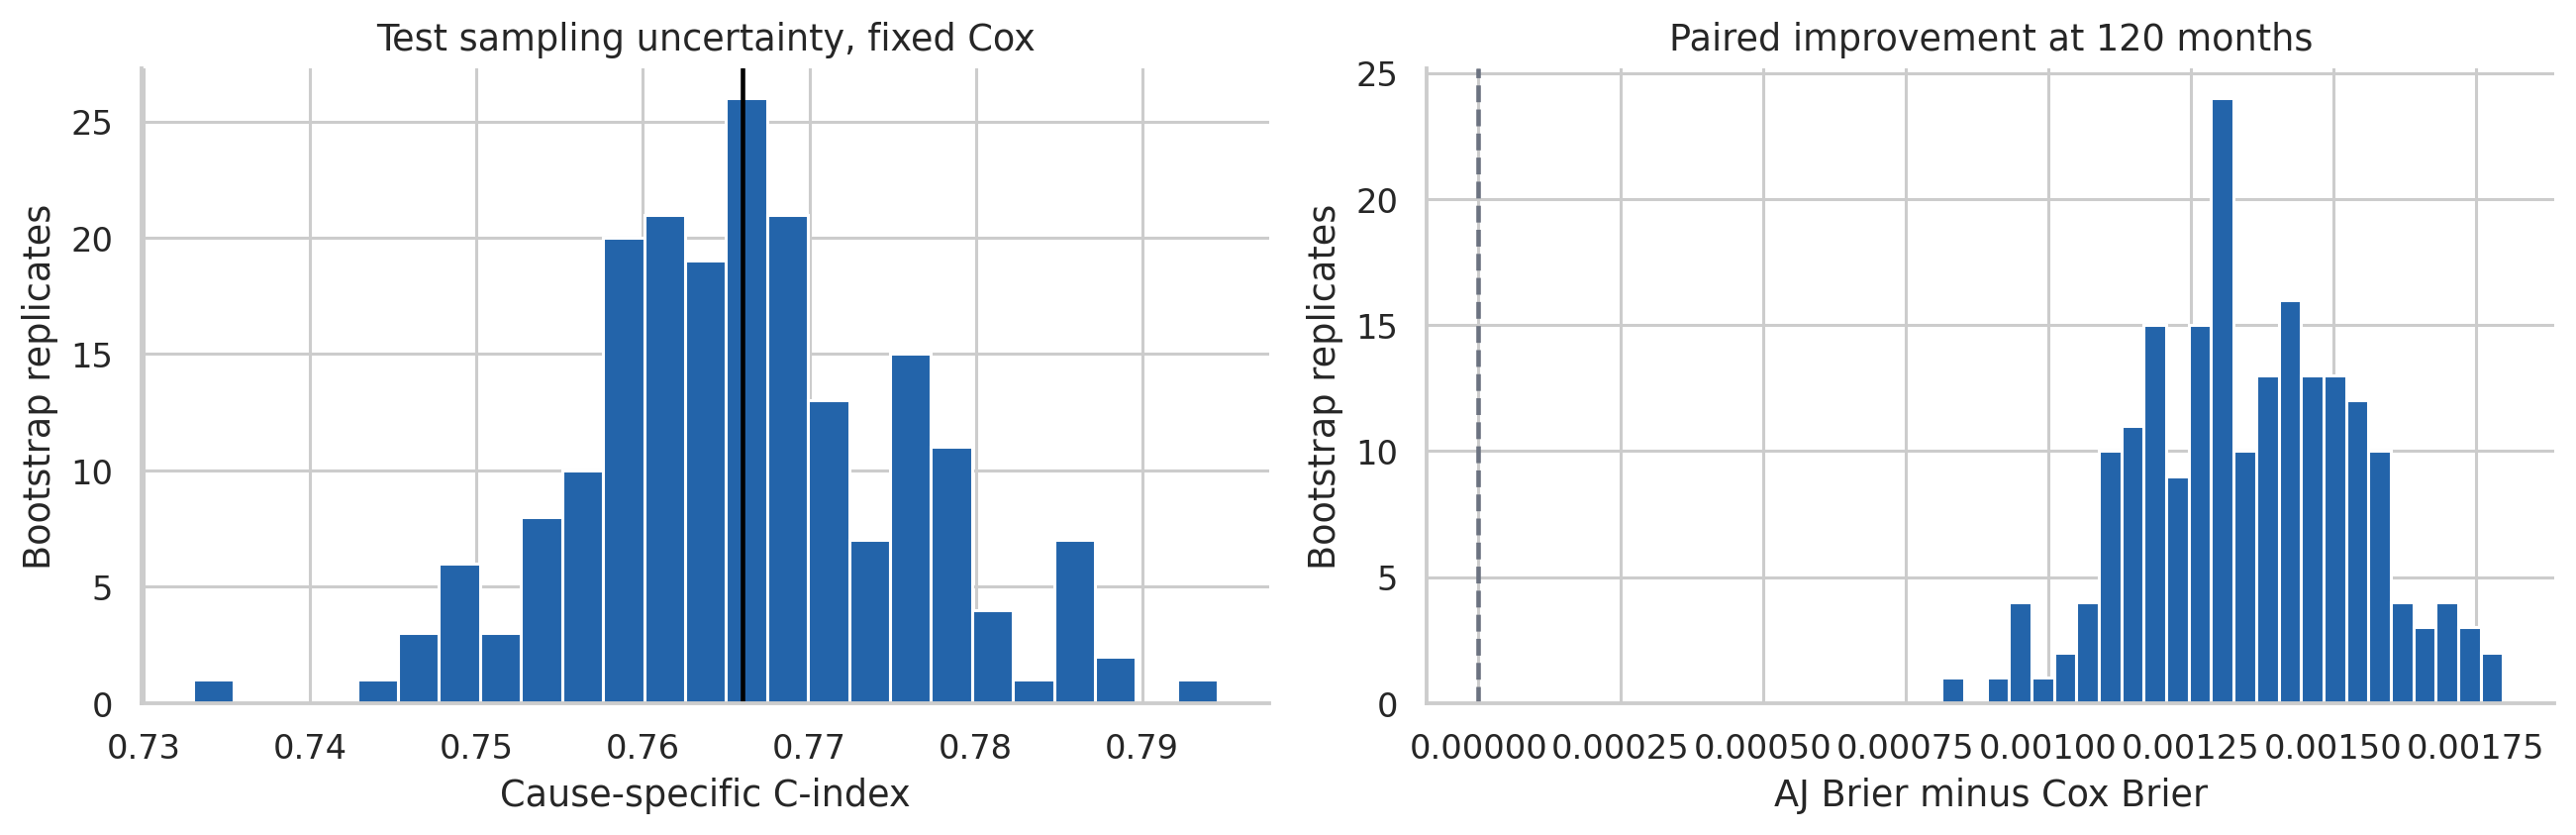

Số bootstrap thành công được báo ở bảng, gồm riêng calibration fits. Các phân phối trên chỉ dùng kết quả thực sự được tính; không mô phỏng dữ liệu để tạo hình kết quả. CI sampling không xử lý được bias do left truncation, thiếu lịch sử hoặc PH misspecification.

,horizon,cif_auc,cif_auc_low,cif_auc_high,CITL_offset,CITL_offset_low,CITL_offset_high,offset_bootstrap_success
0,12,0.766525,0.617238,0.855361,-0.165198,-0.870572,0.288739,200
1,36,0.800625,0.762441,0.835807,0.073529,-0.099648,0.240574,200
2,60,0.771926,0.747296,0.793349,0.051888,-0.054290,0.154264,200
3,120,0.745272,0.726790,0.765665,0.010093,-0.091962,0.102299,200


In [18]:
display(metrics[['horizon','bootstrap_success','calibration_bootstrap_success','slope','slope_low','slope_high','brier_improvement','brier_improvement_low','brier_improvement_high']].round(6))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(c_draws,bins=25,color=BLUE); axes[0].axvline(c_result['c_index'],color='black'); axes[0].set(xlabel='Cause-specific C-index',ylabel='Bootstrap replicates',title='Test sampling uncertainty, fixed Cox')
b=validation['bootstrap']; last_h=int(metrics.horizon.max())
axes[1].hist(b.loc[b.horizon.eq(last_h),'brier_improvement'],bins=25,color=BLUE); axes[1].axvline(0,color=GRAY,ls='--')
axes[1].set(xlabel='AJ Brier minus Cox Brier',ylabel='Bootstrap replicates',title=f'Paired improvement at {last_h} months')
save_figure(fig,'bootstrap_uncertainty')
say('Số bootstrap thành công được báo ở bảng, gồm riêng calibration fits. Các phân phối trên chỉ dùng kết quả thực sự được tính; không mô phỏng dữ liệu để tạo hình kết quả. CI sampling không xử lý được bias do left truncation, thiếu lịch sử hoặc PH misspecification.')
display(metrics[['horizon','cif_auc','cif_auc_low','cif_auc_high','CITL_offset','CITL_offset_low','CITL_offset_high','offset_bootstrap_success']])

## 20. Landmark và sensitivity sau khi khóa model

Landmark 12 chọn L<=12<T, reset về L'=0,T'=T−12. Các horizons 36/60/120 là **tuổi từ FPD**, không số tháng cộng thêm sau landmark. Train/test cùng conditioning, gồm late entrants đủ điều kiện.

Sensitivity có mục tiêu: đảo same-month priority; ZB reporting/effective clock; bỏ RA khỏi competing exit để lượng hóa quy tắc cũ; baseline tuyến tính trên cùng revised outcomes; direct product-integral; administrative support tại 120. Các scenarios thay event labels/population không là model contest cho cùng outcome. Không chọn estimator/specification theo test Brier.

Common administrative support dùng potential censor age **>120**, strict vì censor tại h bị coi unknown theo IPCW convention đã khai báo. Đây là population khác, không cùng metric target với full primary subgroup.

,horizon,landmark,n,test_cause1,mean_predicted,observed_AJ,brier,benchmark_brier,slope
0,36,12,11292,100,0.007774,0.008856,0.008674,0.008779,1.373178
1,60,12,11292,317,0.026462,0.028073,0.026489,0.027288,1.245765
2,120,12,11292,473,0.041462,0.041890,0.038719,0.040134,1.114569


Landmark 12 đánh giá 11,292 test loans, trong đó **317** late entrants. Đây là estimand conditional khác primary; không so trực tiếp mức Brier như cùng một quần thể.

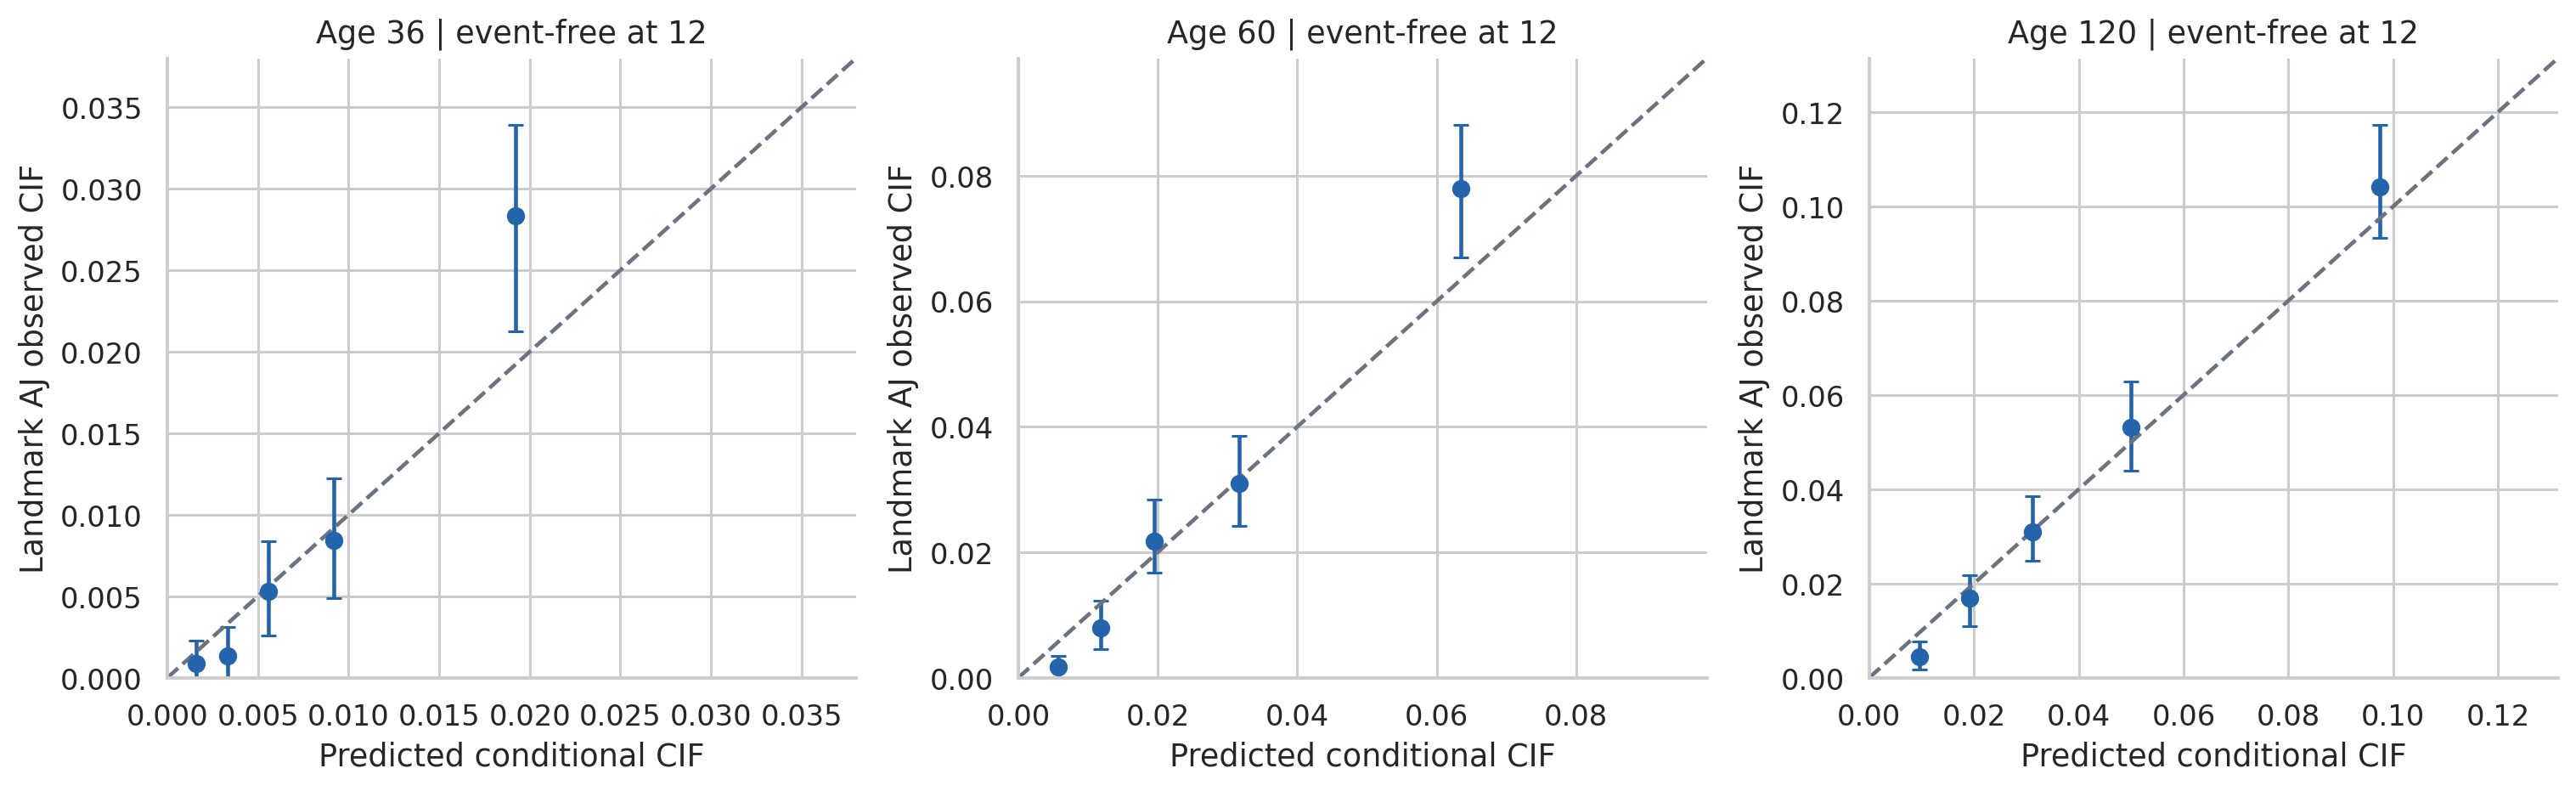

Calibration landmark giúp kiểm tra một quần thể quan sát khác mà vẫn thống nhất mốc dự báo và incidence. Nó không giải quyết giả định entry độc lập hoặc đánh giá người chỉ được acquisition sau tuổi 12.

In [19]:
landmark=validate(models,encoder,train,test,start=12,bootstrap=200)
table(landmark['metrics'],'landmark12_validation')
display(landmark['metrics'][['horizon','landmark','n','test_cause1','mean_predicted','observed_AJ','brier','benchmark_brier','slope']].round(6))
late_count=int((test.L.gt(0)&test.L.le(12)&test['T'].gt(12)).sum())
say(f'Landmark 12 đánh giá {len(landmark["sample_ids"]):,} test loans, trong đó **{late_count:,}** late entrants. Đây là estimand conditional khác primary; không so trực tiếp mức Brier như cùng một quần thể.')
fig,axes=plt.subplots(1,3,figsize=(14,4.4))
for ax,h in zip(axes,landmark['metrics'].horizon):
    d=landmark['calibration'].query('horizon==@h')
    ax.errorbar(d.predicted,d.observed,yerr=np.vstack([np.maximum(0,d.observed-d.observed_low),np.maximum(0,d.observed_high-d.observed)]),fmt='o',capsize=3,color=BLUE)
    limit=max(d.predicted.max(),d.observed_high.max())*1.12
    ax.plot([0,limit],[0,limit],ls='--',color=GRAY); ax.set(title=f'Age {int(h)} | event-free at 12',xlabel='Predicted conditional CIF',ylabel='Landmark AJ observed CIF',xlim=(0,limit),ylim=(0,limit))
save_figure(fig,'landmark_calibration')
say('Calibration landmark giúp kiểm tra một quần thể quan sát khác mà vẫn thống nhất mốc dự báo và incidence. Nó không giải quyết giả định entry độc lập hoặc đánh giá người chỉ được acquisition sau tuổi 12.')

In [20]:
sensitivity_rows=[baseline_validation['metrics'].assign(scenario='baseline_linear',c_index=np.nan)]
sensitivity_models={};sensitivity_coeff=[];sensitivity_changes=[]
scenarios=[('same_month_cause1',{'priority':1}),('zb_reporting_clock',{'zb_clock':'report'}),('RA_ZB_only',{})]
for name,kwargs in scenarios:
    histories_used=histories.copy() if name=='RA_ZB_only' else histories
    if name=='RA_ZB_only':histories_used['first_ra_month']=np.nan
    alternative,alt_flow,alt_exclusions=build_cohort(orig,histories_used,**kwargs)
    assert set(alternative.index)==set(cohort.index)
    atr,ate=alternative.loc[train.index],alternative.loc[test.index]
    alt_models={}
    for k in [1,2]:
        static=fit_cause(atr,encoder.transform(atr)[models[k].static_columns],k)
        alt_models[k]=fit_time_varying(atr,encoder.transform(atr)[models[k].static_columns],k,models[k].time_effects,static) if models[k].time_effects else static
    sensitivity_models[name]=(encoder,alt_models)
    value=validate(alt_models,encoder,atr,ate,bootstrap=0)
    alt_x=encoder.transform(ate)
    score=(lambda t:model_design(alt_models[1],alt_x,t)@alt_models[1].beta) if alt_models[1].time_effects else model_design(alt_models[1],alt_x,36)@alt_models[1].beta
    cc=concordance(ate,score)
    sensitivity_rows.append(value['metrics'].assign(scenario=name,c_index=cc['c_index']))
    sensitivity_coeff.extend([m.coefficient_table().assign(scenario=name) for m in alt_models.values()])
    sensitivity_changes.append({'scenario':name,'cohort_n':len(alternative),'cause1':int(alternative.J.eq(1).sum()),'cause2':int(alternative.J.eq(2).sum()),
      'changed_outcome':int(alternative.J.ne(cohort.J).sum()),'changed_exit':int(alternative['T'].ne(cohort['T']).sum())})
direct_validation=validate(models,encoder,train,test,bootstrap=0,integration='direct')
assert direct_validation['sample_ids']==validation['sample_ids']
sensitivity_rows.append(direct_validation['metrics'].assign(scenario='direct_PI',c_index=c_result['c_index']))
cif_integration_sensitivity=[]
for j,h in enumerate(metrics.horizon):
    delta=direct_validation['predictions'][:,j]-validation['predictions'][:,j]
    cif_integration_sensitivity.append({'horizon':int(h),'mean_CIF1_exponential':float(validation['predictions'][:,j].mean()),
        'mean_CIF1_direct':float(direct_validation['predictions'][:,j].mean()),'max_abs_individual_CIF1_delta':float(np.abs(delta).max()),
        'Brier_direct':float(direct_validation['metrics'].set_index('horizon').loc[h,'brier'])})
cutoffs=cohort.loc[cohort.J.eq(0),'last_month'].unique();assert len(cutoffs)==1
cutoff=int(cutoffs[0])
common=validate(models,encoder,train.loc[cutoff-train.first_payment_date_month+1>120],
                test.loc[cutoff-test.first_payment_date_month+1>120],horizons=[120],bootstrap=0)
assert int(common['metrics'].censored_before_or_at_h.iloc[0])==0
sensitivity_rows.append(common['metrics'].assign(scenario='common_admin_support_120',c_index=np.nan))
sensitivity=pd.concat([metrics.assign(scenario='primary',c_index=c_result['c_index']),*sensitivity_rows],ignore_index=True)
sensitivity_coeff=pd.concat(sensitivity_coeff,ignore_index=True)
table(sensitivity[['scenario','horizon','n','test_cause1','mean_predicted','observed_AJ','brier','benchmark_brier','CITL_offset','slope','cif_auc','c_index']],'sensitivity_metrics')
table(sensitivity_coeff,'sensitivity_coefficients');table(pd.DataFrame(sensitivity_changes),'sensitivity_cohort_changes')
display(pd.DataFrame(sensitivity_changes));display(sensitivity[['scenario','horizon','n','mean_predicted','observed_AJ','brier','slope','cif_auc']])
display(pd.DataFrame(cif_integration_sensitivity))
individual=individual_predictions(models,encoder,cohort,train.index)
table(individual,'individual_predictions')
say(f"Đã xuất **{len(individual):,}** dòng cho **{individual.loan_identifier.nunique():,}** loans L=0 ở bốn horizons, gồm F1/F2/S, rank và sample_role. "
    "Không gán FPD-origin ranking cho 2.736 late entrants. Ranking model-implied không là khuyến nghị tín dụng.")


,scenario,cohort_n,cause1,cause2,changed_outcome,changed_exit
0,same_month_cause1,49980,2049,37275,30,0
1,zb_reporting_clock,49980,2019,37305,0,32
2,RA_ZB_only,49980,2019,37305,0,1


,scenario,horizon,n,mean_predicted,observed_AJ,brier,slope,cif_auc
0,primary,12,11784,0.001401,0.001188,0.001185,1.221563,0.766525
1,primary,36,11784,0.008684,0.009335,0.009123,1.405641,0.800625
2,primary,60,11784,0.026169,0.027495,0.025962,1.253374,0.771926
3,primary,120,11784,0.040182,0.040564,0.037562,1.122730,0.745272
4,baseline_linear,12,11784,0.001398,0.001188,0.001185,1.176626,0.759971
5,baseline_linear,36,11784,0.008657,0.009335,0.009123,1.390534,0.802441
6,baseline_linear,60,11784,0.026022,0.027495,0.025994,1.254937,0.772208
7,baseline_linear,120,11784,0.039897,0.040564,0.037592,1.149319,0.745929
8,same_month_cause1,12,11784,0.001401,0.001188,0.001185,1.211527,0.766015
9,same_month_cause1,36,11784,0.009208,0.009674,0.009451,1.368866,0.795858


,horizon,mean_CIF1_exponential,mean_CIF1_direct,max_abs_individual_CIF1_delta,Brier_direct
0,12,0.001401,0.001406,0.000117,0.001185
1,36,0.008684,0.008720,0.000537,0.009122
2,60,0.026169,0.026363,0.003554,0.025960
3,120,0.040182,0.040448,0.003707,0.037560


Đã xuất **188,976** dòng cho **47,244** loans L=0 ở bốn horizons, gồm F1/F2/S, rank và sample_role. Không gán FPD-origin ranking cho 2.736 late entrants. Ranking model-implied không là khuyến nghị tín dụng.

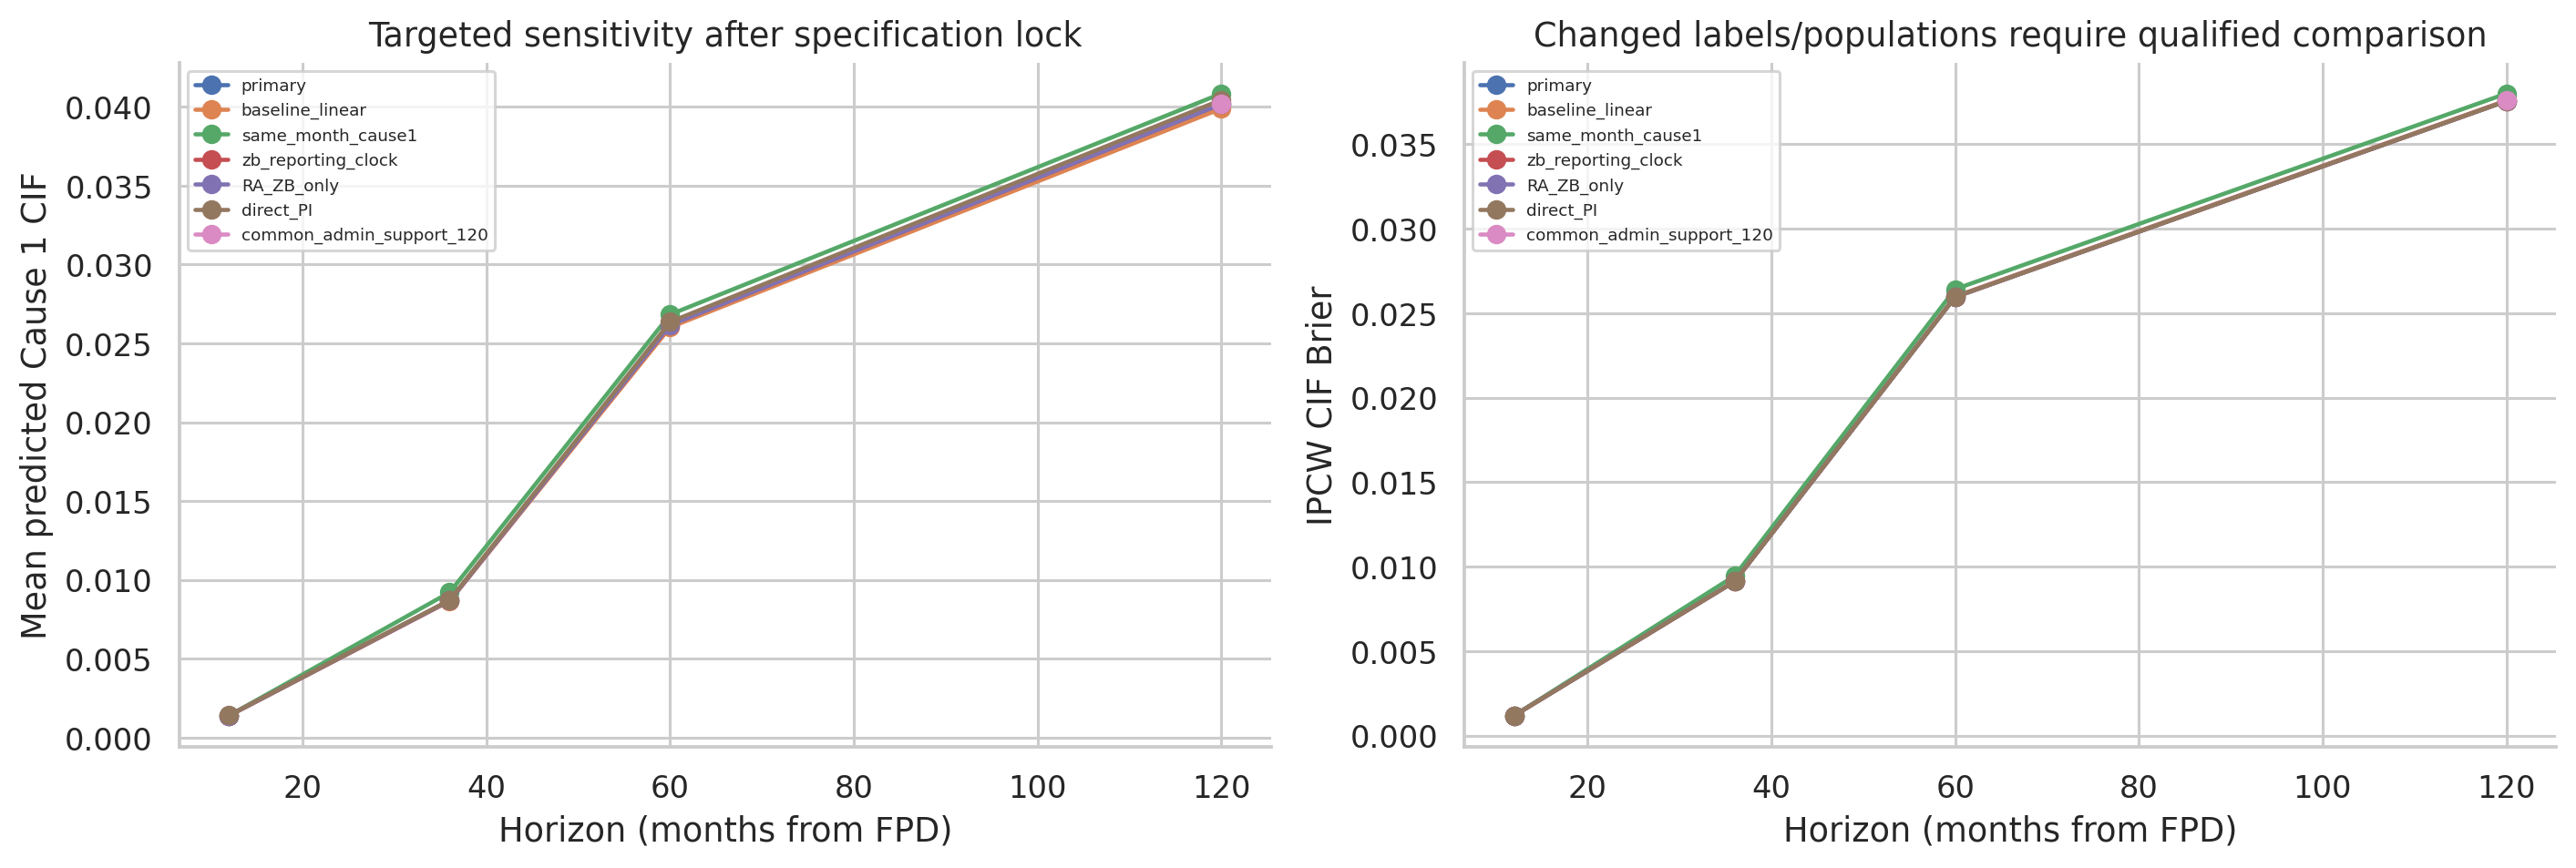

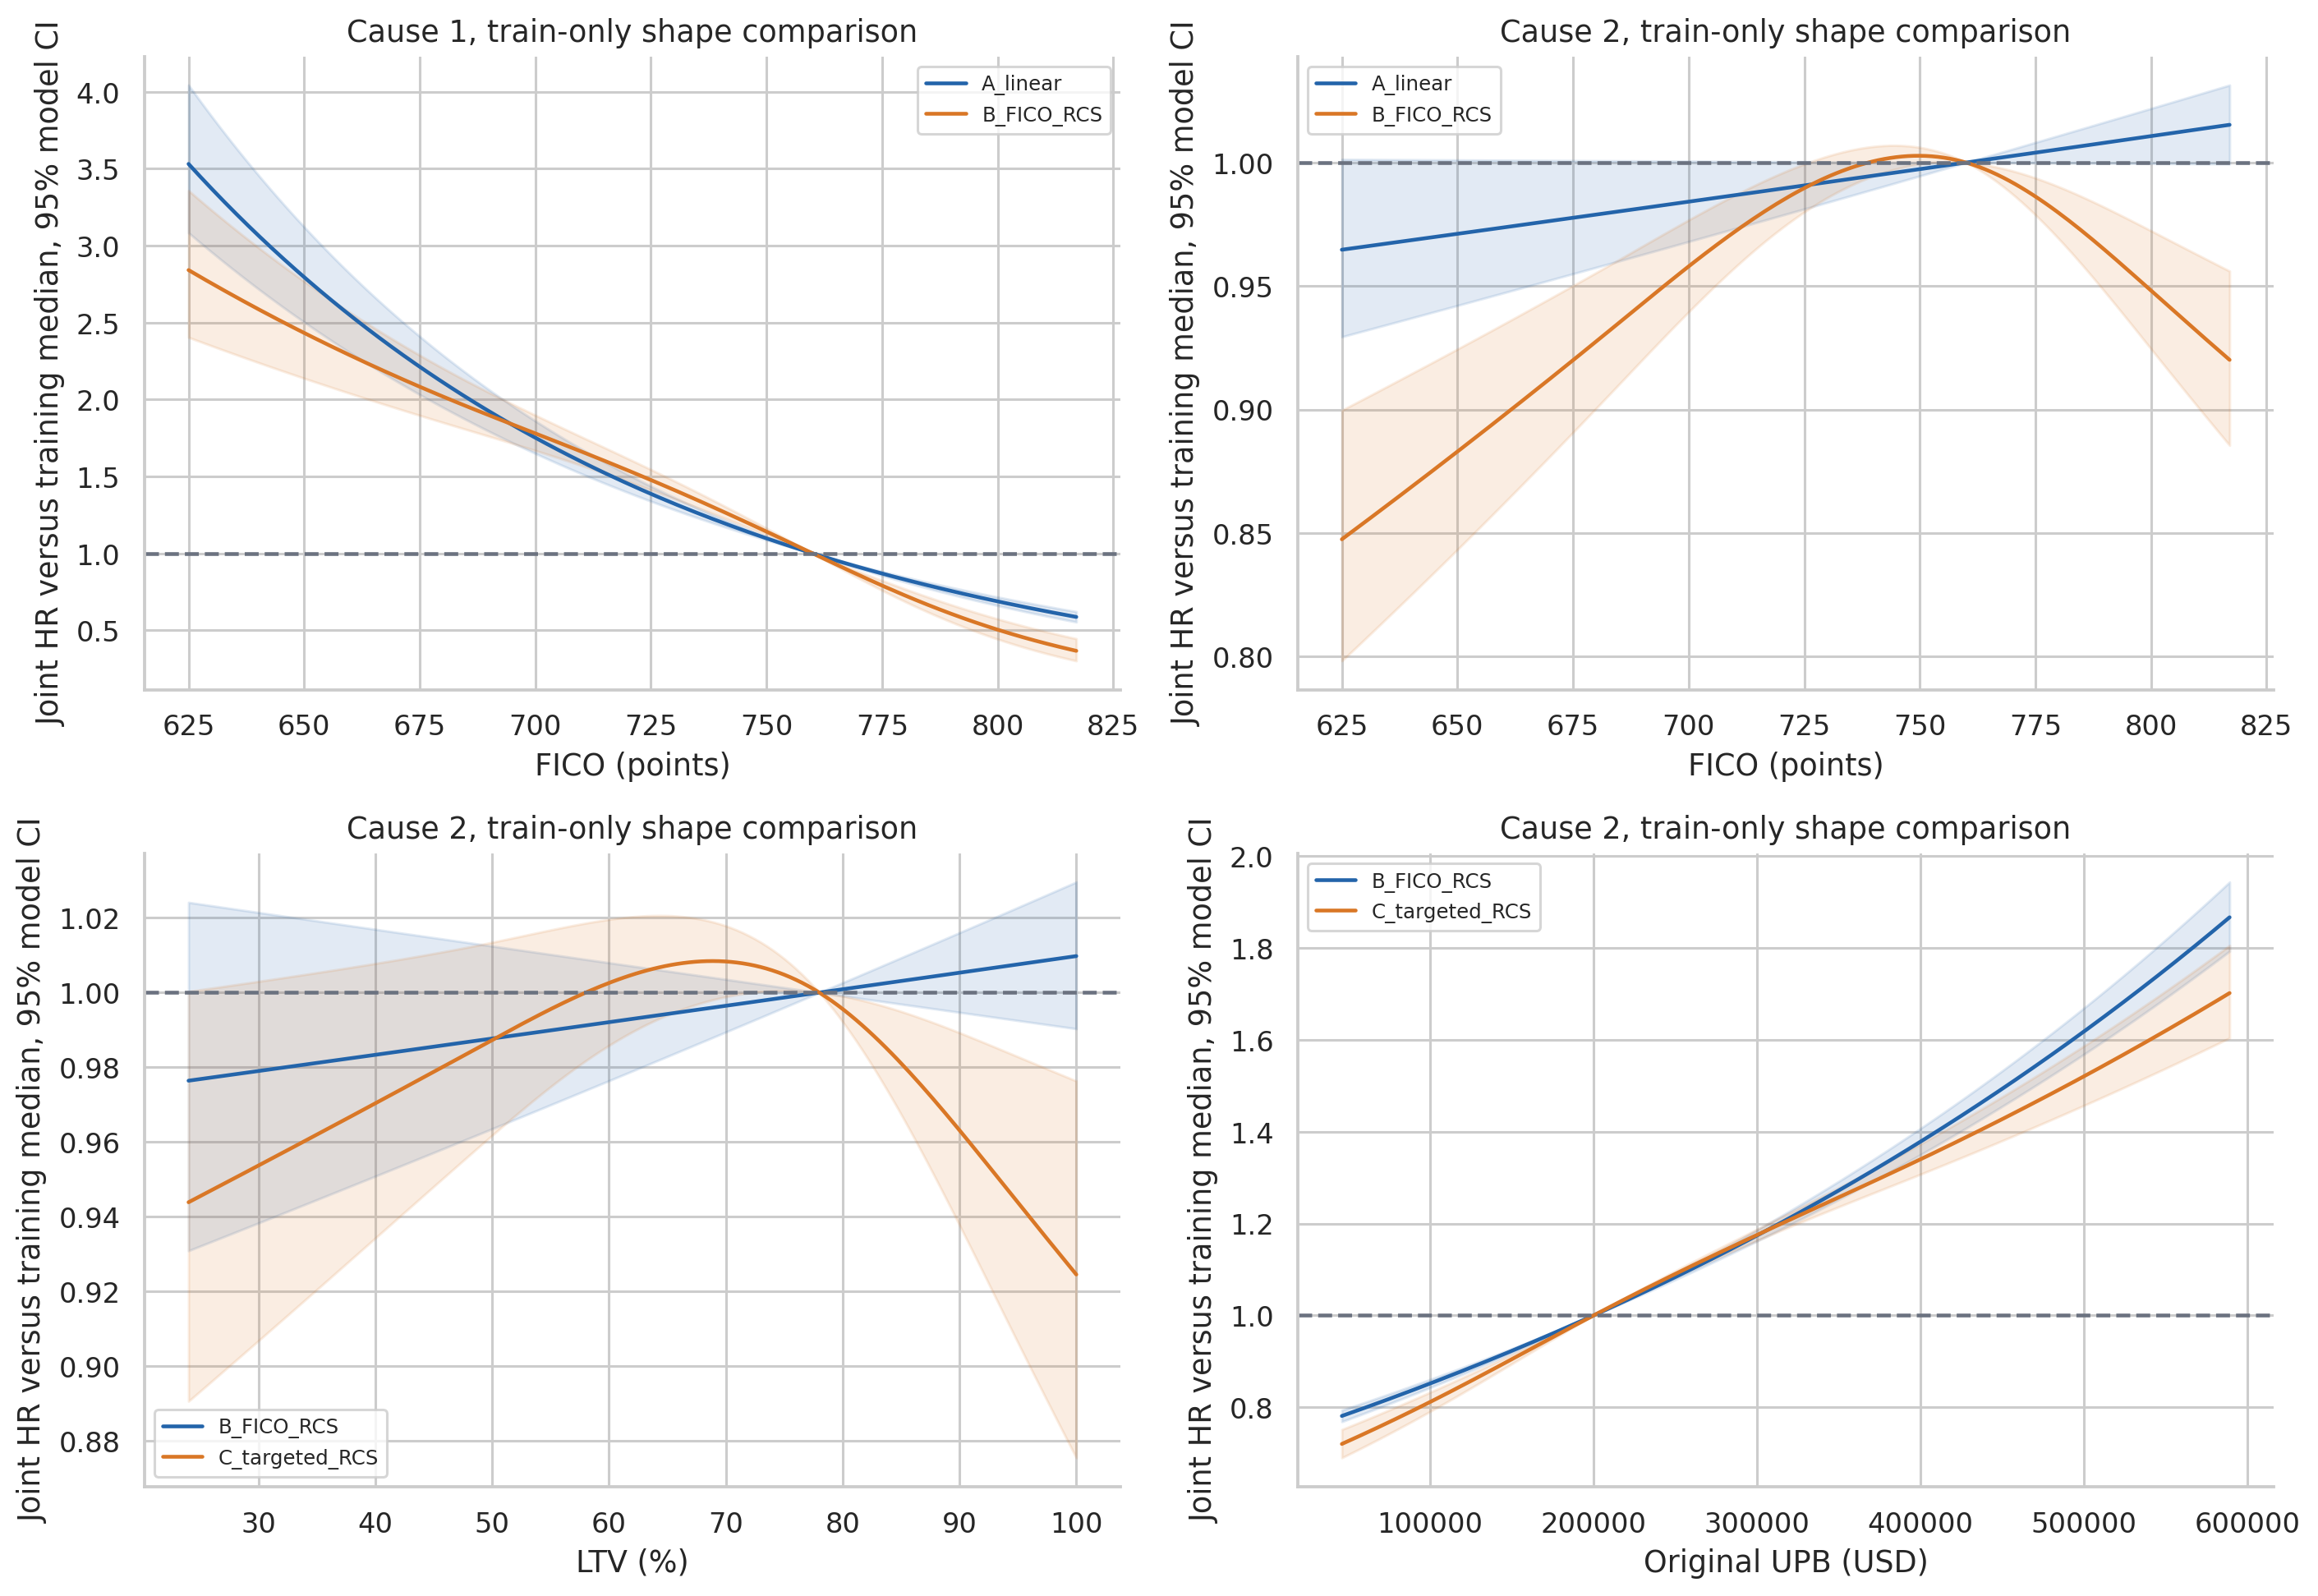

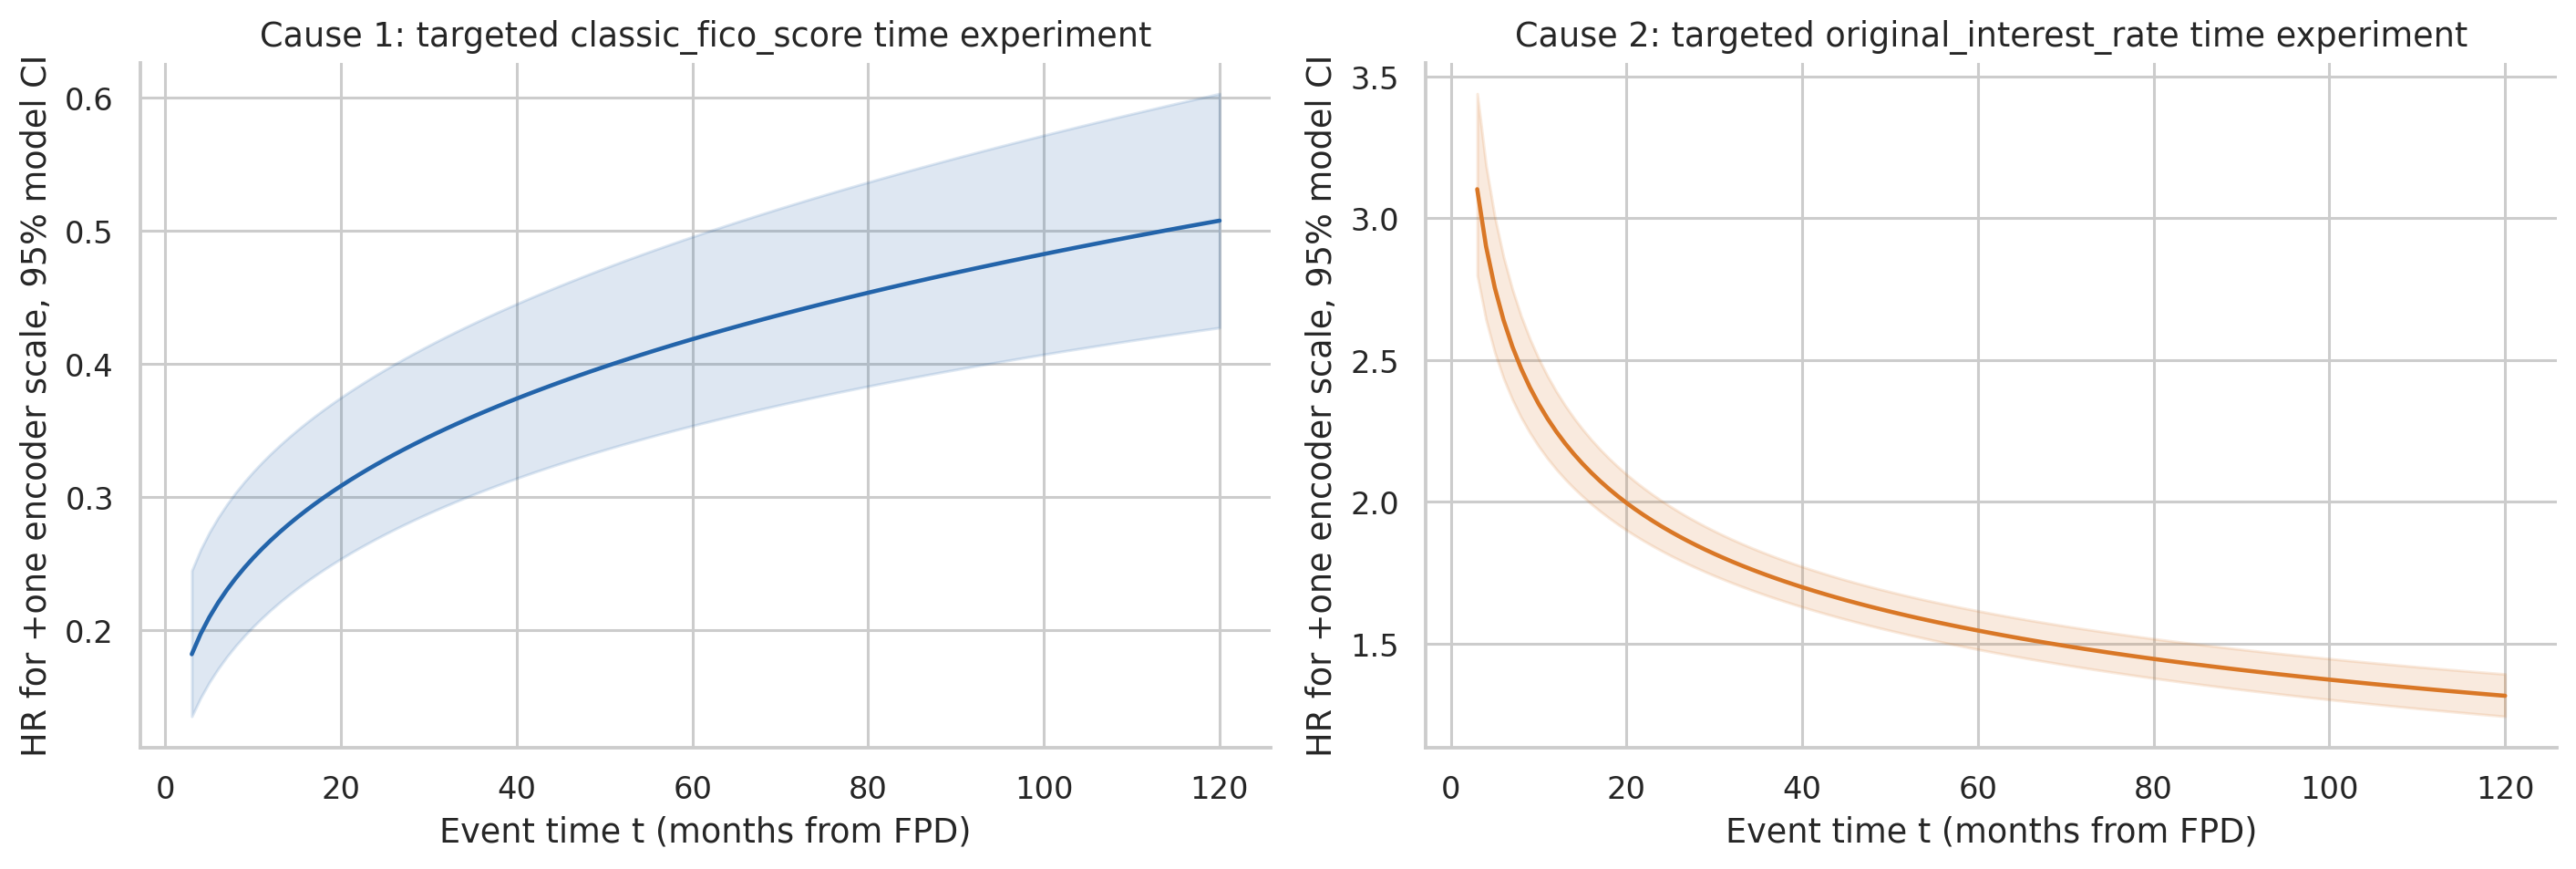

Shape/time curves dùng fitted coefficients và covariance thật. Khoảng hiển thị shape là train 1–99th percentiles; không extrapolate đến unsupported tails. Time candidates có HR variation nhưng không được giữ vì không đạt predictive/internal-validation criteria; residual non-PH của working model vẫn là limitation. Sensitivity point estimates không có paired CI riêng, trừ baseline-versus-final Brier đã báo; không dùng các chênh lệch nhỏ để xếp hạng scientific validity.

In [21]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for name,g in sensitivity.groupby('scenario',sort=False):
    axes[0].plot(g.horizon,g.mean_predicted,marker='o',label=name)
    axes[1].plot(g.horizon,g.brier,marker='o',label=name)
axes[0].set(xlabel='Horizon (months from FPD)',ylabel='Mean predicted Cause 1 CIF',title='Targeted sensitivity after specification lock')
axes[1].set(xlabel='Horizon (months from FPD)',ylabel='IPCW CIF Brier',title='Changed labels/populations require qualified comparison')
for ax in axes:ax.legend(fontsize=6)
save_figure(fig,'sensitivity')
shape_settings=[(1,'classic_fico_score','B_FICO_RCS'),(2,'classic_fico_score','B_FICO_RCS'),
                (2,'original_ltv','C_targeted_RCS'),(2,'original_upb','C_targeted_RCS')]
fig,axes=plt.subplots(2,2,figsize=(13,9))
for ax,(k,variable,alternative) in zip(axes.flat,shape_settings):
    values=np.linspace(*train[variable].quantile([.01,.99]),150)
    baseline_shape='A_linear' if variable=='classic_fico_score' else 'B_FICO_RCS'
    for name,color in [(baseline_shape,BLUE),(alternative,ORANGE)]:
        item=development['candidates'][name]
        curve=hazard_contrasts(item['models'][k],item['encoder'],variable,values)
        ax.plot(curve.value,curve.HR,label=name,color=color)
        ax.fill_between(curve.value,curve.low,curve.high,color=color,alpha=.13)
    ax.axhline(1,color=GRAY,ls='--')
    ax.set(xlabel=labels[variable],ylabel='Joint HR versus training median, 95% model CI',title=f'Cause {k}, train-only shape comparison');ax.legend(fontsize=8)
save_figure(fig,'fico_functional_form')
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for k,variable,ax in [(1,'classic_fico_score',axes[0]),(2,'original_interest_rate',axes[1])]:
    candidate=time_development['alternatives'][k]
    value=encoder.medians[variable]+encoder.continuous[variable]
    curves=pd.concat([hazard_contrasts(candidate,encoder,variable,[value],t) for t in range(3,121)],ignore_index=True)
    ax.plot(curves.time,curves.HR,color=BLUE if k==1 else ORANGE)
    ax.fill_between(curves.time,curves.low,curves.high,color=BLUE if k==1 else ORANGE,alpha=.15)
    ax.set(xlabel='Event time t (months from FPD)',ylabel='HR for +one encoder scale, 95% model CI',title=f'Cause {k}: targeted {variable} time experiment')
save_figure(fig,'time_effects')
say('Shape/time curves dùng fitted coefficients và covariance thật. Khoảng hiển thị shape là train 1–99th percentiles; không extrapolate đến unsupported tails. '
    'Time candidates có HR variation nhưng không được giữ vì không đạt predictive/internal-validation criteria; residual non-PH của working model vẫn là limitation. '
    'Sensitivity point estimates không có paired CI riêng, trừ baseline-versus-final Brier đã báo; không dùng các chênh lệch nhỏ để xếp hạng scientific validity.')


## 21–23. Tổng hợp và giới hạn của final working specification

Kết quả được tính từ raw của chính lần chạy này. Model selection chỉ dùng train; reused holdout phục vụ mô tả cuối. Tách statistical association, hazard discrimination, CIF ranking, probability calibration và external generalization.

In [22]:
m60=metrics.loc[metrics.horizon.eq(60)].iloc[0];m120=metrics.loc[metrics.horizon.eq(120)].iloc[0]
say(f"""**Thiết kế được chọn.** Cohort {len(cohort):,}; Cause 1/2/0={int(cohort.J.eq(1).sum()):,}/{int(cohort.J.eq(2).sum()):,}/{int(cohort.J.eq(0).sum()):,}. Functional specification **{functional_choice}**, time choice **{time_development['selected']}**. FICO knots học trên train: {encoder.spline_knots.get('classic_fico_score',[])}. Không giữ targeted LTV/UPB spline/time effects chỉ vì LR p nhỏ; OOF/predictive criteria và parsimony được áp dụng trước test.

**Discrimination.** Cause-specific C-index {c_result['c_index']:.3f} (95% fixed-model test CI {c_result['low']:.3f}–{c_result['high']:.3f}); CIF AUC theo từng horizon đã được báo riêng. Các quantities này khác estimand. Không có external validation.

**Calibration/error.** 60 tháng, mean predicted F1={m60.mean_predicted:.2%} so với AJ={m60.observed_AJ:.2%}; Brier={m60.brier:.6f}, train-AJ benchmark={m60.benchmark_brier:.6f}. 120 tháng, các risks={m120.mean_predicted:.2%}/{m120.observed_AJ:.2%}, Brier={m120.brier:.6f}/{m120.benchmark_brier:.6f}. Slopes tại các mốc dài vẫn >1; mean gần AJ không bảo đảm calibration toàn risk range. Baseline-final paired Brier CI có trong bảng, không suy superiority chỉ từ point estimate.

**Ứng dụng dự báo.** individual_predictions.csv chứa {len(individual):,} dòng cho {individual.loan_identifier.nunique():,} common-origin loans, horizons 12/36/60/120, F1/F2/S và rank. Training predictions không được gọi independent validation; 2.736 late entrants không có ranking từ FPD này.

**Diễn giải khoa học.** Giữ study direction và cause-specific framework; RCS giải quyết một phần functional-form misspecification. Remaining non-PH hạn chế HR cố định và CIF specification. Đây là mô hình nghiên cứu của observed disclosure cohort, không là lifetime default/loss/causal model hoặc công cụ tín dụng đã được external validate.""")


**Thiết kế được chọn.** Cohort 49,980; Cause 1/2/0=2,019/37,305/10,656. Functional specification **B_FICO_RCS**, time choice **static**. FICO knots học trên train: [683.0, 760.0, 803.0]. Không giữ targeted LTV/UPB spline/time effects chỉ vì LR p nhỏ; OOF/predictive criteria và parsimony được áp dụng trước test.

**Discrimination.** Cause-specific C-index 0.766 (95% fixed-model test CI 0.748–0.786); CIF AUC theo từng horizon đã được báo riêng. Các quantities này khác estimand. Không có external validation.

**Calibration/error.** 60 tháng, mean predicted F1=2.62% so với AJ=2.75%; Brier=0.025962, train-AJ benchmark=0.026740. 120 tháng, các risks=4.02%/4.06%, Brier=0.037562/0.038919. Slopes tại các mốc dài vẫn >1; mean gần AJ không bảo đảm calibration toàn risk range. Baseline-final paired Brier CI có trong bảng, không suy superiority chỉ từ point estimate.

**Ứng dụng dự báo.** individual_predictions.csv chứa 188,976 dòng cho 47,244 common-origin loans, horizons 12/36/60/120, F1/F2/S và rank. Training predictions không được gọi independent validation; 2.736 late entrants không có ranking từ FPD này.

**Diễn giải khoa học.** Giữ study direction và cause-specific framework; RCS giải quyết một phần functional-form misspecification. Remaining non-PH hạn chế HR cố định và CIF specification. Đây là mô hình nghiên cứu của observed disclosure cohort, không là lifetime default/loss/causal model hoặc công cụ tín dụng đã được external validate.

Những giới hạn còn lại:

- First observed numeric 90+ trước broader RA/ZB exit khác first lifetime delinquency, default, loss hoặc regulatory PD. Không suy RA đã có numeric 90+.
- Lịch sử trước acquisition và gap chưa được quan sát; independent truncation/censoring chưa được chứng minh. FPD field có exceptions, không luôn là origination ban đầu.
- Coarsened monthly data không cho thứ tự ngày. Cause 2 priority/clock sensitivities chỉ kiểm tra một phần time ambiguity.
- **PH vẫn bị vi phạm sau RCS.** Time experiments có HR variation nhưng không cải thiện OOF và không đạt practical-CIF rule; giữ parsimonious working model là quyết định prediction-focused, không xác nhận HR thật hằng.
- DTI missing gần như structural/HARP; median+indicator không phải MICE; reference gộp modal/rare/unseen. Missing-indicator support rule dùng training outcomes, không test.
- Primary absolute-risk metrics/ranking chỉ cho L=0. Landmark 12 là conditional target khác; không khái quát cho mọi late entrant.
- Marginal reverse KM cần censoring assumptions; common-support 120 là population khác. Zero-event bootstrap boundary đã được xử lý theo known/unknown horizon status.
- 200 fixed-model test bootstrap không gồm training/knots/model-selection uncertainty. 3-fold paired SE là selection heuristic, không formal inferential CI.
- Test được tái sử dụng sau research/audit; revised comparisons trên nó là descriptive/exploratory internal evaluation. Không gọi random resplit là external information.
- Một vintage không chứng minh generalization qua vintage, macro regime hoặc population. Không chuyển ranking thành credit decision recommendation.

P1–P6 được thực hiện tuần tự theo execution-policy update; từng checkpoint vẫn ghi đầy đủ. P6 verification xác nhận chạy/tests/artifacts, không xác nhận các assumptions không quan sát được.

## 24. Tài liệu tham khảo và tái lập

1. Freddie Mac, workbook **Sample 2015 Data Dictionary Release 47**, ba file local trong `data/`; vị trí cột/sentinel dùng cho implementation.
2. [Freddie Mac — General User Guide](https://www.freddiemac.com/fmac-resources/research/pdf/user_guide.pdf). Đối chiếu interpreting data, reporting cycles, Zero Balance và delinquency; web trả Release 48 (10/2026), truy cập 14/11/2026. Không tự đổi schema Release 47 của dữ liệu local.
3. [van Geloven et al. (2022), Validation of prediction models in the presence of competing risks](https://www.bmj.com/content/377/bmj-2021-069249). AJ cho observed incidence; calibration, discrimination và CIF Brier phải tính competing events/censoring.
4. [Efthimiou et al. (2024), Developing clinical prediction models: a step-by-step guide](https://pmc.ncbi.nlm.nih.gov/articles/PMC11369751/). Pre-specification, missing data, split và uncertainty. Áp dụng nguyên tắc thống kê, không chuyển diễn giải lâm sàng thành PD tín dụng.
5. [statsmodels PHReg 0.14.4](https://www.statsmodels.org/v0.14.4/generated/statsmodels.duration.hazard_regression.PHReg.html). Public API cho delayed entry/Breslow; baseline và diagnostics được tính/đối chiếu rõ.
6. [Grambsch & Therneau (1994), Proportional hazards tests and diagnostics based on weighted residuals](https://doi.org/10.1093/biomet/81.3.515). Cơ sở residual và time-weighted score diagnostics.
7. [SAS PHREG — weighted residuals](https://support.sas.com/documentation/cdl/en/statug/63033/HTML/default/statug_phreg_a0000000693.htm). Định nghĩa scaled Schoenfeld, score residual và one-step influence.

Các nguồn được dùng để kiểm tra lựa chọn phương pháp, không để nhập code hay kết quả số. Formula/assumptions cụ thể của implementation được ghi tại mỗi phần và trong analysis contract.

8. [Harrell — Regression Modeling Strategies](https://hbiostat.org/course/rms/index.html): restricted cubic splines, linear tails và df; implementation kiểm tra với independent natural-cubic interpolant.
9. [R survival — survfit.coxph](https://www.stat.ethz.ch/R-manual/R-devel/library/survival/html/survfit.coxph.html): direct versus exponential/matrix-exponential constructions, khác nhau ở finite monthly jumps.

In [23]:
packages=['numpy','pandas','scipy','matplotlib','seaborn','statsmodels','openpyxl','nbformat','nbclient','ipykernel','nbconvert','ipython']
required_tables=['cohort_flow','cohort_exclusions','descriptive_statistics','cox_coefficients','ph_score_tests',
 'functional_form_scores','cause_specific_concordance','primary_validation','primary_calibration',
 'landmark12_validation','sensitivity_coefficients','sensitivity_cohort_changes','sensitivity_metrics',
 'individual_predictions','hazard_contrasts','model_development_comparison']
all_prob=predict_cif(models,encoder.transform(cohort.loc[cohort.L.eq(0)]),[12,36,60,120])
checks={'one_row_per_loan':bool(cohort.index.is_unique),'strict_entry_exit':bool((cohort.L<cohort['T']).all()),
 'train_test_disjoint':not bool(set(train.index)&set(test.index)),
 'train_only_preprocessing':encoder.training_ids==train.index.tolist(),
 'finite_coefficients':all(bool(np.isfinite(m.beta).all()) for m in models.values()),
 'converged_scores':all(m.max_abs_score<1e-3 for m in models.values()),
 'probability_sum':bool(np.max(np.abs(all_prob.sum(axis=2)-1))<1e-10),
 'monotone_cif':bool((np.diff(all_prob[:,:,:2],axis=1)>=-1e-12).all()),
 'raw_copies_match':all(row['matches_supplied_original'] for row in source_checks),
 'no_selection_on_legacy_test':not development['legacy_test_used'] and not time_development['legacy_test_used']}
assert all(checks.values())
manifest={'run_utc':datetime.now(timezone.utc).isoformat(),'seed_split':SEED,'seed_bootstrap':20261115,
 'bootstrap_replicates':200,'python':platform.python_version(),'versions':{p:version(p) for p in packages},
 'raw_files':audit['files'],'source_code_sha256':{p.name:sha256(p) for p in (ROOT/'src').glob('*.py')},
 'n_raw':len(orig),'n_cohort':len(cohort),'n_train':len(train),'n_test':len(test),
 'cause_counts':{str(k):int(v) for k,v in cohort.J.value_counts().items()},
 'cause2_source_counts':cohort.loc[cohort.J.eq(2),'event_source'].value_counts().to_dict(),
 'entry_late':int(cohort.L.gt(0).sum()),'fit_warnings':{str(k):m.warnings for k,m in models.items()},
 'specification':{'functional':functional_choice,'time':time_development['selected'],
                  'parameters':{str(k):len(m.beta) for k,m in models.items()},'knots':encoder.spline_knots},
 'selection_locked_before_holdout_UTC':selection_locked_utc,
 'holdout_label':'reused internal holdout; final descriptive evaluation',
 'checks':checks,'figures':len(FIGURES),'required_tables':required_tables,
 'individual_prediction_scope':'all cohort L=0, training/holdout labels, no cross-entry ranking'}
(ROOT/'artifacts/run_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
bundle={'cohort':cohort,'train_ids':train.index.tolist(),'test_ids':test.index.tolist(),
 'encoder':encoder,'models':models,'development':development,'time_development':time_development,
 'diagnostics':diag,'functional':functional,'validation':validation,'landmark':landmark,
 'baseline_validation':baseline_validation,'baseline_final_paired_Brier':baseline_final_paired_Brier,
 'concordance':c_result,'c_bootstrap':c_draws,'sensitivity_metrics':sensitivity,
 'sensitivity_models':sensitivity_models,'cohort_exclusions':exclusions,
 'cif_integration_sensitivity':cif_integration_sensitivity,'administrative_support_sensitivity':common,
 'baseline_archive':'artifacts/baseline_bundle.pkl','stage':'P6','primary_status':'final working specification; limitations disclosed'}
with (ROOT/'artifacts/research_bundle.pkl').open('wb') as f:pickle.dump(bundle,f,protocol=pickle.HIGHEST_PROTOCOL)
table(pd.DataFrame([c_result]),'cause_specific_concordance')
assert all((ROOT/f['path']).exists() for f in figure_manifest)
assert all((TABLES/(name+'.csv')).exists() for name in required_tables)
display(pd.Series(manifest['versions'],name='version').to_frame())
say('Đã tính từ raw đến các kết quả final working model. Export HTML, unit tests và final notebook/artifact hashes do versioned src/reproduce.py thực hiện sau khi notebook được save; verification cũ không được dùng làm bằng chứng cho lần chạy mới.')


,version
numpy,1.26.4
pandas,2.2.2
scipy,1.14.1
matplotlib,3.9.2
seaborn,0.13.2
statsmodels,0.14.4
openpyxl,3.1.2
nbformat,5.10.4
nbclient,0.10.2
ipykernel,6.29.5


Đã tính từ raw đến các kết quả final working model. Export HTML, unit tests và final notebook/artifact hashes do versioned src/reproduce.py thực hiện sau khi notebook được save; verification cũ không được dùng làm bằng chứng cho lần chạy mới.